<div align="center">

# Proyecto Integrador de Ciencia de Datos
## Fase 3 (actividades 5 y 6) · Modelado avanzado, clustering, optimización e interpretabilidad

### ¿Cuál es la energía renovable con mejor desempeño integral?
#### Modelos regularizados, ensambles de árboles, perceptrón multicapa en PyTorch y segmentación no supervisada con la *Global Power Plant Database* (WRI)

**Carolina Rodríguez Chacón** · carodriguez03@unisalle.edu.co<br>
Maestría en Inteligencia Artificial · Facultad de Ingeniería · **Universidad de La Salle**<br>
**Curso:** 2026-2_Ciencia de Datos_G2 · **Docente:** Fabián Camilo Castro Riveros<br>
**Actividades del aula:** Fase 3, actividades 5 y 6 – Modelos avanzados y ajuste de hiperparámetros; evaluación comparativa e interpretabilidad (Entregable 3, 25 %)<br>
**Fecha de elaboración:** noviembre de 2026

</div>

---

### Qué es este cuaderno

Este cuaderno acompaña al informe de la Fase 3 y **reproduce todas sus tablas y figuras** con el mismo número. Contiene solo el trabajo de la Fase 3. El planteamiento y el análisis exploratorio están en el Entregable 1 (Fase 1), y la limpieza, la partición y los modelos base, en el Entregable 2 (Fase 2). La sección 0 reconstruye ese punto de partida con el mismo código y la misma semilla, y **verifica** que coincide con lo entregado: mismos tamaños de los conjuntos y mismo umbral en prueba.

Es reproducible de principio a fin: si los datos no están en `data/raw/`, los descarga de los repositorios oficiales (WRI e IRENA), verifica la huella SHA-256 del archivo principal y usa `SEMILLA = 42` en todos los modelos, incluida la red neuronal. Funciona igual en Google Colab y en Jupyter local. La ejecución completa tarda entre 20 y 30 minutos en un computador personal; casi todo el tiempo lo consumen las búsquedas de hiperparámetros.

| Informe | Contenido | Sección del cuaderno |
|---|---|---|
| — | Punto de partida: datos, partición y umbral de la Fase 2 (verificados) | 0 |
| Sección II | Protocolo de la Fase 3 y ampliación de predictores | 1 |
| Sección III-A y Tablas I–II | Regresión del factor de planta: regularizados, ensambles y MLP en PyTorch (Actividad 5) | 2 |
| Secciones III-A y III-B, Tabla III y Figs. 1–2 | Clasificación del nivel de desempeño: cuatro algoritmos; curvas de pérdida de la MLP (Actividad 5) | 3 |
| Sección III-C, Tabla IV y Fig. 3 | Clustering: K-Means, jerárquico aglomerativo y DBSCAN (Actividad 5) | 4 |
| Secciones III-D a III-G, Tablas V–VII y Figs. 4–5 | Evaluación en prueba, robustez, errores por región e interpretabilidad (Actividad 6) | 5 |
| Secciones III-H a III-J, Tablas VIII–X y Fig. 6 | Evaluación integral: trayectoria 2000–2025, análisis multicriterio, fin de vida (reciclaje) y productividad (energía por MW, por dólar, por terreno y por material) | 6 |
| Sección IV | Respuesta a las preguntas de investigación | 7 |
| — | Auditoría de fuga, artefactos y hallazgos | 8–10 |
| Secciones V–VI | Limitaciones y referencias | 11–12 |

# 0. Punto de partida: datos, partición y umbral de la Fase 2

La Fase 3 entrena modelos sobre **exactamente** la misma partición de la Fase 2 (70/15/15, estratificada por tecnología y nivel, y agrupada por sitio) y con el mismo *pipeline* de preprocesamiento. Para que el cuaderno sea autónomo, esta sección rehace esos pasos con el código de las fases anteriores, sin repetir sus análisis ni sus justificaciones, que ya se entregaron:

| Paso | Decisión tomada en la fase anterior | Dónde se justificó |
|---|---|---|
| Factor de planta (FP) válido | $0 < FP \le 1$, año completo posterior a la puesta en marcha, sin bombeo; objetivo = promedio 2013–2019 | Fase 1, §4.2 |
| Objetivo sin imputar | Su ausencia es MAR (depende del país) con posible componente MNAR | Fase 1, §5.2 |
| Plausibilidad física | Solar ≤ 0.40, eólica ≤ 0.65, FP ≥ 0.01: se retiran 20 plantas | Fase 2, §2.2 |
| Sitios compartidos | Plantas con iguales coordenadas (4 decimales) y tecnología forman un sitio y caen en el mismo conjunto | Fase 2, §2.4 |
| Variables derivadas | log₁₀ de la capacidad, edad, irradiación relativa cos(lat) y densidad de plantas a 100 km | Fase 2, §3 |
| Imputación | KNN con k = 20 e indicador de falta, elegido por un experimento de enmascaramiento | Fase 2, §5.2 |
| Codificación y escala | One-Hot de la tecnología, Target Encoding del país con *cross-fitting*, winsorización p0.5–p99.5 y estandarización, todo ajustado con entrenamiento | Fase 2, §5.3–5.5 |
| Clases | Terciles del FP calculados con entrenamiento: Bajo ≤ 0.205 < Medio ≤ 0.323 < Alto | Fase 2, §6 |

Al final de la sección se comprueba que la reconstrucción reproduce el umbral mínimo de la Fase 2 en prueba: **R² = 0.449** (regresión lineal) y **F1-macro = 0.671** (regresión logística).

### 0.1 Librerías, semilla y estilo

In [1]:
# ---------------------------------------------------------------------------
# Librerías y configuración general de la Fase 3
# ---------------------------------------------------------------------------
import hashlib
import json
import logging
import platform
import time
import urllib.request
import warnings
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap
import scipy
from scipy import stats
from scipy.cluster.hierarchy import dendrogram, linkage
import sklearn
from sklearn.base import BaseEstimator, ClassifierMixin, RegressorMixin, TransformerMixin, clone
from sklearn.cluster import DBSCAN, AgglomerativeClustering, KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.impute import KNNImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import ElasticNet, Lasso, LinearRegression, LogisticRegression, Ridge
from sklearn.metrics import (accuracy_score, adjusted_rand_score, confusion_matrix, f1_score, mean_absolute_error,
                             mean_squared_error, precision_score, r2_score, recall_score, roc_auc_score, roc_curve,
                             silhouette_score)
from sklearn.model_selection import (GridSearchCV, GroupKFold, RandomizedSearchCV, StratifiedGroupKFold,
                                     cross_val_score, learning_curve, train_test_split)
from sklearn.neighbors import BallTree, NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder
from sklearn.svm import SVC
import torch
import torch.nn as nn
import xgboost
from xgboost import XGBClassifier, XGBRegressor
import joblib

from IPython.display import Markdown, display

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

SEMILLA = 42                                  # semilla única: partición, búsquedas, árboles y red neuronal
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)
torch.set_num_threads(max(1, min(4, torch.get_num_threads())))

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

# --- Estilo de gráficos (el mismo de las fases 1 y 2) ---
TINTA, TINTA2, TENUE = "#0b0b0b", "#52514e", "#898781"
GRIS, RETICULA, SUPERFICIE = "#c3c2b7", "#e1e0d9", "#fcfcfb"
AZUL, ROJO = "#2a78d6", "#e34948"
plt.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE, "savefig.facecolor": SUPERFICIE,
    "axes.edgecolor": GRIS, "axes.labelcolor": TINTA2, "axes.titlecolor": TINTA,
    "xtick.color": TENUE, "ytick.color": TENUE, "xtick.labelcolor": TINTA2, "ytick.labelcolor": TINTA2,
    "text.color": TINTA, "axes.grid": True, "grid.color": RETICULA, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans", "Arial"],
    "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.labelsize": 10, "legend.frameon": False,
    "legend.fontsize": 9, "figure.dpi": 100, "lines.linewidth": 2,
})

MAPA_TEC = {"Solar": "Solar", "Wind": "Eólica", "Hydro": "Hidroeléctrica",
            "Geothermal": "Geotérmica", "Biomass": "Biomasa", "Wave and Tidal": "Mareomotriz/undimotriz"}
TEC_ORDEN = list(MAPA_TEC.values())
TEC_MODELO = TEC_ORDEN[:5]                    # la mareomotriz no tiene generación reportada
TEC_COLOR = {"Solar": "#eda100", "Eólica": "#1baf7a", "Hidroeléctrica": "#2a78d6",
             "Geotérmica": "#e34948", "Biomasa": "#008300"}
TEC_CORTA = {"Solar": "Solar", "Eólica": "Eólica", "Hidroeléctrica": "Hidro.", "Geotérmica": "Geot.", "Biomasa": "Biom."}
CMAP_SEQ = LinearSegmentedColormap.from_list("seq_azul", ["#f4f8fd", "#9ec5f4", "#3987e5", "#1c5cab", "#0d366b"])
CMAP_DIV = LinearSegmentedColormap.from_list("div", ["#1c5cab", "#86b6ef", "#f0efec", "#f0a3a2", "#b8302f"])
NIVELES = ["Bajo", "Medio", "Alto"]
ORDEN_CONJ = ["entrenamiento", "validación", "prueba"]
ANIO_REFERENCIA = 2019

# --- Formato de las figuras del informe: ancho de una columna IEEE (3.45 pulgadas) ---
ESTILO_INFORME = {
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "DejaVu Sans"], "font.size": 7,
    "axes.labelsize": 7, "xtick.labelsize": 6.5, "ytick.labelsize": 6.5, "legend.fontsize": 6.5,
    "axes.edgecolor": GRIS, "axes.labelcolor": TINTA, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "xtick.labelcolor": TINTA2, "ytick.labelcolor": TINTA2, "axes.titlecolor": TINTA, "text.color": TINTA,
    "axes.titlesize": 7, "axes.titleweight": "normal", "axes.grid": True, "grid.color": RETICULA,
    "grid.linewidth": 0.5, "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "lines.linewidth": 1.2, "figure.dpi": 170, "legend.frameon": False,
}
ANCHO_COLUMNA = 3.45

RAIZ = Path("..") if Path("../data").exists() else Path(".")        # carpeta notebooks/ o Colab
DIR_FIG3 = RAIZ / "reports" / "figuras_fase3"
DIR_MOD = RAIZ / "models"
DIR_PROC = RAIZ / "data" / "processed"
for carpeta in (DIR_FIG3, DIR_MOD, DIR_PROC):
    carpeta.mkdir(parents=True, exist_ok=True)


def guardar_fig3(fig, nombre):
    # Las figuras del informe se guardan siempre (también en Colab)
    fig.savefig(DIR_FIG3 / nombre, dpi=220, bbox_inches="tight")


def titulo_panel(ax, texto):
    ax.set_title(texto, loc="left", fontsize=7, color=TINTA)


print(f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | scipy {scipy.__version__} | "
      f"scikit-learn {sklearn.__version__} | xgboost {xgboost.__version__} | torch {torch.__version__} | "
      f"matplotlib {matplotlib.__version__}")

Python 3.13.3 | pandas 2.2.3 | numpy 2.2.5 | scipy 1.15.2 | scikit-learn 1.7.0 | xgboost 3.1.2 | torch 2.7.0+cpu | matplotlib 3.10.1


### 0.2 Descarga y verificación de los datos

In [2]:
URL_ZIP = "https://wri-dataportal-prod.s3.amazonaws.com/manual/global_power_plant_database_v_1_3.zip"
SHA256_ESPERADO = "4b1f93e0fd93664f18684d9b05d0a52ed9658c6a8cf0d21ff2520791379ba7fc"
DIR_RAW = RAIZ / "data" / "raw" / "gppd_v1_3"
RUTA_CSV = DIR_RAW / "global_power_plant_database.csv"

if not RUTA_CSV.exists():
    DIR_RAW.mkdir(parents=True, exist_ok=True)
    ruta_zip = DIR_RAW.parent / "gppd_v1_3.zip"
    print("Descargando la GPPD v1.3.0 desde el repositorio del WRI ...")
    urllib.request.urlretrieve(URL_ZIP, ruta_zip)
    with zipfile.ZipFile(ruta_zip) as z:
        z.extract(RUTA_CSV.name, DIR_RAW)

df_raw = pd.read_csv(RUTA_CSV, low_memory=False, encoding="utf-8")
sha256 = hashlib.sha256(RUTA_CSV.read_bytes()).hexdigest()
assert sha256 == SHA256_ESPERADO, "El archivo no coincide con la versión usada en las fases 1 y 2"
print(f"SHA-256 verificado: {sha256}")
print(f"Dataset completo: {df_raw.shape[0]:,} filas × {df_raw.shape[1]} columnas")

SHA-256 verificado: 4b1f93e0fd93664f18684d9b05d0a52ed9658c6a8cf0d21ff2520791379ba7fc
Dataset completo: 34,936 filas × 36 columnas


### 0.3 Universo renovable e indicadores de la Fase 1

In [3]:
RENOVABLES = list(MAPA_TEC)
ANIOS = list(range(2013, 2020))
COLS_GEN = [f"generation_gwh_{a}" for a in ANIOS]


def construir_indicadores(d):
    # Mismo código de la Fase 1: factor de planta válido por año, promedio, estabilidad y variables geográficas
    d = d.copy()
    d["tecnologia"] = pd.Categorical(d["primary_fuel"].map(MAPA_TEC), categories=TEC_ORDEN)
    anio_op = np.floor(d["commissioning_year"])
    d["anio_operacion"] = anio_op
    d["posible_bombeo"] = d["name"].str.contains("pump", case=False, na=False) | (d[COLS_GEN] < 0).any(axis=1)
    fp = pd.DataFrame({a: d[f"generation_gwh_{a}"] / (d["capacity_mw"] * 8.76) for a in ANIOS}, index=d.index)
    anio_parcial = pd.DataFrame({a: anio_op.notna() & (anio_op >= a) for a in ANIOS}, index=d.index)
    valido = (fp.gt(0) & fp.le(1) & ~anio_parcial).apply(lambda col: col & ~d["posible_bombeo"])
    fp_valido = fp.where(valido)
    d["n_anios_generacion"] = fp_valido.notna().sum(axis=1)
    d["factor_planta_prom"] = fp_valido.mean(axis=1)
    d["cv_generacion"] = (fp_valido.std(axis=1, ddof=1) / fp_valido.mean(axis=1)).where(d["n_anios_generacion"] >= 3)
    d["tiene_generacion"] = d["n_anios_generacion"] > 0
    d["latitud_abs"] = d["latitude"].abs()
    return d


df = construir_indicadores(df_raw[df_raw["primary_fuel"].isin(RENOVABLES)].reset_index(drop=True))
print(f"Universo renovable: {len(df):,} plantas en {df['country'].nunique()} países | "
      f"con factor de planta válido: {df['tiene_generacion'].sum():,}")

Universo renovable: 24,794 plantas en 150 países | con factor de planta válido: 6,031


### 0.4 Conjunto de modelado y partición de la Fase 2

In [4]:
# --- Limpieza con reglas (Fase 2, §2) ---
d2 = df[(df["tecnologia"] != "Mareomotriz/undimotriz") & df["tiene_generacion"]]
LIMITE_SUPERIOR_FP = {"Solar": 0.40, "Eólica": 0.65}
limite_sup = d2["tecnologia"].astype(str).map(LIMITE_SUPERIOR_FP).fillna(1.0)
d3 = d2[(d2["factor_planta_prom"] <= limite_sup) & (d2["factor_planta_prom"] >= 0.01)].copy()
d3["sitio"] = d3.groupby([d3["latitude"].round(4), d3["longitude"].round(4), "tecnologia"], observed=True).ngroup()

# --- Variables derivadas deterministas (Fase 2, §3) ---
R_TIERRA_KM = 6371.0


def derivar_variables(d, universo, radio_km=100):
    d = d.copy()
    d["log_capacidad"] = np.log10(d["capacity_mw"])
    d["edad_planta"] = ANIO_REFERENCIA - d["anio_operacion"]
    d["irradiacion_relativa"] = np.cos(np.radians(d["latitude"]))
    d["densidad_misma_tec"] = np.nan
    for tec, grupo in d.groupby("tecnologia", observed=True):
        ref = universo[universo["tecnologia"] == tec]
        arbol = BallTree(np.radians(ref[["latitude", "longitude"]].values), metric="haversine")
        n = arbol.query_radius(np.radians(grupo[["latitude", "longitude"]].values), r=radio_km / R_TIERRA_KM, count_only=True)
        d.loc[grupo.index, "densidad_misma_tec"] = np.log1p(n - 1)
    return d


dm = derivar_variables(d3, df)
# Terciles descriptivos de la Fase 1 (todas las plantas con FP): solo sirven para estratificar la partición, como en la Fase 2
dm["nivel_desempeno"] = pd.qcut(df.loc[df["tiene_generacion"], "factor_planta_prom"], 3, labels=NIVELES).reindex(dm.index)


# --- Partición 70/15/15 estratificada y agrupada por sitio (Fase 2, §4) ---
def particionar(datos, semilla):
    tec = datos["tecnologia"].astype(str)
    estrato_completo = tec + " · " + datos["nivel_desempeno"].astype(str)
    minimo_por_tec = estrato_completo.value_counts().groupby(lambda e: e.split(" · ")[0]).min()
    tec_solo = minimo_por_tec.index[minimo_por_tec < 20]
    estrato = pd.Series(np.where(tec.isin(tec_solo), tec, estrato_completo), index=datos.index)
    estrato_sitio = estrato.groupby(datos["sitio"]).agg(lambda s: s.mode().iloc[0])
    s_ent, s_resto = train_test_split(estrato_sitio.index, test_size=0.30, stratify=estrato_sitio.values, random_state=semilla)
    s_val, s_pru = train_test_split(s_resto, test_size=0.50, stratify=estrato_sitio.loc[s_resto].values, random_state=semilla)
    return np.select([datos["sitio"].isin(s_pru), datos["sitio"].isin(s_val)], ["prueba", "validación"], default="entrenamiento")


dm["conjunto"] = particionar(dm, SEMILLA)
tamanos = dm["conjunto"].value_counts().reindex(ORDEN_CONJ)
assert tamanos.tolist() == [4202, 902, 907], "La partición no coincide con la de la Fase 2"
sitios = {c: set(dm.loc[dm["conjunto"] == c, "sitio"]) for c in ORDEN_CONJ}
assert not (sitios["entrenamiento"] & sitios["validación"]) and not (sitios["entrenamiento"] & sitios["prueba"]) \
       and not (sitios["validación"] & sitios["prueba"])
print(f"Conjunto de modelado: {len(dm):,} plantas | partición idéntica a la Fase 2: "
      + ", ".join(f"{c} {n:,}" for c, n in tamanos.items()) + " | ningún sitio en dos conjuntos")

Conjunto de modelado: 6,011 plantas | partición idéntica a la Fase 2: entrenamiento 4,202, validación 902, prueba 907 | ningún sitio en dos conjuntos


### 0.5 Preprocesamiento y objetivos

La única novedad respecto a la Fase 2 es la **ampliación de los predictores numéricos con la latitud y la longitud** (justificada en la sección 1). El resto del *pipeline* es el de la Fase 2: el preprocesamiento vive dentro de cada modelo y se reajusta en cada pliegue de validación cruzada, de modo que ninguna estadística de validación o de prueba llega al entrenamiento.

In [5]:
class Winsorizador(BaseEstimator, TransformerMixin):
    # Recorta cada columna a los percentiles [inferior, superior] estimados SOLO en el ajuste (entrenamiento)
    def __init__(self, inferior=0.005, superior=0.995):
        self.inferior, self.superior = inferior, superior

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        self.n_features_in_ = X.shape[1]
        self.lim_inf_, self.lim_sup_ = X.quantile(self.inferior).values, X.quantile(self.superior).values
        return self

    def transform(self, X):
        return pd.DataFrame(X, columns=self.feature_names_in_).clip(lower=self.lim_inf_, upper=self.lim_sup_, axis=1)

    def get_feature_names_out(self, input_features=None):
        return self.feature_names_in_


class Interacciones(BaseEstimator, TransformerMixin):
    # Productos tecnología × variable (la solar es la referencia); no estima parámetros
    def __init__(self, variables=("irradiacion_relativa", "edad_planta", "log_capacidad")):
        self.variables = variables

    def fit(self, X, y=None):
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        self.n_features_in_ = X.shape[1]
        self.dummies_ = [c for c in X.columns if c.startswith("tecnologia_")]
        return self

    def transform(self, X):
        X = X.copy()
        for d in self.dummies_:
            for v in self.variables:
                X[f"{d.removeprefix('tecnologia_')} × {v}"] = X[d] * X[v]
        return X

    def get_feature_names_out(self, input_features=None):
        nuevas = [f"{d.removeprefix('tecnologia_')} × {v}" for d in self.dummies_ for v in self.variables]
        return np.concatenate([self.feature_names_in_, nuevas])


VARS_NUM_F2 = ["log_capacidad", "irradiacion_relativa", "densidad_misma_tec", "edad_planta"]
VARS_NUM = VARS_NUM_F2 + ["latitude", "longitude"]          # predictores numéricos de la Fase 3


def preprocesador(tipo_objetivo="continuous", interacciones=True, vars_num=VARS_NUM):
    # Codificar y escalar → imputar con KNN (k = 20) e indicador de falta → interacciones (opcional)
    ce = ColumnTransformer([
        ("tec", OneHotEncoder(categories=[TEC_MODELO], drop="first", sparse_output=False, handle_unknown="ignore"), ["tecnologia"]),
        ("pais", TargetEncoder(target_type=tipo_objetivo, cv=5, shuffle=True, random_state=SEMILLA), ["country"]),
        ("num", Pipeline([("winsor", Winsorizador()), ("esc", StandardScaler())]), list(vars_num)),
    ], verbose_feature_names_out=False).set_output(transform="pandas")
    pasos = [("codificar_escalar", ce), ("imputar", KNNImputer(n_neighbors=20, add_indicator=True))]
    if interacciones:
        pasos.append(("interacciones", Interacciones()))
    return Pipeline(pasos).set_output(transform="pandas")


PREDICTORES = ["tecnologia", "country"] + VARS_NUM
partes = {c: dm[dm["conjunto"] == c] for c in ORDEN_CONJ}
X_ent, X_val, X_pru = (partes[c][PREDICTORES].assign(tecnologia=lambda d: d["tecnologia"].astype(str)) for c in ORDEN_CONJ)
y_ent, y_val, y_pru = (partes[c]["factor_planta_prom"] for c in ORDEN_CONJ)
grupos_ent = partes["entrenamiento"]["sitio"]

# Objetivo de clasificación: terciles del FP de ENTRENAMIENTO (cortes de la Fase 2), codificado 0 = Bajo, 1 = Medio, 2 = Alto
cortes = y_ent.quantile([1 / 3, 2 / 3]).values
a_clase = lambda fp: pd.cut(fp, [-np.inf, *cortes, np.inf], labels=False).astype(int)
yc_ent, yc_val, yc_pru = a_clase(y_ent), a_clase(y_val), a_clase(y_pru)
print(f"Cortes de entrenamiento: Bajo ≤ {cortes[0]:.3f} < Medio ≤ {cortes[1]:.3f} < Alto | "
      f"X_ent {X_ent.shape}, X_val {X_val.shape}, X_pru {X_pru.shape}")
print("Distribución de clases en entrenamiento (%):", (np.bincount(yc_ent) / len(yc_ent) * 100).round(1).tolist())

Cortes de entrenamiento: Bajo ≤ 0.205 < Medio ≤ 0.323 < Alto | X_ent (4202, 8), X_val (902, 8), X_pru (907, 8)
Distribución de clases en entrenamiento (%): [33.3, 33.3, 33.3]


### 0.6 Verificación: el umbral mínimo de la Fase 2 se reproduce

In [6]:
# Modelos base de la Fase 2, con sus mismos predictores (sin latitud ni longitud)
base_reg = Pipeline([("prep", preprocesador(vars_num=VARS_NUM_F2)), ("modelo", LinearRegression())]).fit(X_ent, y_ent)
base_clf = Pipeline([("prep", preprocesador("multiclass", vars_num=VARS_NUM_F2)),
                     ("modelo", LogisticRegression(max_iter=5000))]).fit(X_ent, yc_ent)
r2_base_pru = r2_score(y_pru, base_reg.predict(X_pru))
f1_base_pru = f1_score(yc_pru, base_clf.predict(X_pru), average="macro")
UMBRAL_F2 = {"R²": 0.4485, "F1-macro": 0.6712}                       # Tabla VII del Entregable 2
assert abs(r2_base_pru - UMBRAL_F2["R²"]) < 0.001 and abs(f1_base_pru - UMBRAL_F2["F1-macro"]) < 0.001
print(f"Umbral reproducido en prueba: regresión lineal R² = {r2_base_pru:.4f} | regresión logística F1-macro = {f1_base_pru:.4f}")
print("Metas SMART del objetivo OE2: R² ≥ 0.55 y F1-macro ≥ 0.70; meta de clustering (Fase 1): silueta ≥ 0.35")

Umbral reproducido en prueba: regresión lineal R² = 0.4485 | regresión logística F1-macro = 0.6712
Metas SMART del objetivo OE2: R² ≥ 0.55 y F1-macro ≥ 0.70; meta de clustering (Fase 1): silueta ≥ 0.35


# 1. Hoja de ruta de la Fase 3

La Fase 2 dejó dos modelos lineales con evidencia de **subajuste** (curvas de aprendizaje planas, brecha entrenamiento–validación de apenas 0.03 en R²) y de **baja generalización fuera de EE. UU.** La Fase 3 busca superar ese umbral con modelos capaces de capturar no linealidades e interacciones, sin perder de vista que el objetivo no es solo predecir, sino **entender qué explica el desempeño de cada tecnología**.

**Protocolo de evaluación (fijado antes de entrenar):**

| Conjunto | Uso | Por qué |
|---|---|---|
| Entrenamiento (4 202) | Ajuste y **búsqueda de hiperparámetros con validación cruzada de 5 pliegues agrupada por sitio** (`GroupKFold` en regresión; `StratifiedGroupKFold` en clasificación) | Las plantas de un mismo sitio nunca quedan a ambos lados de un pliegue |
| Validación (902) | Comparar los modelos ya ajustados y **elegir** el mejor de cada tarea | Es una muestra que ningún modelo vio al ajustar sus hiperparámetros |
| Prueba (907) | **Una sola evaluación**, al final (§5.1), de todos los modelos con la elección ya hecha | Estima el desempeño en plantas nuevas sin sesgo de selección |

**Métricas (las de la guía).** Regresión: R², RMSE y MAE. Clasificación: *accuracy*, precisión, *recall* y F1 (promedio macro, porque las tres clases pesan igual) y AUC-ROC uno contra el resto. Clustering: coeficiente de silueta, método del codo e índice de Rand ajustado (ARI) para comparar algoritmos.

**Modelos.** Los exigidos por la guía y la lista de chequeo, más una línea base:

| Bloque | Modelos | Hiperparámetros buscados con CV |
|---|---|---|
| Regresión (PS1) | Ridge, Lasso y ElasticNet (con interacciones); Random Forest; XGBoost; MLP en PyTorch | α y mezcla L1/L2; profundidad, hojas, variables por división, tasa de aprendizaje; arquitectura y *dropout* |
| Clasificación (PS2) | SVM con núcleo RBF; Random Forest; XGBoost; MLP en PyTorch | C y γ; los mismos de los árboles; arquitectura y *dropout* |
| Clustering (PS3) | K-Means (codo y silueta), jerárquico aglomerativo de Ward y DBSCAN | k; enlace; ε y puntos mínimos |

**Ampliación de predictores: latitud y longitud.** En la Fase 2 la ubicación entraba solo como irradiación relativa (función de la latitud) y como densidad de plantas. Pero el recurso eólico y el hidrológico dependen de corredores regionales (las Grandes Llanuras, los ríos del noroeste de EE. UU.) que ninguna transformación de la latitud describe. Las coordenadas **se conocen antes de que la planta opere**, así que no generan fuga, y los modelos de árboles pueden convertirlas en regiones. Su aporte se mide con una ablación y con una validación cruzada por bloques geográficos (§5.2), para verificar que no se limita a memorizar vecinos.

# 2. Regresión del factor de planta (PS1 · Actividad 5)

**Pregunta secundaria PS1:** ¿en qué medida la tecnología, la capacidad, la ubicación y la antigüedad explican y permiten predecir el factor de planta de una planta? El umbral que hay que superar es el de la regresión lineal de la Fase 2 (R² = 0.489 en validación; 0.449 en prueba) y la meta SMART es **R² ≥ 0.55**.

Se comparan tres familias, de menor a mayor flexibilidad:
1. **Lineales regularizadas** (Ridge, Lasso y ElasticNet), con las interacciones tecnología × variable de la Fase 2. Penalizan el tamaño de los coeficientes ($\lambda\lVert\beta\rVert_2^2$ en Ridge, $\lambda\lVert\beta\rVert_1$ en Lasso y una mezcla en ElasticNet); si el problema de la Fase 2 era el subajuste, deberían rendir casi igual que la lineal, y eso sirve de control.
2. **Ensambles de árboles**: Random Forest (promedio de árboles profundos entrenados con remuestreo, que reduce la varianza) y XGBoost (árboles poco profundos añadidos en secuencia, cada uno corrigiendo el error del anterior, que reduce el sesgo). Capturan no linealidades e interacciones sin especificarlas, por eso reciben los predictores sin los productos tecnología × variable.
3. **Perceptrón multicapa (MLP) en PyTorch**, una red de capas densas con activación ReLU que aproxima funciones no lineales arbitrarias.

**Búsqueda de hiperparámetros.** Cuadrícula completa para los lineales (pocos hiperparámetros) y búsqueda aleatoria para los árboles (espacios grandes, donde unas 15–20 combinaciones al azar suelen acercarse al óptimo tanto como una cuadrícula exhaustiva [Bergstra y Bengio, 2012]). Todas con validación cruzada de 5 pliegues agrupada por sitio y R² como criterio.

## 2.1 Perceptrón multicapa en PyTorch

La red se implementa como un estimador compatible con scikit-learn, para que entre en el mismo *pipeline* (preprocesamiento sin fuga) y en la misma búsqueda con validación cruzada que los demás modelos:

- **Arquitectura:** entrada → capas densas con ReLU y *dropout* → una salida (regresión, pérdida MSE) o tres salidas con *softmax* (clasificación, pérdida de entropía cruzada).
- **Optimización:** AdamW (Adam con decaimiento de pesos desacoplado, una regularización L2), lotes de 128 plantas y tasa de aprendizaje de 10⁻³.
- **Parada temprana:** el 15 % del conjunto que recibe `fit` se aparta como validación interna; el entrenamiento se detiene si su pérdida no mejora en 30 épocas y se conservan los pesos de la mejor época. Así la validación y la prueba nunca intervienen en el entrenamiento de la red.
- **Reproducibilidad:** la semilla fija la inicialización de los pesos, el orden de los lotes y la división interna.

In [7]:
class _MLPTorch(BaseEstimator):
    # Perceptrón multicapa en PyTorch con parada temprana sobre una validación interna (15 % del ajuste)
    def __init__(self, capas=(64, 32), dropout=0.1, lr=1e-3, weight_decay=1e-4, epocas=300, paciencia=30, lote=128,
                 fraccion_parada=0.15, semilla=SEMILLA):
        self.capas, self.dropout, self.lr, self.weight_decay = capas, dropout, lr, weight_decay
        self.epocas, self.paciencia, self.lote = epocas, paciencia, lote
        self.fraccion_parada, self.semilla = fraccion_parada, semilla

    def _red(self, n_entrada, n_salida):
        torch.manual_seed(self.semilla)
        capas, dim = [], n_entrada
        for k in self.capas:
            capas += [nn.Linear(dim, k), nn.ReLU(), nn.Dropout(self.dropout)]
            dim = k
        return nn.Sequential(*capas, nn.Linear(dim, n_salida))

    def _entrenar(self, X, y, perdida, n_salida, tipo_y):
        X = np.asarray(X, dtype=np.float32)
        orden = np.random.default_rng(self.semilla).permutation(len(X))
        n_int = int(len(X) * self.fraccion_parada)
        i_int, i_tr = orden[:n_int], orden[n_int:]
        Xt, Xi = torch.tensor(X[i_tr]), torch.tensor(X[i_int])
        yt, yi = torch.tensor(y[i_tr], dtype=tipo_y), torch.tensor(y[i_int], dtype=tipo_y)
        self.red_ = self._red(X.shape[1], n_salida)
        opt = torch.optim.AdamW(self.red_.parameters(), lr=self.lr, weight_decay=self.weight_decay)
        gen = torch.Generator().manual_seed(self.semilla)
        mejor, estado, self.mejor_epoca_, self.historia_ = np.inf, None, 0, []
        for epoca in range(self.epocas):
            self.red_.train()
            permutacion = torch.randperm(len(Xt), generator=gen)
            for i in range(0, len(Xt), self.lote):
                b = permutacion[i:i + self.lote]
                opt.zero_grad()
                perdida(self.red_(Xt[b]), yt[b]).backward()
                opt.step()
            self.red_.eval()
            with torch.no_grad():
                p_tr, p_int = perdida(self.red_(Xt), yt).item(), perdida(self.red_(Xi), yi).item()
            self.historia_.append((p_tr, p_int))
            if p_int < mejor - 1e-6:
                mejor, self.mejor_epoca_ = p_int, epoca
                estado = {k: v.clone() for k, v in self.red_.state_dict().items()}
            elif epoca - self.mejor_epoca_ >= self.paciencia:
                break
        self.red_.load_state_dict(estado)
        self.red_.eval()
        self.n_features_in_ = X.shape[1]
        return self

    def _salida(self, X):
        with torch.no_grad():
            return self.red_(torch.tensor(np.asarray(X, dtype=np.float32))).numpy()


class MLPRegresorTorch(RegressorMixin, _MLPTorch):
    def fit(self, X, y):
        return self._entrenar(X, np.asarray(y, dtype=np.float32).reshape(-1, 1), nn.MSELoss(), 1, torch.float32)

    def predict(self, X):
        return self._salida(X).ravel()


class MLPClasificadorTorch(ClassifierMixin, _MLPTorch):
    def fit(self, X, y):
        self.classes_ = np.unique(y)
        return self._entrenar(X, np.searchsorted(self.classes_, np.asarray(y)), nn.CrossEntropyLoss(),
                              len(self.classes_), torch.long)

    def predict_proba(self, X):
        return torch.softmax(torch.tensor(self._salida(X)), dim=1).numpy()

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]


def metricas_reg(y, pred):
    return {"R²": r2_score(y, pred), "RMSE": np.sqrt(mean_squared_error(y, pred)), "MAE": mean_absolute_error(y, pred)}


def metricas_clf(y, pred, proba):
    return {"accuracy": accuracy_score(y, pred), "precisión": precision_score(y, pred, average="macro"),
            "recall": recall_score(y, pred, average="macro"), "F1-macro": f1_score(y, pred, average="macro"),
            "AUC-ROC": roc_auc_score(y, proba, multi_class="ovr", average="macro")}


def buscar(pipe, espacio, X, y, cv, scoring, n_iter=None, n_jobs=-1):
    # Cuadrícula completa si n_iter es None; si no, búsqueda aleatoria con la semilla del proyecto
    if n_iter is None:
        busqueda = GridSearchCV(pipe, espacio, cv=cv, scoring=scoring, n_jobs=n_jobs, refit=True)
    else:
        busqueda = RandomizedSearchCV(pipe, espacio, n_iter=n_iter, cv=cv, scoring=scoring, n_jobs=n_jobs,
                                      refit=True, random_state=SEMILLA)
    t0 = time.perf_counter()
    busqueda.fit(X, y, groups=grupos_ent)
    return busqueda, time.perf_counter() - t0


print("MLP en PyTorch lista:", MLPRegresorTorch(), "|", MLPClasificadorTorch())

MLP en PyTorch lista: MLPRegresorTorch() | MLPClasificadorTorch()


## 2.2 Búsqueda de hiperparámetros: lineales regularizados y ensambles de árboles

In [8]:
cv_reg = GroupKFold(n_splits=5)
ESPACIOS_REG = {
    "Ridge": (Pipeline([("prep", preprocesador()), ("modelo", Ridge())]),
              {"modelo__alpha": np.logspace(-3, 3, 13)}, None),
    "Lasso": (Pipeline([("prep", preprocesador()), ("modelo", Lasso(max_iter=50_000))]),
              {"modelo__alpha": np.logspace(-5, -1, 9)}, None),
    "ElasticNet": (Pipeline([("prep", preprocesador()), ("modelo", ElasticNet(max_iter=50_000))]),
                   {"modelo__alpha": np.logspace(-5, -1, 9), "modelo__l1_ratio": [0.2, 0.5, 0.8]}, None),
    "Random Forest": (Pipeline([("prep", preprocesador(interacciones=False)),
                                ("modelo", RandomForestRegressor(n_estimators=300, random_state=SEMILLA, n_jobs=1))]),
                      {"modelo__max_depth": [None, 12, 20], "modelo__min_samples_leaf": [1, 2, 3, 5, 10],
                       "modelo__max_features": [0.3, 0.5, 0.7, 1.0]}, 15),
    "XGBoost": (Pipeline([("prep", preprocesador(interacciones=False)),
                          ("modelo", XGBRegressor(tree_method="hist", random_state=SEMILLA, n_jobs=1))]),
                {"modelo__n_estimators": [300, 600, 900], "modelo__learning_rate": [0.02, 0.05, 0.1],
                 "modelo__max_depth": [3, 4, 5, 6, 8], "modelo__subsample": [0.7, 0.85, 1.0],
                 "modelo__colsample_bytree": [0.6, 0.8, 1.0], "modelo__min_child_weight": [1, 3, 5, 10],
                 "modelo__reg_lambda": [0.5, 1, 3, 10]}, 20),
}

BUSQUEDAS_REG = {}
for nombre, (pipe, espacio, n_iter) in ESPACIOS_REG.items():
    busqueda, seg = buscar(pipe, espacio, X_ent, y_ent, cv_reg, "r2", n_iter)
    BUSQUEDAS_REG[nombre] = (busqueda, seg)
    print(f"{nombre:<14} R² CV = {busqueda.best_score_:.3f} ± {busqueda.cv_results_['std_test_score'][busqueda.best_index_]:.3f} "
          f"| {len(busqueda.cv_results_['params'])} combinaciones × 5 pliegues en {seg:.0f} s | mejores: "
          + ", ".join(f"{k.removeprefix('modelo__')}={v}" for k, v in busqueda.best_params_.items()))

Ridge          R² CV = 0.467 ± 0.014 | 13 combinaciones × 5 pliegues en 20 s | mejores: alpha=0.001


Lasso          R² CV = 0.467 ± 0.014 | 9 combinaciones × 5 pliegues en 2 s | mejores: alpha=1e-05


ElasticNet     R² CV = 0.467 ± 0.014 | 27 combinaciones × 5 pliegues en 4 s | mejores: alpha=1e-05, l1_ratio=0.2


Random Forest  R² CV = 0.609 ± 0.013 | 15 combinaciones × 5 pliegues en 48 s | mejores: min_samples_leaf=2, max_features=0.5, max_depth=20


XGBoost        R² CV = 0.586 ± 0.015 | 20 combinaciones × 5 pliegues en 17 s | mejores: subsample=0.85, reg_lambda=10, n_estimators=900, min_child_weight=1, max_depth=6, learning_rate=0.02, colsample_bytree=0.6


## 2.3 MLP de regresión: búsqueda de arquitectura y validación cruzada

In [9]:
mlp_reg_pipe = Pipeline([("prep", preprocesador(interacciones=False)), ("modelo", MLPRegresorTorch())])
espacio_mlp = {"modelo__capas": [(64, 32), (128, 64)], "modelo__dropout": [0.1, 0.2]}
busqueda_mlp_reg, seg = buscar(mlp_reg_pipe, espacio_mlp, X_ent, y_ent, GroupKFold(n_splits=3), "r2", n_jobs=1)
# La búsqueda usa 3 pliegues por costo; para comparar con los demás, la mejor configuración se evalúa con los mismos 5 pliegues
cv5 = cross_val_score(clone(busqueda_mlp_reg.best_estimator_), X_ent, y_ent, groups=grupos_ent, cv=cv_reg, scoring="r2")
BUSQUEDAS_REG["MLP (PyTorch)"] = (busqueda_mlp_reg, seg)
CV5_MLP_REG = cv5
red = busqueda_mlp_reg.best_estimator_.named_steps["modelo"]
print(f"Mejor arquitectura: {busqueda_mlp_reg.best_params_} | R² CV (3 pliegues) = {busqueda_mlp_reg.best_score_:.3f} | "
      f"R² CV (5 pliegues) = {cv5.mean():.3f} ± {cv5.std():.3f}")
print(f"Red final: {red.red_}")
print(f"Épocas entrenadas: {len(red.historia_)} (mejor época: {red.mejor_epoca_ + 1}) | parámetros: "
      f"{sum(p.numel() for p in red.red_.parameters()):,} | búsqueda: {seg:.0f} s")

Mejor arquitectura: {'modelo__capas': (128, 64), 'modelo__dropout': 0.1} | R² CV (3 pliegues) = 0.522 | R² CV (5 pliegues) = 0.528 ± 0.018
Red final: Sequential(
  (0): Linear(in_features=12, out_features=128, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.1, inplace=False)
  (3): Linear(in_features=128, out_features=64, bias=True)
  (4): ReLU()
  (5): Dropout(p=0.1, inplace=False)
  (6): Linear(in_features=64, out_features=1, bias=True)
)
Épocas entrenadas: 91 (mejor época: 61) | parámetros: 9,985 | búsqueda: 52 s


## 2.4 Comparación de los modelos de regresión

In [10]:
def fila_reg(nombre, modelo, cv_media, cv_desv, seg):
    m_ent, m_val = metricas_reg(y_ent, modelo.predict(X_ent)), metricas_reg(y_val, modelo.predict(X_val))
    return {"modelo": nombre, "R² entrenamiento": m_ent["R²"], "R² CV (media)": cv_media, "R² CV (desv.)": cv_desv,
            "R² validación": m_val["R²"], "RMSE validación": m_val["RMSE"], "MAE validación": m_val["MAE"],
            "brecha ent − val": m_ent["R²"] - m_val["R²"], "tiempo de búsqueda (s)": seg}


dummy_reg = DummyRegressor().fit(X_ent, y_ent)
cv_base = cross_val_score(base_reg, X_ent, y_ent, groups=grupos_ent, cv=cv_reg, scoring="r2")
filas = [fila_reg("Dummy (media)", dummy_reg, 0.0, 0.0, 0.0),
         fila_reg("Lineal base de la Fase 2", base_reg, cv_base.mean(), cv_base.std(), 0.0)]
MODELOS_REG = {}
for nombre, (busqueda, seg) in BUSQUEDAS_REG.items():
    i = busqueda.best_index_
    media, desv = ((CV5_MLP_REG.mean(), CV5_MLP_REG.std()) if nombre.startswith("MLP")
                   else (busqueda.best_score_, busqueda.cv_results_["std_test_score"][i]))
    MODELOS_REG[nombre] = busqueda.best_estimator_
    filas.append(fila_reg(nombre, busqueda.best_estimator_, media, desv, seg))
res_reg = pd.DataFrame(filas)

# Regla de elección fijada de antemano: mayor R² de validación; si dos difieren en menos de 0.005, decide la CV
candidatos = res_reg.iloc[2:].sort_values("R² validación", ascending=False)
empatados = candidatos[candidatos["R² validación"] >= candidatos["R² validación"].iloc[0] - 0.005]
MEJOR_REG = empatados.sort_values("R² CV (media)", ascending=False)["modelo"].iloc[0]
display(Markdown(f"**Modelos de regresión del factor de planta (Tabla II)** · elegido: **{MEJOR_REG}**"))
res_reg.style.format({c: "{:.3f}" for c in res_reg.columns if c != "modelo"} | {"tiempo de búsqueda (s)": "{:.0f}"}).hide(axis="index")

**Modelos de regresión del factor de planta (Tabla II)** · elegido: **Random Forest**

modelo,R² entrenamiento,R² CV (media),R² CV (desv.),R² validación,RMSE validación,MAE validación,brecha ent − val,tiempo de búsqueda (s)
Dummy (media),0.000,0.000,0.000,-0.000,0.154,0.121,0.000,0
Lineal base de la Fase 2,0.498,0.469,0.016,0.489,0.110,0.074,0.009,0
Ridge,0.497,0.467,0.014,0.491,0.110,0.074,0.006,20
Lasso,0.497,0.467,0.014,0.491,0.110,0.074,0.006,2
ElasticNet,0.497,0.467,0.014,0.491,0.110,0.074,0.006,4
Random Forest,0.870,0.609,0.013,0.630,0.093,0.059,0.240,48
XGBoost,0.824,0.586,0.015,0.618,0.095,0.061,0.205,17
MLP (PyTorch),0.602,0.528,0.018,0.568,0.101,0.066,0.034,52


**Interpretación de la regresión (Tabla II)**

- **Los modelos lineales regularizados confirman el diagnóstico de la Fase 2.** Ridge, Lasso y ElasticNet rinden igual que la regresión lineal base (R² CV = 0.467; validación = 0.491 frente a 0.489), y la búsqueda eligió en los tres la **menor penalización** de la cuadrícula (α = 0.001 en Ridge y 10⁻⁵ en Lasso y ElasticNet). Si el problema fuera el sobreajuste, la regularización habría ayudado. Que prefiera no penalizar confirma que el límite del modelo lineal es el **sesgo** (subajuste), no la varianza.
- **Los ensambles de árboles superan la meta SMART.** Random Forest alcanza R² = 0.609 ± 0.013 en validación cruzada y 0.630 en validación, y XGBoost 0.586 y 0.618. Frente a la base, Random Forest reduce el RMSE de 0.110 a 0.093 (−15 %) y el MAE de 0.074 a 0.059 (−20 %). Ganan porque capturan sin especificarlas las no linealidades y las interacciones tecnología × ubicación × edad que la Fase 1 describió como paradoja de Simpson.
- **La MLP queda en medio** (R² CV = 0.528; validación = 0.568): supera la meta en validación y a los lineales, pero no a los árboles. Con unas 4 200 plantas y ocho predictores tabulares, los ensambles de árboles suelen rendir mejor que las redes densas. La red tiene la menor brecha entre entrenamiento y validación (0.03), gracias al *dropout* y a la parada temprana.
- **¿Sobreajusta Random Forest?** Su R² de entrenamiento (0.870) está muy por encima del de validación (0.630). Esa brecha es normal en un bosque de árboles profundos, que casi memoriza el entrenamiento, y no indica sobreajuste dañino: la validación cruzada (0.609) y la validación (0.630) coinciden, y el modelo elegido usa hojas de al menos dos plantas y la mitad de las variables en cada división. La curva de aprendizaje (§5.2) lo confirma.
- **Elegido: Random Forest**, por la regla fijada antes de entrenar (mayor R² de validación, con ventaja de 0.012 sobre XGBoost).

# 3. Clasificación del nivel de desempeño (PS2 · Actividad 5)

**Pregunta secundaria PS2:** ¿es posible clasificar el nivel de desempeño (Bajo, Medio o Alto) de una planta sin usar su generación observada? El umbral es la regresión logística de la Fase 2 (F1-macro = 0.681 en validación; 0.671 en prueba) y la meta SMART es **F1-macro ≥ 0.70**. Las clases están balanceadas por construcción (terciles), así que no se usa remuestreo.

La guía pide comparar al menos dos algoritmos distintos; se comparan cuatro, de principios diferentes:
- **SVM con núcleo RBF**: busca la frontera de máximo margen en un espacio transformado; su flexibilidad la controlan C (penalización de los errores) y γ (alcance de cada punto).
- **Random Forest** y **XGBoost**: los mismos ensambles de la regresión, ahora con probabilidades por clase.
- **MLP en PyTorch**: la misma red, con tres salidas y entropía cruzada.

La búsqueda de hiperparámetros usa validación cruzada de 5 pliegues **estratificada y agrupada por sitio** y el F1-macro como criterio.

## 3.1 Búsqueda de hiperparámetros: SVM, Random Forest y XGBoost

In [11]:
cv_clf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
ESPACIOS_CLF = {
    "SVM (RBF)": (Pipeline([("prep", preprocesador("multiclass", interacciones=False)),
                            ("modelo", SVC(kernel="rbf", random_state=SEMILLA))]),
                  {"modelo__C": [0.3, 1, 3, 10, 30], "modelo__gamma": ["scale", 0.03, 0.1, 0.3]}, None),
    "Random Forest": (Pipeline([("prep", preprocesador("multiclass", interacciones=False)),
                                ("modelo", RandomForestClassifier(n_estimators=300, random_state=SEMILLA, n_jobs=1))]),
                      {"modelo__max_depth": [None, 12, 20], "modelo__min_samples_leaf": [1, 2, 4, 8],
                       "modelo__max_features": [0.3, 0.5, 0.7, "sqrt"]}, 15),
    "XGBoost": (Pipeline([("prep", preprocesador("multiclass", interacciones=False)),
                          ("modelo", XGBClassifier(tree_method="hist", eval_metric="mlogloss", random_state=SEMILLA, n_jobs=1))]),
                {"modelo__n_estimators": [300, 600, 900], "modelo__learning_rate": [0.02, 0.05, 0.1],
                 "modelo__max_depth": [3, 4, 5, 6, 8], "modelo__subsample": [0.7, 0.85, 1.0],
                 "modelo__colsample_bytree": [0.6, 0.8, 1.0], "modelo__min_child_weight": [1, 3, 5, 10],
                 "modelo__reg_lambda": [0.5, 1, 3, 10]}, 20),
}

BUSQUEDAS_CLF = {}
for nombre, (pipe, espacio, n_iter) in ESPACIOS_CLF.items():
    busqueda, seg = buscar(pipe, espacio, X_ent, yc_ent, cv_clf, "f1_macro", n_iter)
    BUSQUEDAS_CLF[nombre] = (busqueda, seg)
    print(f"{nombre:<14} F1-macro CV = {busqueda.best_score_:.3f} ± {busqueda.cv_results_['std_test_score'][busqueda.best_index_]:.3f} "
          f"| {len(busqueda.cv_results_['params'])} combinaciones en {seg:.0f} s | mejores: "
          + ", ".join(f"{k.removeprefix('modelo__')}={v}" for k, v in busqueda.best_params_.items()))

# La SVM se busca sin probabilidades (más rápido); el modelo final se reajusta con probabilidades calibradas (Platt)
svm_final = clone(BUSQUEDAS_CLF["SVM (RBF)"][0].best_estimator_).set_params(modelo__probability=True).fit(X_ent, yc_ent)

SVM (RBF)      F1-macro CV = 0.721 ± 0.010 | 20 combinaciones en 15 s | mejores: C=10, gamma=0.3


Random Forest  F1-macro CV = 0.749 ± 0.007 | 15 combinaciones en 41 s | mejores: min_samples_leaf=2, max_features=0.7, max_depth=12


XGBoost        F1-macro CV = 0.742 ± 0.014 | 20 combinaciones en 34 s | mejores: subsample=0.7, reg_lambda=3, n_estimators=300, min_child_weight=3, max_depth=4, learning_rate=0.05, colsample_bytree=1.0


## 3.2 MLP de clasificación

In [12]:
mlp_clf_pipe = Pipeline([("prep", preprocesador("multiclass", interacciones=False)), ("modelo", MLPClasificadorTorch())])
busqueda_mlp_clf, seg = buscar(mlp_clf_pipe, espacio_mlp, X_ent, yc_ent,
                               StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEMILLA), "f1_macro", n_jobs=1)
CV5_MLP_CLF = cross_val_score(clone(busqueda_mlp_clf.best_estimator_), X_ent, yc_ent, groups=grupos_ent, cv=cv_clf,
                              scoring="f1_macro")
BUSQUEDAS_CLF["MLP (PyTorch)"] = (busqueda_mlp_clf, seg)
red_c = busqueda_mlp_clf.best_estimator_.named_steps["modelo"]
print(f"Mejor arquitectura: {busqueda_mlp_clf.best_params_} | F1-macro CV (5 pliegues) = {CV5_MLP_CLF.mean():.3f} ± "
      f"{CV5_MLP_CLF.std():.3f} | épocas: {len(red_c.historia_)} (mejor: {red_c.mejor_epoca_ + 1}) | búsqueda: {seg:.0f} s")

Mejor arquitectura: {'modelo__capas': (128, 64), 'modelo__dropout': 0.1} | F1-macro CV (5 pliegues) = 0.723 ± 0.017 | épocas: 98 (mejor: 68) | búsqueda: 58 s


## 3.3 Curvas de pérdida de la MLP (Figura 1)

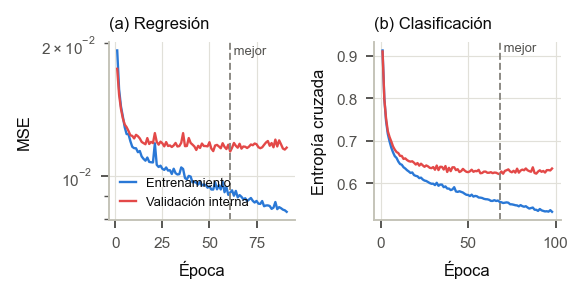

In [13]:
with plt.rc_context(ESTILO_INFORME):
    fig, axes = plt.subplots(1, 2, figsize=(ANCHO_COLUMNA, 1.75))
    for ax, red_i, titulo, etiqueta in [(axes[0], red, "(a) Regresión", "MSE"), (axes[1], red_c, "(b) Clasificación", "Entropía cruzada")]:
        h = np.array(red_i.historia_)
        epocas = np.arange(1, len(h) + 1)
        ax.plot(epocas, h[:, 0], color=AZUL, lw=1, label="Entrenamiento")
        ax.plot(epocas, h[:, 1], color=ROJO, lw=1, label="Validación interna")
        ax.axvline(red_i.mejor_epoca_ + 1, color=TENUE, lw=0.8, ls="--")
        ax.text(red_i.mejor_epoca_ + 1, ax.get_ylim()[1], " mejor", fontsize=5.5, color=TINTA2, va="top")
        ax.set_xlabel("Época"); ax.set_ylabel(etiqueta)
        if etiqueta == "MSE":
            ax.set_yscale("log")
        titulo_panel(ax, titulo)
    axes[0].legend(fontsize=5.5, loc="lower left", handlelength=1.2)
    fig.tight_layout(w_pad=1.0)
    guardar_fig3(fig, "fig1_curvas_perdida_mlp.png")
    plt.show()

**Figura 1.** Pérdida por época de la MLP elegida en (a) regresión y (b) clasificación, en el conjunto de ajuste y en la validación interna con la que se detiene el entrenamiento; la línea discontinua marca la época cuyos pesos se conservan.

Las dos curvas tienen la forma esperada de un entrenamiento sano. La pérdida de ajuste baja de forma continua, mientras que la de validación interna se aplana después de unas 20 épocas y empieza a subir levemente. La parada temprana conservó los pesos de la época 61 en regresión y de la 68 en clasificación, y detuvo el entrenamiento 30 épocas después, justo cuando la red empezaba a memorizar el ruido. Sin ese control, la brecha entre ambas curvas seguiría creciendo, que es la firma del sobreajuste.

## 3.4 Comparación de los modelos de clasificación

In [14]:
def fila_clf(nombre, modelo, cv_media, cv_desv, seg):
    pred_ent = modelo.predict(X_ent)
    m_val = metricas_clf(yc_val, modelo.predict(X_val), modelo.predict_proba(X_val))
    f1_ent = f1_score(yc_ent, pred_ent, average="macro")
    return {"modelo": nombre, "F1 entrenamiento": f1_ent, "F1 CV (media)": cv_media, "F1 CV (desv.)": cv_desv,
            **{f"{k} validación": v for k, v in m_val.items()}, "brecha ent − val": f1_ent - m_val["F1-macro"],
            "tiempo de búsqueda (s)": seg}


dummy_clf = DummyClassifier(strategy="most_frequent").fit(X_ent, yc_ent)
cv_base_c = cross_val_score(base_clf, X_ent, yc_ent, groups=grupos_ent, cv=cv_clf, scoring="f1_macro")
cv_dummy_c = cross_val_score(DummyClassifier(strategy="most_frequent"), X_ent, yc_ent, groups=grupos_ent, cv=cv_clf, scoring="f1_macro")
filas = [fila_clf("Dummy (clase más frecuente)", dummy_clf, cv_dummy_c.mean(), cv_dummy_c.std(), 0.0),
         fila_clf("Logística base de la Fase 2", base_clf, cv_base_c.mean(), cv_base_c.std(), 0.0)]
MODELOS_CLF = {}
for nombre, (busqueda, seg) in BUSQUEDAS_CLF.items():
    modelo = svm_final if nombre.startswith("SVM") else busqueda.best_estimator_
    media, desv = ((CV5_MLP_CLF.mean(), CV5_MLP_CLF.std()) if nombre.startswith("MLP")
                   else (busqueda.best_score_, busqueda.cv_results_["std_test_score"][busqueda.best_index_]))
    MODELOS_CLF[nombre] = modelo
    filas.append(fila_clf(nombre, modelo, media, desv, seg))
res_clf = pd.DataFrame(filas)
candidatos = res_clf.iloc[2:].sort_values("F1-macro validación", ascending=False)
empatados = candidatos[candidatos["F1-macro validación"] >= candidatos["F1-macro validación"].iloc[0] - 0.005]
MEJOR_CLF = empatados.sort_values("F1 CV (media)", ascending=False)["modelo"].iloc[0]
display(Markdown(f"**Modelos de clasificación del nivel de desempeño (Tabla III)** · elegido: **{MEJOR_CLF}**"))
display(res_clf.style.format({c: "{:.3f}" for c in res_clf.columns if c != "modelo"} | {"tiempo de búsqueda (s)": "{:.0f}"}).hide(axis="index"))

# Tabla I: espacios de búsqueda y valores elegidos (las dos tareas)
def describir_espacio(espacio):
    return "; ".join(f"{k.removeprefix('modelo__')} ∈ {{{', '.join(str(round(v, 5)) if isinstance(v, float) else str(v) for v in vals)}}}"
                     for k, vals in espacio.items())


filas_t1 = []
for tarea, busquedas, espacios in [("Regresión", BUSQUEDAS_REG, ESPACIOS_REG), ("Clasificación", BUSQUEDAS_CLF, ESPACIOS_CLF)]:
    for nombre, (busqueda, seg) in busquedas.items():
        espacio, n_iter = (espacio_mlp, None) if nombre.startswith("MLP") else espacios[nombre][1:]
        filas_t1.append({"tarea": tarea, "modelo": nombre,
                         "búsqueda": ("cuadrícula" if n_iter is None else f"aleatoria ({n_iter})")
                                     + f" · {3 if nombre.startswith('MLP') else 5} pliegues",
                         "espacio": describir_espacio(espacio),
                         "elegido": ", ".join(f"{k.removeprefix('modelo__')}={round(v, 5) if isinstance(v, float) else v}"
                                              for k, v in busqueda.best_params_.items())})
tabla_hiper = pd.DataFrame(filas_t1)
display(Markdown("**Espacios de búsqueda y hiperparámetros elegidos por validación cruzada agrupada (Tabla I)**"))
tabla_hiper.style.hide(axis="index").set_properties(**{"text-align": "left"})

**Modelos de clasificación del nivel de desempeño (Tabla III)** · elegido: **Random Forest**

modelo,F1 entrenamiento,F1 CV (media),F1 CV (desv.),accuracy validación,precisión validación,recall validación,F1-macro validación,AUC-ROC validación,brecha ent − val,tiempo de búsqueda (s)
Dummy (clase más frecuente),0.167,0.156,0.005,0.335,0.112,0.333,0.167,0.500,-0.001,0
Logística base de la Fase 2,0.683,0.674,0.013,0.690,0.693,0.689,0.681,0.857,0.002,0
SVM (RBF),0.777,0.721,0.010,0.743,0.746,0.743,0.741,0.876,0.036,15
Random Forest,0.889,0.749,0.007,0.768,0.768,0.768,0.765,0.910,0.124,41
XGBoost,0.816,0.742,0.014,0.759,0.760,0.759,0.756,0.908,0.060,34
MLP (PyTorch),0.750,0.723,0.017,0.736,0.739,0.736,0.732,0.895,0.018,58


**Espacios de búsqueda y hiperparámetros elegidos por validación cruzada agrupada (Tabla I)**

tarea,modelo,búsqueda,espacio,elegido
Regresión,Ridge,cuadrícula · 5 pliegues,"alpha ∈ {0.001, 0.00316, 0.01, 0.03162, 0.1, 0.31623, 1.0, 3.16228, 10.0, 31.62278, 100.0, 316.22777, 1000.0}",alpha=0.001
Regresión,Lasso,cuadrícula · 5 pliegues,"alpha ∈ {1e-05, 3e-05, 0.0001, 0.00032, 0.001, 0.00316, 0.01, 0.03162, 0.1}",alpha=1e-05
Regresión,ElasticNet,cuadrícula · 5 pliegues,"alpha ∈ {1e-05, 3e-05, 0.0001, 0.00032, 0.001, 0.00316, 0.01, 0.03162, 0.1}; l1_ratio ∈ {0.2, 0.5, 0.8}","alpha=1e-05, l1_ratio=0.2"
Regresión,Random Forest,aleatoria (15) · 5 pliegues,"max_depth ∈ {None, 12, 20}; min_samples_leaf ∈ {1, 2, 3, 5, 10}; max_features ∈ {0.3, 0.5, 0.7, 1.0}","min_samples_leaf=2, max_features=0.5, max_depth=20"
Regresión,XGBoost,aleatoria (20) · 5 pliegues,"n_estimators ∈ {300, 600, 900}; learning_rate ∈ {0.02, 0.05, 0.1}; max_depth ∈ {3, 4, 5, 6, 8}; subsample ∈ {0.7, 0.85, 1.0}; colsample_bytree ∈ {0.6, 0.8, 1.0}; min_child_weight ∈ {1, 3, 5, 10}; reg_lambda ∈ {0.5, 1, 3, 10}","subsample=0.85, reg_lambda=10, n_estimators=900, min_child_weight=1, max_depth=6, learning_rate=0.02, colsample_bytree=0.6"
Regresión,MLP (PyTorch),cuadrícula · 3 pliegues,"capas ∈ {(64, 32), (128, 64)}; dropout ∈ {0.1, 0.2}","capas=(128, 64), dropout=0.1"
Clasificación,SVM (RBF),cuadrícula · 5 pliegues,"C ∈ {0.3, 1, 3, 10, 30}; gamma ∈ {scale, 0.03, 0.1, 0.3}","C=10, gamma=0.3"
Clasificación,Random Forest,aleatoria (15) · 5 pliegues,"max_depth ∈ {None, 12, 20}; min_samples_leaf ∈ {1, 2, 4, 8}; max_features ∈ {0.3, 0.5, 0.7, sqrt}","min_samples_leaf=2, max_features=0.7, max_depth=12"
Clasificación,XGBoost,aleatoria (20) · 5 pliegues,"n_estimators ∈ {300, 600, 900}; learning_rate ∈ {0.02, 0.05, 0.1}; max_depth ∈ {3, 4, 5, 6, 8}; subsample ∈ {0.7, 0.85, 1.0}; colsample_bytree ∈ {0.6, 0.8, 1.0}; min_child_weight ∈ {1, 3, 5, 10}; reg_lambda ∈ {0.5, 1, 3, 10}","subsample=0.7, reg_lambda=3, n_estimators=300, min_child_weight=3, max_depth=4, learning_rate=0.05, colsample_bytree=1.0"
Clasificación,MLP (PyTorch),cuadrícula · 3 pliegues,"capas ∈ {(64, 32), (128, 64)}; dropout ∈ {0.1, 0.2}","capas=(128, 64), dropout=0.1"


**Interpretación de la clasificación (Tabla III)**

- **Los cuatro algoritmos superan la meta SMART (F1-macro ≥ 0.70) y la base de la Fase 2 (0.681).** Random Forest es el mejor en todas las métricas de validación: F1-macro = 0.765, *accuracy* = 0.768 y AUC-ROC = 0.910, con F1 CV = 0.749 ± 0.007. Lo siguen XGBoost (0.756), la SVM (0.741) y la MLP (0.732).
- **Precisión y *recall* casi iguales** (0.768 y 0.768 en Random Forest) indican que el modelo no favorece ninguna clase: el F1 alto no se consigue a costa de predecir siempre la clase mayoritaria, que no existe porque las clases están balanceadas.
- **AUC-ROC = 0.91**: si se toma al azar una planta de un nivel y otra de otro, el modelo ordena bien sus probabilidades 91 de cada 100 veces. Supera a la logística (0.857) incluso donde la clasificación dura no cambia, lo que importa para el tablero, que mostrará la probabilidad de cada nivel.
- **La SVM es el caso didáctico del costo de la flexibilidad.** Con C = 10 y γ = 0.3 (frontera muy flexible) mejora a la logística en seis puntos de F1, pero queda por debajo de los árboles, que manejan mejor las variables de escalas y naturalezas distintas (una codificación del país, coordenadas, indicadores binarios).
- **Elegido: Random Forest**, con la misma regla de la regresión.

## 3.5 Curvas ROC y matriz de confusión del clasificador elegido (Figura 2)

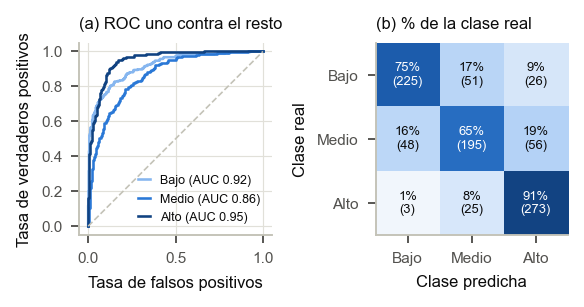

Recall por clase (validación): {'Bajo': np.float64(0.745), 'Medio': np.float64(0.652), 'Alto': np.float64(0.907)} | errores que saltan dos niveles: 3.2%


In [15]:
modelo_c = MODELOS_CLF[MEJOR_CLF]
proba_val = modelo_c.predict_proba(X_val)
pred_val_c = modelo_c.predict(X_val)
COLOR_NIVEL = ["#86b6ef", "#2a78d6", "#104281"]
with plt.rc_context(ESTILO_INFORME):
    fig, axes = plt.subplots(1, 2, figsize=(ANCHO_COLUMNA, 1.85), gridspec_kw={"width_ratios": [1, 1]})
    ax = axes[0]
    for k, nivel in enumerate(NIVELES):
        fpr, tpr, _ = roc_curve(yc_val == k, proba_val[:, k])
        ax.plot(fpr, tpr, color=COLOR_NIVEL[k], lw=1.1, label=f"{nivel} (AUC {roc_auc_score(yc_val == k, proba_val[:, k]):.2f})")
    ax.plot([0, 1], [0, 1], color=GRIS, lw=0.7, ls="--")
    ax.set_xlabel("Tasa de falsos positivos"); ax.set_ylabel("Tasa de verdaderos positivos")
    ax.set_aspect("equal"); ax.legend(fontsize=5.3, loc="lower right", handlelength=1.0)
    titulo_panel(ax, "(a) ROC uno contra el resto")
    ax = axes[1]
    mc = confusion_matrix(yc_val, pred_val_c, labels=[0, 1, 2])
    mc_p = mc / mc.sum(axis=1, keepdims=True)
    ax.imshow(mc_p, cmap=CMAP_SEQ, vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{mc_p[i, j]:.0%}\n({mc[i, j]})", ha="center", va="center", fontsize=5.5,
                    color="white" if mc_p[i, j] > 0.6 else TINTA)
    ax.set_xticks(range(3), NIVELES); ax.set_yticks(range(3), NIVELES)
    ax.set_xlabel("Clase predicha"); ax.set_ylabel("Clase real"); ax.grid(False)
    titulo_panel(ax, "(b) % de la clase real")
    fig.tight_layout(w_pad=1.2)
    guardar_fig3(fig, "fig2_roc_confusion.png")
    plt.show()
recall_clase = np.diag(mc) / mc.sum(axis=1)
print("Recall por clase (validación):", dict(zip(NIVELES, recall_clase.round(3))),
      f"| errores que saltan dos niveles: {(np.abs(yc_val.values - pred_val_c) == 2).mean():.1%}")

**Figura 2.** Clasificador elegido en validación: (a) curvas ROC uno contra el resto para cada nivel y (b) matriz de confusión normalizada por la clase real (entre paréntesis, el número de plantas).

La clase **Alto** se reconoce casi siempre (*recall* = 0.91; AUC = 0.95), porque la componen sobre todo la biomasa, la geotérmica y las hidroeléctricas de embalse grande, que se distinguen por su tecnología y su escala. **Bajo** mejora mucho frente a la Fase 2 (*recall* = 0.75; AUC = 0.92). **Medio** sigue siendo la más difícil (*recall* = 0.65; AUC = 0.86): es una banda estrecha de FP (0.205–0.323) donde se cruzan solares de buen sitio, eólicas y pequeñas hidroeléctricas. Solo el 3.2 % de las plantas salta dos niveles (Bajo ↔ Alto), frente al 5.2 % del modelo base: cuando el modelo se equivoca, casi siempre lo hace hacia el nivel vecino.

# 4. Segmentación no supervisada de las plantas (PS3 · Actividad 5)

**Pregunta secundaria PS3:** ¿qué segmentos naturales de plantas emergen al combinar escala, ubicación, antigüedad, rendimiento y estabilidad, y qué tecnologías los componen? La meta de la Fase 1 era una **silueta ≥ 0.35**; la prueba de concepto llegó a 0.33.

**Datos.** Las cinco dimensiones de la pregunta, una variable por dimensión: escala (log₁₀ de la capacidad), ubicación (distancia al ecuador, |latitud|), antigüedad (edad en 2019), rendimiento (FP promedio) y estabilidad (coeficiente de variación interanual del FP, en escala logarítmica porque es muy asimétrico). Se usan las plantas con edad conocida y al menos tres años de generación (sin ellos el coeficiente de variación no es fiable): no se imputa nada, porque un valor imputado acercaría artificialmente las plantas al centro de su grupo. Las variables se estandarizan para que ninguna domine la distancia.

**Por qué aquí no hay partición.** El clustering es descriptivo: no predice un objetivo y sus grupos no se usan como predictores de los modelos supervisados, así que se ajusta con todas las plantas elegibles sin riesgo de fuga.

**Algoritmos.**
- **K-Means**: minimiza la suma de distancias al cuadrado de cada planta al centroide de su grupo (inercia); k se elige con el **método del codo** (el punto de máxima curvatura de la inercia) y el **coeficiente de silueta** (cohesión frente a separación, de −1 a 1).
- **Jerárquico aglomerativo con enlace de Ward**: fusiona en cada paso los dos grupos que menos aumentan la varianza interna; no supone grupos esféricos y su dendrograma muestra la estructura a todas las escalas.
- **DBSCAN**: agrupa regiones densas (al menos `min_samples` vecinos a distancia ε) y deja como **ruido** las plantas aisladas; se usa para detectar plantas atípicas, algo que K-Means no hace.

## 4.1 K-Means: método del codo y coeficiente de silueta

In [16]:
VARS_CLUSTER = {"log_capacidad": "Escala (log₁₀ MW)", "latitud_abs": "Distancia al ecuador (°)", "edad_planta": "Edad (años)",
                "factor_planta_prom": "Factor de planta", "log_cv": "Inestabilidad (log CV)"}
dc = dm.dropna(subset=["edad_planta", "cv_generacion"]).copy()
dc["log_cv"] = np.log(dc["cv_generacion"] + 0.01)
Zc = StandardScaler().fit_transform(dc[list(VARS_CLUSTER)])
print(f"Plantas elegibles para el clustering: {len(dc):,} de {len(dm):,} "
      f"({len(dm) - len(dc):,} sin edad conocida o con menos de 3 años de generación)")

K_RANGO = range(2, 11)
filas_k = []
for k in K_RANGO:
    km = KMeans(n_clusters=k, n_init=20, random_state=SEMILLA).fit(Zc)
    ward = AgglomerativeClustering(n_clusters=k, linkage="ward").fit(Zc)
    filas_k.append({"k": k, "inercia": km.inertia_, "silueta K-Means": silhouette_score(Zc, km.labels_),
                    "silueta Ward": silhouette_score(Zc, ward.labels_)})
tabla_k = pd.DataFrame(filas_k).set_index("k")

# Codo: el k más alejado de la recta que une la inercia en k = 2 y k = 10 (criterio de máxima curvatura, «Kneedle»)
x = np.array(list(K_RANGO), dtype=float)
yi = tabla_k["inercia"].values
xn, yn = (x - x.min()) / (x.max() - x.min()), (yi - yi.min()) / (yi.max() - yi.min())
K_CODO = int(x[np.argmax(np.abs(yn - (1 - xn)))])
K_SIL = int(tabla_k["silueta K-Means"].idxmax())
tabla_k["caída de inercia (%)"] = -tabla_k["inercia"].pct_change() * 100
display(tabla_k.style.format({"inercia": "{:,.0f}", "silueta K-Means": "{:.3f}", "silueta Ward": "{:.3f}",
                              "caída de inercia (%)": "{:.1f}"}))
print(f"Codo de la inercia: k = {K_CODO} | máxima silueta de K-Means: k = {K_SIL} "
      f"({tabla_k.loc[K_SIL, 'silueta K-Means']:.3f}) | silueta en el codo: {tabla_k.loc[K_CODO, 'silueta K-Means']:.3f}")

Plantas elegibles para el clustering: 4,334 de 6,011 (1,677 sin edad conocida o con menos de 3 años de generación)


,inercia,silueta K-Means,silueta Ward,caída de inercia (%)
k,,,,
2,"16,189",0.297,0.230,nan
3,"13,111",0.276,0.253,19.0
4,"11,092",0.280,0.195,15.4
5,"9,775",0.263,0.216,11.9
6,"8,657",0.273,0.214,11.4
7,"7,941",0.272,0.226,8.3
8,"7,312",0.273,0.235,7.9
9,"6,828",0.277,0.232,6.6
10,"6,420",0.243,0.233,6.0


Codo de la inercia: k = 5 | máxima silueta de K-Means: k = 2 (0.297) | silueta en el codo: 0.263


**Elección de k.** El codo y la silueta pueden no coincidir. La regla, fijada antes de mirar los grupos, es usar el **codo** cuando su silueta está a menos de 0.03 de la máxima: un número de grupos algo mayor, con casi la misma calidad de separación, describe mejor la diversidad del parque. Si la diferencia es mayor, manda la silueta.

In [17]:
K = K_CODO if tabla_k.loc[K_SIL, "silueta K-Means"] - tabla_k.loc[K_CODO, "silueta K-Means"] < 0.03 else K_SIL
km_final = KMeans(n_clusters=K, n_init=50, random_state=SEMILLA).fit(Zc)
ward_final = AgglomerativeClustering(n_clusters=K, linkage="ward").fit(Zc)
dc["grupo_kmeans"], dc["grupo_ward"] = km_final.labels_, ward_final.labels_
sil_km, sil_ward = silhouette_score(Zc, km_final.labels_), silhouette_score(Zc, ward_final.labels_)
ari = adjusted_rand_score(km_final.labels_, ward_final.labels_)
# Sensibilidad: la silueta sube si se agrupa en un espacio reducido, pero a costa de descartar información
pca2 = PCA(n_components=2, random_state=SEMILLA).fit(Zc)
Z2 = pca2.transform(Zc)
sil_pca = silhouette_score(Z2, KMeans(n_clusters=K, n_init=20, random_state=SEMILLA).fit_predict(Z2))
print(f"k elegido = {K} | silueta K-Means = {sil_km:.3f} | silueta Ward = {sil_ward:.3f} | "
      f"ARI K-Means vs Ward = {ari:.3f}")
print(f"Sensibilidad: K-Means sobre 2 componentes principales ({pca2.explained_variance_ratio_.sum():.0%} de la varianza) "
      f"→ silueta {sil_pca:.3f}")

k elegido = 2 | silueta K-Means = 0.297 | silueta Ward = 0.230 | ARI K-Means vs Ward = 0.155
Sensibilidad: K-Means sobre 2 componentes principales (58% de la varianza) → silueta 0.428


## 4.2 Jerárquico aglomerativo (Ward): dendrograma

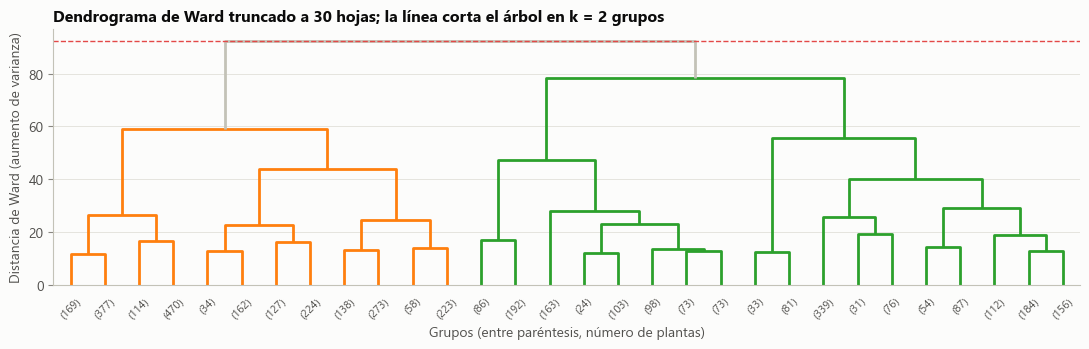

Altura de las últimas fusiones (de la última hacia atrás): [92.2 78.3 58.9 55.5 47.3 43.8 40.2 29.  27.8 26.3]


In [18]:
enlace = linkage(Zc, method="ward")
fig, ax = plt.subplots(figsize=(11, 3.6))
dendrogram(enlace, truncate_mode="lastp", p=30, color_threshold=enlace[-(K - 1), 2], above_threshold_color=GRIS, ax=ax,
           leaf_font_size=8)
ax.axhline(enlace[-(K - 1), 2], color=ROJO, lw=1, ls="--")
ax.set_ylabel("Distancia de Ward (aumento de varianza)"); ax.set_xlabel("Grupos (entre paréntesis, número de plantas)")
ax.set_title(f"Dendrograma de Ward truncado a 30 hojas; la línea corta el árbol en k = {K} grupos", loc="left")
ax.grid(axis="x", visible=False)
fig.tight_layout(); plt.show()
saltos = np.diff(enlace[-12:, 2])[::-1]
print("Altura de las últimas fusiones (de la última hacia atrás):", np.round(enlace[-10:, 2][::-1], 1))

## 4.3 DBSCAN: grupos densos y plantas atípicas

In [19]:
MIN_MUESTRAS = 2 * Zc.shape[1]                       # regla habitual: el doble de la dimensión
dist_k = np.sort(NearestNeighbors(n_neighbors=MIN_MUESTRAS).fit(Zc).kneighbors(Zc)[0][:, -1])
xn = np.linspace(0, 1, len(dist_k))
yn = (dist_k - dist_k.min()) / (dist_k.max() - dist_k.min())
EPS = float(dist_k[np.argmax(xn - yn)])             # codo de la curva de distancias al k-ésimo vecino
db = DBSCAN(eps=EPS, min_samples=MIN_MUESTRAS).fit(Zc)
dc["grupo_dbscan"] = db.labels_
n_grupos_db = len(set(db.labels_)) - (1 if -1 in db.labels_ else 0)
ruido = db.labels_ == -1
sil_db = silhouette_score(Zc[~ruido], db.labels_[~ruido]) if n_grupos_db > 1 else np.nan
print(f"DBSCAN (ε = {EPS:.2f}, min_samples = {MIN_MUESTRAS}): {n_grupos_db} grupos densos, {ruido.mean():.1%} de plantas como ruido; "
      f"silueta sin el ruido = {sil_db:.3f}")
display(Markdown("**Plantas que DBSCAN marca como atípicas: composición por tecnología y medianas**"))
display(pd.concat([dc.loc[ruido, "tecnologia"].value_counts().rename("atípicas"),
                   dc["tecnologia"].value_counts().rename("todas")], axis=1)
        .assign(**{"% atípicas": lambda t: t["atípicas"] / t["todas"] * 100}).loc[TEC_MODELO].round(1))
display(dc.loc[ruido, list(VARS_CLUSTER) + ["capacity_mw"]].median().to_frame("mediana de las atípicas")
        .join(dc[list(VARS_CLUSTER) + ["capacity_mw"]].median().to_frame("mediana de todas")).round(3))

DBSCAN (ε = 1.00, min_samples = 10): 3 grupos densos, 3.8% de plantas como ruido; silueta sin el ruido = 0.418


**Plantas que DBSCAN marca como atípicas: composición por tecnología y medianas**

,atípicas,todas,% atípicas
tecnologia,,,
Solar,8,1639,0.500
Eólica,12,927,1.300
Hidroeléctrica,121,1576,7.700
Geotérmica,5,59,8.500
Biomasa,18,133,13.500


,mediana de las atípicas,mediana de todas
log_capacidad,1.477,0.820
latitud_abs,33.061,39.395
edad_planta,32.000,9.000
factor_planta_prom,0.338,0.273
log_cv,-1.774,-2.163
capacity_mw,30.000,6.600


## 4.4 Perfiles de los grupos y comparación de algoritmos (Tabla IV y Figura 3)

**Perfil de los 2 grupos de K-Means (medianas y % de cada tecnología en el grupo) · Tabla IV**

,plantas,capacidad_mw,latitud_abs,edad,fp,cv,Solar,Eólica,Hidroeléctrica,Geotérmica,Biomasa,% en EE. UU.
grupo_kmeans,,,,,,,,,,,,
1,1437,11.8,42.2,59,0.416,0.221,0,1,90,3,6,94
0,2897,5.0,37.9,6,0.224,0.071,57,31,10,1,2,95


**Comparación de los algoritmos de clustering**

algoritmo,grupos,silueta,% de plantas sin grupo,ARI frente a K-Means
K-Means,2,0.297,0.0,1.000
Jerárquico (Ward),2,0.230,0.0,0.155
DBSCAN,3,0.418,3.8,-0.003


**Tecnología por grupo de Ward (% de cada grupo)**

tecnologia,Solar,Eólica,Hidroeléctrica,Geotérmica,Biomasa
grupo_ward,,,,,
0,6.000,31.000,57.000,3.000,3.000
1,64.000,13.000,20.000,0.000,3.000


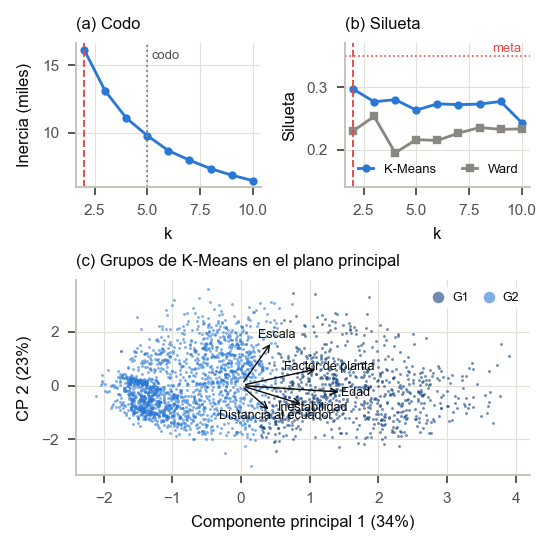

In [20]:
perfil = dc.groupby("grupo_kmeans").agg(plantas=("gppd_idnr", "size"), capacidad_mw=("capacity_mw", "median"),
                                        latitud_abs=("latitud_abs", "median"), edad=("edad_planta", "median"),
                                        fp=("factor_planta_prom", "median"), cv=("cv_generacion", "median"))
composicion = pd.crosstab(dc["grupo_kmeans"], dc["tecnologia"].astype(str), normalize="index")[TEC_MODELO] * 100
perfil = perfil.join(composicion.round(0)).sort_values("fp", ascending=False)
perfil["% en EE. UU."] = dc.groupby("grupo_kmeans")["country"].apply(lambda s: (s == "USA").mean() * 100)
display(Markdown(f"**Perfil de los {K} grupos de K-Means (medianas y % de cada tecnología en el grupo) · Tabla IV**"))
display(perfil.style.format({"capacidad_mw": "{:,.1f}", "latitud_abs": "{:.1f}", "edad": "{:.0f}", "fp": "{:.3f}",
                             "cv": "{:.3f}", "% en EE. UU.": "{:.0f}"} | {t: "{:.0f}" for t in TEC_MODELO}))
comparacion_cl = pd.DataFrame({
    "algoritmo": ["K-Means", "Jerárquico (Ward)", "DBSCAN"],
    "grupos": [K, K, n_grupos_db], "silueta": [sil_km, sil_ward, sil_db],
    "% de plantas sin grupo": [0.0, 0.0, ruido.mean() * 100],
    "ARI frente a K-Means": [1.0, ari, adjusted_rand_score(km_final.labels_[~ruido], db.labels_[~ruido])],
})
display(Markdown("**Comparación de los algoritmos de clustering**"))
display(comparacion_cl.style.format({"silueta": "{:.3f}", "% de plantas sin grupo": "{:.1f}", "ARI frente a K-Means": "{:.3f}"}).hide(axis="index"))
display(Markdown("**Tecnología por grupo de Ward (% de cada grupo)**"))
display((pd.crosstab(dc["grupo_ward"], dc["tecnologia"].astype(str), normalize="index")[TEC_MODELO] * 100).round(0))

ORDEN_GRUPOS = perfil.index.tolist()                 # de mayor a menor FP mediano
COLOR_GRUPO = dict(zip(ORDEN_GRUPOS, ["#104281", "#2a78d6", "#1baf7a", "#eda100", "#e34948", "#6250d6", "#898781", "#008300"]))
with plt.rc_context(ESTILO_INFORME):
    fig = plt.figure(figsize=(ANCHO_COLUMNA, 3.3))
    gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.35], hspace=0.55, wspace=0.45)
    ax = fig.add_subplot(gs[0, 0])
    ax.plot(tabla_k.index, tabla_k["inercia"] / 1e3, color=AZUL, marker="o", ms=2.5)
    ax.axvline(K, color=ROJO, lw=0.8, ls="--")
    ax.axvline(K_CODO, color=TENUE, lw=0.8, ls=":")
    ax.text(K_CODO + 0.2, ax.get_ylim()[1] * 0.97, "codo", fontsize=5.5, color=TINTA2, va="top")
    ax.set_xlabel("k"); ax.set_ylabel("Inercia (miles)"); titulo_panel(ax, "(a) Codo")
    ax = fig.add_subplot(gs[0, 1])
    ax.plot(tabla_k.index, tabla_k["silueta K-Means"], color=AZUL, marker="o", ms=2.5, label="K-Means")
    ax.plot(tabla_k.index, tabla_k["silueta Ward"], color=TENUE, marker="s", ms=2.2, label="Ward")
    ax.axhline(0.35, color=ROJO, lw=0.7, ls=":")
    ax.text(10, 0.352, "meta", fontsize=5.5, color=ROJO, ha="right", va="bottom")
    ax.axvline(K, color=ROJO, lw=0.8, ls="--")
    ax.set_ylim(0.14, 0.37)
    ax.set_xlabel("k"); ax.set_ylabel("Silueta"); ax.legend(fontsize=5.5, loc="lower right", handlelength=1.2, ncol=2)
    titulo_panel(ax, "(b) Silueta")
    ax = fig.add_subplot(gs[1, :])
    muestra = np.random.default_rng(SEMILLA).choice(len(dc), size=min(2500, len(dc)), replace=False)
    for g in ORDEN_GRUPOS:
        sel = muestra[km_final.labels_[muestra] == g]
        ax.scatter(Z2[sel, 0], Z2[sel, 1], s=1.5, color=COLOR_GRUPO[g], alpha=0.6, lw=0, label=f"G{ORDEN_GRUPOS.index(g) + 1}")
    cargas = pca2.components_.T * 2.2
    for (nombre, etiqueta), (cx, cy) in zip(VARS_CLUSTER.items(), cargas):
        ax.annotate("", xy=(cx, cy), xytext=(0, 0), arrowprops=dict(arrowstyle="->", color=TINTA, lw=0.6))
        ax.text(cx * 1.12, cy * 1.12, etiqueta.split(" (")[0], fontsize=5.3, color=TINTA, ha="center", va="center")
    ax.set_xlabel(f"Componente principal 1 ({pca2.explained_variance_ratio_[0]:.0%})")
    ax.set_ylabel(f"CP 2 ({pca2.explained_variance_ratio_[1]:.0%})")
    ax.legend(markerscale=4, fontsize=5.3, ncol=2, loc="upper right", handletextpad=0.1, columnspacing=0.6, labelspacing=0.2,
              frameon=True, facecolor="white", edgecolor="none", framealpha=0.85)
    titulo_panel(ax, "(c) Grupos de K-Means en el plano principal")
    guardar_fig3(fig, "fig3_clustering.png")
    plt.show()

**Figura 3.** Clustering de las plantas: (a) inercia de K-Means según k (método del codo; línea discontinua: k elegido, punteada: codo); (b) coeficiente de silueta de K-Means y de Ward, con la meta de la Fase 1 en línea punteada; (c) grupos de K-Means proyectados en los dos primeros componentes principales, con las flechas de carga de cada variable. Los grupos se numeran de mayor a menor factor de planta mediano.

- **Elección de k.** La silueta máxima de K-Means se da con k = 2 (0.297) y el codo de la inercia en k = 5 (silueta 0.263). La diferencia (0.034) supera el margen de 0.03 fijado de antemano, así que la regla elige **k = 2**. La segmentación de k = 5 se describe en la §4.5 como lectura complementaria.
- **La meta de silueta (≥ 0.35) no se alcanza** con ningún k ni algoritmo sobre las cinco dimensiones. Las plantas forman un **continuo** más que grupos nítidos: hay hidroeléctricas nuevas y eólicas antiguas que llenan el espacio entre los perfiles típicos. Agrupar sobre dos componentes principales subiría la silueta a 0.428, pero descartaría el 42 % de la información; se prefirió reportar la separación real.
- **Los dos grupos tienen un sentido físico claro** (Tabla IV). **G1, el parque antiguo y gestionable**, tiene 1 437 plantas, 90 % hidroeléctricas, una mediana de 59 años y un FP alto (0.42) pero **inestable** (CV = 0.22, porque depende de las lluvias). **G2, el parque nuevo**, tiene 2 897 plantas, 57 % solar y 31 % eólica, una mediana de 6 años y 5 MW, y un FP menor (0.22) pero **muy estable** (CV = 0.07). En el plano principal (Fig. 3c), la edad, el FP y la inestabilidad empujan hacia G1; la escala separa a las eólicas grandes dentro de G2.
- **Ward no confirma la partición de K-Means** (ARI = 0.155; silueta 0.230): con k = 2 corta el árbol por otro lado (separa la mayoría de las solares de un grupo mixto), otra señal de que la frontera entre segmentos es difusa.
- **Valor práctico.** La división dice que el desafío de gestión del parque renovable no es una tecnología, sino una combinación: el parque antiguo aporta energía gestionable pero variable año a año, y el nuevo aporta energía estable pero de menor FP. Ambos se complementan.

## 4.5 Segmentación fina en el codo y grupos densos de DBSCAN

La regla eligió el k de la silueta. Como el codo propone una segmentación más fina con una silueta solo algo menor, se describe también, como lectura **complementaria y exploratoria**: no reemplaza la elección, pero muestra cómo se subdividen los dos grandes grupos. Se describen además los grupos densos de DBSCAN.

In [21]:
km_fino = KMeans(n_clusters=K_CODO, n_init=50, random_state=SEMILLA).fit(Zc)
dc["grupo_fino"] = km_fino.labels_
fino = dc.groupby("grupo_fino").agg(plantas=("gppd_idnr", "size"), capacidad_mw=("capacity_mw", "median"),
                                    latitud_abs=("latitud_abs", "median"), edad=("edad_planta", "median"),
                                    fp=("factor_planta_prom", "median"), cv=("cv_generacion", "median"))
fino = fino.join((pd.crosstab(dc["grupo_fino"], dc["tecnologia"].astype(str), normalize="index")[TEC_MODELO] * 100).round(0))
fino["grupo de k = 2"] = dc.groupby("grupo_fino")["grupo_kmeans"].agg(lambda s: f"G{ORDEN_GRUPOS.index(s.mode().iloc[0]) + 1}")
fino = fino.sort_values("fp", ascending=False)
display(Markdown(f"**Segmentación fina en el codo (k = {K_CODO}): medianas y % de cada tecnología**"))
display(fino.style.format({"capacidad_mw": "{:,.1f}", "latitud_abs": "{:.1f}", "edad": "{:.0f}", "fp": "{:.3f}", "cv": "{:.3f}"}
                          | {t: "{:.0f}" for t in TEC_MODELO}))
print(f"Silueta de la segmentación fina: {silhouette_score(Zc, km_fino.labels_):.3f}")
db_perfil = dc.groupby("grupo_dbscan").agg(plantas=("gppd_idnr", "size"), edad=("edad_planta", "median"),
                                           fp=("factor_planta_prom", "median"), cv=("cv_generacion", "median"))
db_perfil = db_perfil.join((pd.crosstab(dc["grupo_dbscan"], dc["tecnologia"].astype(str), normalize="index")[TEC_MODELO] * 100).round(0))
display(Markdown("**Grupos de DBSCAN (−1 = ruido): tamaño, medianas y % de cada tecnología**"))
display(db_perfil.style.format({"edad": "{:.0f}", "fp": "{:.3f}", "cv": "{:.3f}"} | {t: "{:.0f}" for t in TEC_MODELO}))

**Segmentación fina en el codo (k = 5): medianas y % de cada tecnología**

,plantas,capacidad_mw,latitud_abs,edad,fp,cv,Solar,Eólica,Hidroeléctrica,Geotérmica,Biomasa,grupo de k = 2
grupo_fino,,,,,,,,,,,,
4,722,7.2,43.9,73,0.520,0.161,0,0,93,1,6,G1
0,945,100.5,39.3,9,0.341,0.070,11,66,14,5,4,G2
2,506,65.8,34.6,53,0.251,0.354,2,7,88,1,2,G1
3,813,2.4,40.7,11,0.222,0.245,37,21,37,0,4,G2
1,1348,3.0,36.4,5,0.204,0.052,91,7,2,0,1,G2


Silueta de la segmentación fina: 0.264


**Grupos de DBSCAN (−1 = ruido): tamaño, medianas y % de cada tecnología**

,plantas,edad,fp,cv,Solar,Eólica,Hidroeléctrica,Geotérmica,Biomasa
grupo_dbscan,,,,,,,,,
-1,164,32,0.338,0.160,5,7,74,3,11
0,4140,9,0.271,0.102,39,22,34,1,3
1,15,21,0.174,0.386,0,0,100,0,0
2,15,48,0.401,0.279,0,0,100,0,0


# 5. Evaluación comparativa, robustez e interpretabilidad (Actividad 6)

## 5.1 Evaluación final en el conjunto de prueba

Esta es la **única** vez que la Fase 3 usa el conjunto de prueba. La elección de los modelos (regla de la §2.4 y la §3.4) ya está hecha, así que evaluar aquí todos los modelos no introduce sesgo de selección: sirve para ver si el orden observado en validación se sostiene en plantas nuevas. Para el modelo elegido se calcula además un **intervalo de confianza del 95 % por *bootstrap*** (1 000 remuestreos de las plantas de prueba) y la mejora frente al modelo base con el mismo remuestreo (comparación pareada).

In [22]:
pred_pru_reg = {"Dummy (media)": dummy_reg.predict(X_pru), "Lineal base de la Fase 2": base_reg.predict(X_pru)}
pred_pru_reg |= {n: m.predict(X_pru) for n, m in MODELOS_REG.items()}
prueba_reg = pd.DataFrame({n: metricas_reg(y_pru, p) for n, p in pred_pru_reg.items()}).T
prueba_reg["R² validación"] = res_reg.set_index("modelo")["R² validación"]

modelos_c_todos = {"Dummy (clase más frecuente)": dummy_clf, "Logística base de la Fase 2": base_clf} | MODELOS_CLF
pred_pru_clf = {n: m.predict(X_pru) for n, m in modelos_c_todos.items()}
proba_pru_clf = {n: m.predict_proba(X_pru) for n, m in modelos_c_todos.items()}
prueba_clf = pd.DataFrame({n: metricas_clf(yc_pru, pred_pru_clf[n], proba_pru_clf[n]) for n in modelos_c_todos}).T
prueba_clf["F1-macro validación"] = res_clf.set_index("modelo")["F1-macro validación"]


def bootstrap(metrica, y, p_mejor, p_base, n=1000):
    rng_b = np.random.default_rng(SEMILLA)
    y, p_mejor, p_base = np.asarray(y), np.asarray(p_mejor), np.asarray(p_base)
    vals, difs = [], []
    for _ in range(n):
        i = rng_b.integers(0, len(y), len(y))
        m = metrica(y[i], p_mejor[i])
        vals.append(m); difs.append(m - metrica(y[i], p_base[i]))
    return np.percentile(vals, [2.5, 97.5]), np.percentile(difs, [2.5, 97.5]), (np.array(difs) <= 0).mean()


f1m = lambda a, b: f1_score(a, b, average="macro")
ic_r2, ic_dif_r2, p_r2 = bootstrap(r2_score, y_pru, pred_pru_reg[MEJOR_REG], pred_pru_reg["Lineal base de la Fase 2"])
ic_f1, ic_dif_f1, p_f1 = bootstrap(f1m, yc_pru, pred_pru_clf[MEJOR_CLF], pred_pru_clf["Logística base de la Fase 2"])
R2_PRU, F1_PRU = prueba_reg.loc[MEJOR_REG, "R²"], prueba_clf.loc[MEJOR_CLF, "F1-macro"]

display(Markdown("**Regresión: todos los modelos en prueba (validación como referencia)**"))
display(prueba_reg.style.format("{:.3f}"))
display(Markdown("**Clasificación: todos los modelos en prueba (validación como referencia)**"))
display(prueba_clf.style.format("{:.3f}"))

umbral_final = pd.DataFrame([
    {"tarea": "Regresión (R²)", "base Fase 2 (prueba)": prueba_reg.loc["Lineal base de la Fase 2", "R²"],
     "modelo elegido": MEJOR_REG, "prueba": R2_PRU, "IC 95 %": f"{ic_r2[0]:.3f}–{ic_r2[1]:.3f}",
     "mejora (IC 95 %)": f"{R2_PRU - prueba_reg.loc['Lineal base de la Fase 2', 'R²']:+.3f} ({ic_dif_r2[0]:+.3f} a {ic_dif_r2[1]:+.3f})",
     "meta": 0.55, "¿cumple?": "Sí" if R2_PRU >= 0.55 else "No"},
    {"tarea": "Clasificación (F1-macro)", "base Fase 2 (prueba)": prueba_clf.loc["Logística base de la Fase 2", "F1-macro"],
     "modelo elegido": MEJOR_CLF, "prueba": F1_PRU, "IC 95 %": f"{ic_f1[0]:.3f}–{ic_f1[1]:.3f}",
     "mejora (IC 95 %)": f"{F1_PRU - prueba_clf.loc['Logística base de la Fase 2', 'F1-macro']:+.3f} ({ic_dif_f1[0]:+.3f} a {ic_dif_f1[1]:+.3f})",
     "meta": 0.70, "¿cumple?": "Sí" if F1_PRU >= 0.70 else "No"},
])
display(Markdown("**Modelo elegido frente al umbral de la Fase 2 y a la meta SMART, en prueba (Tabla V)**"))
display(umbral_final.style.format({"base Fase 2 (prueba)": "{:.3f}", "prueba": "{:.3f}", "meta": "{:.2f}"}).hide(axis="index"))
print(f"Proporción de remuestreos en que el modelo elegido NO supera a la base: regresión {p_r2:.3f} | clasificación {p_f1:.3f}")

**Regresión: todos los modelos en prueba (validación como referencia)**

,R²,RMSE,MAE,R² validación
Dummy (media),-0.000,0.154,0.120,-0.000
Lineal base de la Fase 2,0.449,0.115,0.077,0.489
Ridge,0.447,0.115,0.077,0.491
Lasso,0.447,0.115,0.077,0.491
ElasticNet,0.447,0.115,0.077,0.491
Random Forest,0.623,0.095,0.060,0.630
XGBoost,0.608,0.097,0.062,0.618
MLP (PyTorch),0.530,0.106,0.069,0.568


**Clasificación: todos los modelos en prueba (validación como referencia)**

,accuracy,precisión,recall,F1-macro,AUC-ROC,F1-macro validación
Dummy (clase más frecuente),0.327,0.109,0.333,0.164,0.500,0.167
Logística base de la Fase 2,0.678,0.679,0.677,0.671,0.864,0.681
SVM (RBF),0.730,0.735,0.729,0.728,0.880,0.741
Random Forest,0.761,0.765,0.760,0.760,0.916,0.765
XGBoost,0.753,0.758,0.752,0.751,0.912,0.756
MLP (PyTorch),0.739,0.744,0.738,0.736,0.900,0.732


**Modelo elegido frente al umbral de la Fase 2 y a la meta SMART, en prueba (Tabla V)**

tarea,base Fase 2 (prueba),modelo elegido,prueba,IC 95 %,mejora (IC 95 %),meta,¿cumple?
Regresión (R²),0.449,Random Forest,0.623,0.573–0.669,+0.174 (+0.137 a +0.218),0.55,Sí
Clasificación (F1-macro),0.671,Random Forest,0.760,0.734–0.786,+0.088 (+0.061 a +0.115),0.70,Sí


Proporción de remuestreos en que el modelo elegido NO supera a la base: regresión 0.000 | clasificación 0.000


**Interpretación de la evaluación en prueba (Tabla V)**

- **El orden de validación se sostiene en prueba**, y ningún modelo pierde más de 0.04 respecto a validación, lo que descarta un sobreajuste a la validación por la elección. En regresión, Random Forest (R² = 0.623) supera a XGBoost (0.608), a la MLP (0.530) y a los lineales (0.447–0.449). En clasificación, Random Forest (F1-macro = 0.760; AUC = 0.916) supera a XGBoost (0.751), a la MLP (0.736) y a la SVM (0.728).
- **Ambas metas SMART se cumplen en prueba**, con intervalos de confianza que las respaldan: R² = 0.623 (IC 95 %: 0.573–0.669) frente a la meta de 0.55, y F1-macro = 0.760 (0.734–0.786) frente a la meta de 0.70. En los dos casos, el límite inferior del intervalo supera la meta.
- **La mejora frente a la Fase 2 es clara y no depende del azar de la muestra**: +0.174 puntos de R² (IC 95 %: +0.137 a +0.218) y +0.088 de F1-macro (+0.061 a +0.115). En ninguno de los 1 000 remuestreos el modelo base supera al elegido.
- En unidades del problema: el error típico de predicción del FP baja de 11.5 a 9.5 puntos (RMSE) y el error absoluto medio de 7.7 a 6.0. Para una planta de 100 MW, 6 puntos de FP equivalen a unos 53 GWh al año.

## 5.2 Robustez: aporte de las coordenadas, validación por bloques geográficos y estabilidad

Tres pruebas, con los hiperparámetros ya elegidos (no se vuelve a buscar):
1. **Ablación de las coordenadas**: el mismo modelo sin latitud ni longitud, con validación cruzada agrupada por sitio.
2. **Validación cruzada por bloques geográficos**: los pliegues se forman con celdas de 2° × 2° (unos 200 km de lado), de modo que el modelo se evalúa en regiones donde no vio **ninguna** planta. Si las coordenadas solo sirvieran para «recordar» a los vecinos, su ventaja desaparecería aquí [Roberts et al., 2017].
3. **Estabilidad**: se repite toda la partición 70/15/15 con 10 semillas distintas y se reajustan los modelos elegidos y los modelos base.

In [23]:
def sin_coordenadas(pipe, tipo):
    # Mismo modelo y mismos hiperparámetros, con los predictores numéricos de la Fase 2
    inter = "interacciones" in pipe.named_steps["prep"].named_steps
    return Pipeline([("prep", preprocesador(tipo, interacciones=inter, vars_num=VARS_NUM_F2)),
                     ("modelo", clone(pipe.named_steps["modelo"]))])


bloques_ent = (np.floor(X_ent["latitude"] / 2).astype(int).astype(str) + "_"
               + np.floor(X_ent["longitude"] / 2).astype(int).astype(str))
cv_bloques_r = GroupKFold(n_splits=5)
cv_bloques_c = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
filas_rob = []
for tarea, modelo, base, X_, y_, cv_s, cv_b, scoring, tipo in [
        ("Regresión (R²)", MODELOS_REG[MEJOR_REG], base_reg, X_ent, y_ent, cv_reg, cv_bloques_r, "r2", "continuous"),
        ("Clasificación (F1-macro)", MODELOS_CLF[MEJOR_CLF], base_clf, X_ent, yc_ent, cv_clf, cv_bloques_c, "f1_macro", "multiclass")]:
    for etiqueta, m in [("base de la Fase 2", base), ("elegido sin coordenadas", sin_coordenadas(modelo, tipo)),
                        ("elegido con coordenadas", modelo)]:
        s_sitio = cross_val_score(clone(m), X_, y_, groups=grupos_ent, cv=cv_s, scoring=scoring)
        s_bloque = cross_val_score(clone(m), X_, y_, groups=bloques_ent, cv=cv_b, scoring=scoring)
        filas_rob.append({"tarea": tarea, "modelo": etiqueta, "CV por sitio": s_sitio.mean(), "± (sitio)": s_sitio.std(),
                          "CV por bloques de 2°": s_bloque.mean(), "± (bloques)": s_bloque.std()})
robustez = pd.DataFrame(filas_rob)
print(f"Bloques geográficos de 2° en entrenamiento: {bloques_ent.nunique()} (plantas por bloque: mediana "
      f"{bloques_ent.value_counts().median():.0f}, máximo {bloques_ent.value_counts().max()})")
display(Markdown("**Ablación de las coordenadas y validación cruzada por bloques geográficos**"))
display(robustez.style.format({c: "{:.3f}" for c in robustez.columns if c not in ("tarea", "modelo")}).hide(axis="index"))

Bloques geográficos de 2° en entrenamiento: 392 (plantas por bloque: mediana 4, máximo 157)


**Ablación de las coordenadas y validación cruzada por bloques geográficos**

tarea,modelo,CV por sitio,± (sitio),CV por bloques de 2°,± (bloques)
Regresión (R²),base de la Fase 2,0.469,0.016,0.432,0.022
Regresión (R²),elegido sin coordenadas,0.573,0.016,0.502,0.035
Regresión (R²),elegido con coordenadas,0.609,0.013,0.526,0.031
Clasificación (F1-macro),base de la Fase 2,0.674,0.013,0.663,0.047
Clasificación (F1-macro),elegido sin coordenadas,0.727,0.011,0.675,0.032
Clasificación (F1-macro),elegido con coordenadas,0.749,0.007,0.717,0.027


In [24]:
# Estabilidad: 10 particiones distintas, mismos hiperparámetros
filas_est = []
for semilla in range(1, 11):
    conj = particionar(dm, semilla)
    e, v = dm[conj == "entrenamiento"], dm[conj == "validación"]
    Xe, Xv = (t[PREDICTORES].assign(tecnologia=lambda d: d["tecnologia"].astype(str)) for t in (e, v))
    ye, yv = e["factor_planta_prom"], v["factor_planta_prom"]
    c_s = ye.quantile([1 / 3, 2 / 3]).values
    yce, ycv = (pd.cut(t, [-np.inf, *c_s, np.inf], labels=False).astype(int) for t in (ye, yv))
    filas_est.append({
        "semilla": semilla,
        "R² base": r2_score(yv, clone(base_reg).fit(Xe, ye).predict(Xv)),
        "R² elegido": r2_score(yv, clone(MODELOS_REG[MEJOR_REG]).fit(Xe, ye).predict(Xv)),
        "F1 base": f1_score(ycv, clone(base_clf).fit(Xe, yce).predict(Xv), average="macro"),
        "F1 elegido": f1_score(ycv, clone(MODELOS_CLF[MEJOR_CLF]).fit(Xe, yce).predict(Xv), average="macro"),
    })
estab = pd.DataFrame(filas_est).set_index("semilla")
resumen_est = estab.agg(["mean", "std", "min", "max"]).T
resumen_est["mejora media"] = [np.nan, (estab["R² elegido"] - estab["R² base"]).mean(), np.nan,
                               (estab["F1 elegido"] - estab["F1 base"]).mean()]
resumen_est["particiones con mejora"] = [np.nan, (estab["R² elegido"] > estab["R² base"]).sum(), np.nan,
                                         (estab["F1 elegido"] > estab["F1 base"]).sum()]
display(Markdown("**Estabilidad en 10 particiones (validación) · Tabla VI**"))
display(resumen_est.style.format("{:.3f}", na_rep="").format({"particiones con mejora": "{:.0f}"}, na_rep=""))

# Diagnóstico de sobreajuste del regresor elegido: curva de aprendizaje con la CV agrupada
tam, s_ent, s_cv = learning_curve(clone(MODELOS_REG[MEJOR_REG]), X_ent, y_ent, groups=grupos_ent, cv=cv_reg, scoring="r2",
                                  train_sizes=np.linspace(0.15, 1.0, 6), n_jobs=-1)
curva = pd.DataFrame({"plantas": tam, "R² entrenamiento": s_ent.mean(1), "R² CV": s_cv.mean(1), "± CV": s_cv.std(1)})
curva["brecha"] = curva["R² entrenamiento"] - curva["R² CV"]
display(Markdown(f"**Curva de aprendizaje de {MEJOR_REG}**"))
display(curva.style.format({"plantas": "{:,.0f}"} | {c: "{:.3f}" for c in curva.columns if c != "plantas"}).hide(axis="index"))

**Estabilidad en 10 particiones (validación) · Tabla VI**

,mean,std,min,max,mejora media,particiones con mejora
R² base,0.466253,0.021925,0.430787,0.492396,,
R² elegido,0.616138,0.031228,0.570821,0.680196,0.149885,10
F1 base,0.667654,0.019951,0.635517,0.698252,,
F1 elegido,0.748467,0.014078,0.727713,0.771534,0.080813,10


**Curva de aprendizaje de Random Forest**

plantas,R² entrenamiento,R² CV,± CV,brecha
504,0.795,0.404,0.023,0.391
"1,075",0.839,0.529,0.016,0.311
"1,646",0.854,0.548,0.019,0.306
"2,218",0.855,0.569,0.016,0.286
"2,789",0.860,0.582,0.017,0.278
"3,361",0.867,0.608,0.014,0.258


**Interpretación de la robustez (Tabla VI)**

- **Las coordenadas aportan información real, no solo memoria de vecinos.** Sin ellas, el mismo Random Forest baja de 0.609 a 0.573 de R² con la CV por sitio. Con la **CV por bloques geográficos** (392 celdas de 2°; el modelo se evalúa en regiones donde no vio ninguna planta), todos los modelos bajan, como era de esperar, pero el orden se mantiene: base 0.432, Random Forest sin coordenadas 0.502 y con coordenadas 0.526. En clasificación sucede lo mismo (F1: 0.663, 0.675 y 0.717). La ventaja de las coordenadas se reduce en regiones nuevas, pero no desaparece: los modelos aprenden patrones regionales que se transfieren, como el suroeste soleado de EE. UU. o los corredores de viento.
- **La mejora es estable.** En 10 particiones distintas, Random Forest obtiene R² = 0.616 ± 0.031 (0.571–0.680) frente a 0.466 ± 0.022 de la base, y F1-macro = 0.748 ± 0.014 frente a 0.668 ± 0.020. Mejora a la base en las **10 de 10** particiones, en promedio +0.150 de R² y +0.081 de F1. La partición de la semilla 42 no es una partición afortunada: su resultado cae dentro del rango.
- **Curva de aprendizaje.** El R² de validación cruzada sube de 0.404 con 504 plantas a 0.608 con 3 361, y todavía no se aplana, mientras que la brecha con el entrenamiento se cierra (de 0.39 a 0.26). Es lo contrario de lo que ocurría con el modelo lineal de la Fase 2, cuya curva se estancaba desde unas 2 000 plantas. El modelo actual **se beneficiaría de más datos**, en particular de plantas fuera de EE. UU.

## 5.3 Análisis de errores por tecnología y por región (Tabla VII y Figura 4)

**Errores en prueba por tecnología y región (Tabla VII)** · el R² dentro de una tecnología mide cuánto se explica *además* de la tecnología

grupo,plantas,FP medio,RMSE base,RMSE elegido,MAE elegido,R² base,R² elegido,sesgo elegido,F1 base,F1 elegido,reducción RMSE (%)
Solar,407,0.205,0.045,0.032,0.023,0.339,0.669,-0.000,0.480,0.561,29
Eólica,174,0.319,0.071,0.055,0.042,0.370,0.614,0.003,0.429,0.699,22
Hidroeléctrica,292,0.401,0.175,0.145,0.115,0.146,0.410,-0.010,0.359,0.452,17
Geotérmica,9,0.428,0.209,0.117,0.079,-4.584,-0.758,0.079,0.471,0.438,44
Biomasa,25,0.477,0.188,0.191,0.139,-0.160,-0.190,-0.008,0.533,0.388,-1
EE. UU.,806,0.289,0.104,0.086,0.054,0.491,0.650,-0.000,0.675,0.766,17
Resto del mundo,101,0.387,0.180,0.148,0.108,0.127,0.412,-0.016,0.556,0.621,18
Todas,907,0.300,0.115,0.095,0.060,0.449,0.623,-0.002,0.671,0.760,17


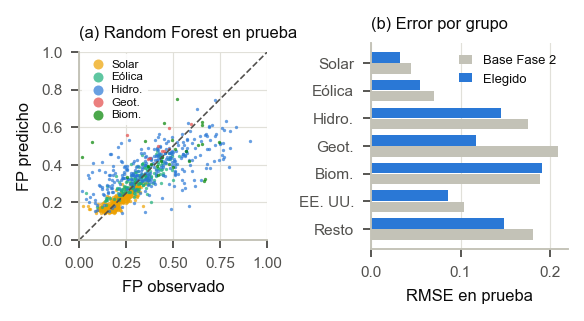

In [25]:
info_pru = partes["prueba"][["tecnologia", "country"]].assign(tecnologia=lambda d: d["tecnologia"].astype(str))
p_base_r, p_mejor_r = pred_pru_reg["Lineal base de la Fase 2"], pred_pru_reg[MEJOR_REG]
p_base_c, p_mejor_c = pred_pru_clf["Logística base de la Fase 2"], pred_pru_clf[MEJOR_CLF]
filas_err = []
grupos_err = [(t, info_pru["tecnologia"] == t) for t in TEC_MODELO] + [
    ("EE. UU.", info_pru["country"] == "USA"), ("Resto del mundo", info_pru["country"] != "USA"), ("Todas", info_pru["country"].notna())]
for nombre, mascara in grupos_err:
    m = mascara.values
    filas_err.append({"grupo": nombre, "plantas": int(m.sum()), "FP medio": y_pru[m].mean(),
                      "RMSE base": np.sqrt(mean_squared_error(y_pru[m], p_base_r[m])),
                      "RMSE elegido": np.sqrt(mean_squared_error(y_pru[m], p_mejor_r[m])),
                      "MAE elegido": mean_absolute_error(y_pru[m], p_mejor_r[m]),
                      "R² base": r2_score(y_pru[m], p_base_r[m]), "R² elegido": r2_score(y_pru[m], p_mejor_r[m]),
                      "sesgo elegido": (p_mejor_r[m] - y_pru[m]).mean(),
                      "F1 base": f1_score(yc_pru[m], p_base_c[m], average="macro"),
                      "F1 elegido": f1_score(yc_pru[m], p_mejor_c[m], average="macro")})
errores = pd.DataFrame(filas_err)
errores["reducción RMSE (%)"] = (1 - errores["RMSE elegido"] / errores["RMSE base"]) * 100
display(Markdown("**Errores en prueba por tecnología y región (Tabla VII)** · el R² dentro de una tecnología mide cuánto se explica *además* de la tecnología"))
display(errores.style.format({c: "{:.3f}" for c in errores.columns if c not in ("grupo", "plantas", "reducción RMSE (%)")}
                             | {"reducción RMSE (%)": "{:.0f}"}).hide(axis="index"))

with plt.rc_context(ESTILO_INFORME):
    fig, axes = plt.subplots(1, 2, figsize=(ANCHO_COLUMNA, 1.9), gridspec_kw={"width_ratios": [1, 1.05]})
    ax = axes[0]
    for t in TEC_MODELO:
        m = (info_pru["tecnologia"] == t).values
        ax.scatter(y_pru[m], p_mejor_r[m], s=2, color=TEC_COLOR[t], alpha=0.7, lw=0, label=TEC_CORTA[t])
    ax.plot([0, 1], [0, 1], color=TINTA2, lw=0.7, ls="--")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal")
    ax.set_xlabel("FP observado"); ax.set_ylabel("FP predicho")
    ax.legend(markerscale=3, fontsize=5, loc="upper left", handletextpad=0.1, borderaxespad=0.2, labelspacing=0.2,
              frameon=True, facecolor="white", edgecolor="none", framealpha=0.9)
    titulo_panel(ax, f"(a) {MEJOR_REG} en prueba")
    ax = axes[1]
    sub = errores.set_index("grupo").loc[TEC_MODELO + ["EE. UU.", "Resto del mundo"]]
    y_pos = np.arange(len(sub))
    ax.barh(y_pos + 0.2, sub["RMSE base"], height=0.38, color=GRIS, label="Base Fase 2")
    ax.barh(y_pos - 0.2, sub["RMSE elegido"], height=0.38, color=AZUL, label="Elegido")
    ax.set_yticks(y_pos, [TEC_CORTA.get(g, g).replace("Resto del mundo", "Resto") for g in sub.index])
    ax.invert_yaxis(); ax.set_xlabel("RMSE en prueba"); ax.grid(axis="y", visible=False)
    ax.legend(fontsize=5.5, loc="upper right", handlelength=1)
    titulo_panel(ax, "(b) Error por grupo")
    fig.tight_layout(w_pad=1.0)
    guardar_fig3(fig, "fig4_errores_prueba.png")
    plt.show()

**Figura 4.** Conjunto de prueba: (a) factor de planta predicho por el regresor elegido frente al observado, por tecnología (la diagonal es la predicción perfecta); (b) RMSE del modelo base de la Fase 2 y del regresor elegido por tecnología y por región.

- **La mejora llega a casi todas las tecnologías.** El error baja un 29 % en la solar (RMSE de 0.045 a 0.032), un 22 % en la eólica y un 17 % en la hidroeléctrica. Dentro de cada tecnología, el R² mide cuánto se explica *además* de la tecnología: en la solar pasa de 0.34 a 0.67 y en la eólica de 0.37 a 0.61, así que el modelo ya distingue una planta solar buena de una mala, no solo la solar de la eólica.
- **La hidroeléctrica y la biomasa siguen siendo las más difíciles** (RMSE de 0.145 y 0.191). Su FP depende de variables que la GPPD no tiene: el caudal y el año hidrológico, el tipo de central (embalse o filo de agua) y la disponibilidad de combustible y el despacho. En la biomasa (25 plantas de prueba) el modelo no mejora a la base. La geotérmica (9 plantas) mejora en RMSE, pero con tan pocas plantas su R² no es interpretable.
- **La brecha geográfica se reduce, pero persiste.** Fuera de EE. UU. (101 plantas de prueba, casi todas hidroeléctricas), el R² sube de 0.13 a 0.41 y el F1 de 0.56 a 0.62. En EE. UU. el R² llega a 0.65. El sesgo medio es casi nulo en ambos grupos (−0.016 y −0.000): el modelo no sobrestima ni subestima sistemáticamente fuera de EE. UU., pero allí es menos preciso.

## 5.4 Interpretabilidad: importancia por permutación y valores SHAP (Figura 5)

Dos técnicas complementarias:
- **Importancia por permutación** (agnóstica al modelo): cuánto empeora la métrica de validación si se barajan al azar los valores de una variable **original** (antes del preprocesamiento), rompiendo su relación con el objetivo. Se repite 10 veces por variable. Se aplica al regresor y al clasificador elegidos.
- **Valores SHAP** [Lundberg y Lee, 2017]: reparten la predicción de cada planta entre sus variables según la teoría de juegos (valores de Shapley), de modo que la suma de los aportes más el valor medio da exactamente la predicción. Se calculan con el algoritmo exacto para árboles (TreeSHAP) incluido en XGBoost, sobre el regresor XGBoost de la §2.2, en las plantas de validación. Muestran no solo *cuánto* importa una variable, sino *en qué dirección* y *para quién*.

**Importancia por permutación en validación** (regresor: Random Forest; clasificador: Random Forest)

,caída de R² (regresión),± R²,caída de F1 (clasificación),± F1
Tecnología,0.556,0.024,0.258,0.010
Edad,0.111,0.012,0.084,0.013
Longitud,0.099,0.005,0.092,0.008
Irradiación rel.,0.073,0.007,0.023,0.008
Capacidad (log),0.070,0.013,0.060,0.010
País,0.056,0.009,0.026,0.003
Latitud,0.055,0.006,0.024,0.006
Densidad,0.030,0.006,0.020,0.012


**Media del |valor SHAP| por variable (XGBoost, validación; puntos de FP)**

,media |SHAP|
Tecnología,0.0542
Capacidad (log),0.0216
Longitud,0.0171
Edad,0.0164
Irradiación rel.,0.0121
Latitud,0.0079
Densidad,0.0066
País,0.0058
Falta el año,0.0007


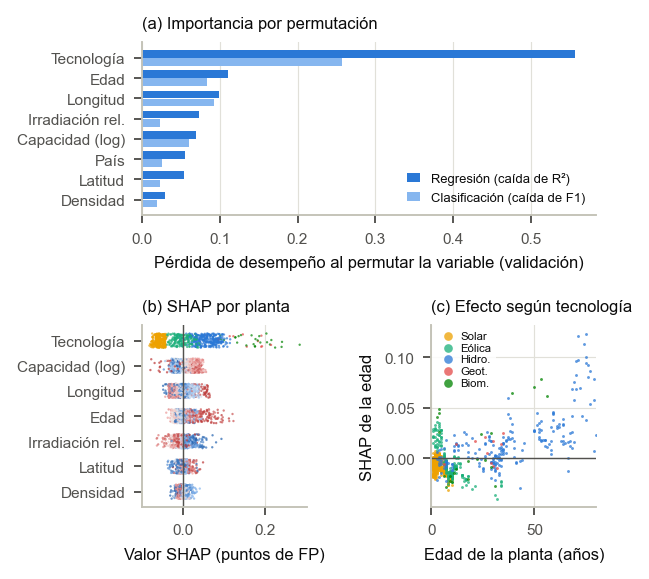

**Efecto de la edad según la tecnología (SHAP de XGBoost, validación)**

,pendiente por 10 años,ρ de Spearman,edad mín.,edad máx.
Solar,-0.016426,-0.360578,1,11
Eólica,-0.019231,-0.770938,1,34
Hidroeléctrica,0.006666,0.759709,3,120
Geotérmica,0.001875,0.059226,6,35
Biomasa,0.011647,0.290523,3,56


Solar: ρ de Spearman entre la longitud y su valor SHAP = -0.77 (negativa: más al oeste, mayor FP predicho)
Aporte medio de la tecnología (SHAP) por tecnología (puntos de FP): {'Solar': -0.05700000002980232, 'Eólica': -0.003000000026077032, 'Hidroeléctrica': 0.05700000002980232, 'Geotérmica': 0.15000000596046448, 'Biomasa': 0.17399999499320984}


In [26]:
VARIABLES_ORIG = {"tecnologia": "Tecnología", "country": "País", "log_capacidad": "Capacidad (log)",
                  "irradiacion_relativa": "Irradiación rel.", "densidad_misma_tec": "Densidad", "edad_planta": "Edad",
                  "latitude": "Latitud", "longitude": "Longitud"}
imp_r = permutation_importance(MODELOS_REG[MEJOR_REG], X_val, y_val, scoring="r2", n_repeats=10, random_state=SEMILLA, n_jobs=-1)
imp_c = permutation_importance(MODELOS_CLF[MEJOR_CLF], X_val, yc_val, scoring="f1_macro", n_repeats=10, random_state=SEMILLA, n_jobs=-1)
importancia = pd.DataFrame({"caída de R² (regresión)": imp_r.importances_mean, "± R²": imp_r.importances_std,
                            "caída de F1 (clasificación)": imp_c.importances_mean, "± F1": imp_c.importances_std},
                           index=[VARIABLES_ORIG[c] for c in X_val.columns]).sort_values("caída de R² (regresión)", ascending=False)
display(Markdown(f"**Importancia por permutación en validación** (regresor: {MEJOR_REG}; clasificador: {MEJOR_CLF})"))
display(importancia.style.format("{:.3f}"))

# SHAP exacto para árboles con XGBoost (pred_contribs): una columna por variable transformada + el sesgo
xgb_pipe = MODELOS_REG["XGBoost"]
Xt_val = xgb_pipe.named_steps["prep"].transform(X_val)
contrib = xgb_pipe.named_steps["modelo"].get_booster().predict(xgboost.DMatrix(Xt_val), pred_contribs=True)
shap_val = pd.DataFrame(contrib[:, :-1], columns=Xt_val.columns, index=Xt_val.index)
assert np.allclose(contrib.sum(1), xgb_pipe.predict(X_val), atol=1e-4)    # propiedad de eficiencia de Shapley
cols_tec = [c for c in shap_val.columns if c.startswith("tecnologia_")]
NOMBRE_SHAP = {"country": "País", "log_capacidad": "Capacidad (log)", "irradiacion_relativa": "Irradiación rel.",
               "densidad_misma_tec": "Densidad", "edad_planta": "Edad", "latitude": "Latitud", "longitude": "Longitud",
               "missingindicator_edad_planta": "Falta el año"}
shap_grupo = shap_val.drop(columns=cols_tec).rename(columns=NOMBRE_SHAP)
shap_grupo.insert(0, "Tecnología", shap_val[cols_tec].sum(axis=1))     # aporte conjunto de las variables de tecnología
valor_grupo = Xt_val.drop(columns=cols_tec).rename(columns=NOMBRE_SHAP)
orden_shap = shap_grupo.abs().mean().sort_values(ascending=False)
display(Markdown("**Media del |valor SHAP| por variable (XGBoost, validación; puntos de FP)**"))
display(orden_shap.to_frame("media |SHAP|").style.format("{:.4f}"))

tec_val = X_val["tecnologia"].values
with plt.rc_context(ESTILO_INFORME):
    fig = plt.figure(figsize=(ANCHO_COLUMNA, 3.55))
    gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.05], hspace=0.62, wspace=0.75)
    ax = fig.add_subplot(gs[0, :])
    imp_plot = importancia.iloc[::-1]
    y_pos = np.arange(len(imp_plot))
    ax.barh(y_pos + 0.2, imp_plot["caída de R² (regresión)"], height=0.38, color=AZUL, label="Regresión (caída de R²)")
    ax.barh(y_pos - 0.2, imp_plot["caída de F1 (clasificación)"], height=0.38, color="#86b6ef", label="Clasificación (caída de F1)")
    ax.set_yticks(y_pos, imp_plot.index); ax.grid(axis="y", visible=False)
    ax.set_xlabel("Pérdida de desempeño al permutar la variable (validación)")
    ax.legend(fontsize=5.5, loc="lower right", handlelength=1)
    titulo_panel(ax, "(a) Importancia por permutación")
    ax = fig.add_subplot(gs[1, 0])
    top = orden_shap.index[:7][::-1]
    for i, var in enumerate(top):
        sv = shap_grupo[var].values
        if var == "Tecnología":
            colores = [TEC_COLOR[t] for t in tec_val]
        else:
            v = valor_grupo[var].values
            colores = CMAP_DIV((pd.Series(v).rank(pct=True)).values)
        jitter = np.random.default_rng(i).uniform(-0.28, 0.28, len(sv))
        ax.scatter(sv, i + jitter, s=1, c=colores, lw=0, alpha=0.7)
    ax.axvline(0, color=TINTA2, lw=0.6)
    ax.set_yticks(range(len(top)), top); ax.grid(axis="y", visible=False)
    ax.set_xlabel("Valor SHAP (puntos de FP)")
    titulo_panel(ax, "(b) SHAP por planta")
    ax = fig.add_subplot(gs[1, 1])
    edad_val = X_val["edad_planta"].values
    for t in TEC_MODELO:
        m = (tec_val == t) & ~np.isnan(edad_val)
        ax.scatter(edad_val[m], shap_grupo["Edad"].values[m], s=1.5, color=TEC_COLOR[t], lw=0, alpha=0.75, label=TEC_CORTA[t])
    ax.axhline(0, color=TINTA2, lw=0.6)
    ax.set_xlim(0, 80)
    ax.set_xlabel("Edad de la planta (años)"); ax.set_ylabel("SHAP de la edad")
    ax.legend(markerscale=3, fontsize=4.8, loc="upper left", handletextpad=0.05, borderaxespad=0.1, labelspacing=0.15,
              frameon=True, facecolor="white", edgecolor="none", framealpha=0.85)
    titulo_panel(ax, "(c) Efecto según tecnología")
    guardar_fig3(fig, "fig5_interpretabilidad.png")
    plt.show()

# Efecto de la edad por tecnología: pendiente del SHAP de la edad frente a la edad (puntos de FP por cada 10 años)
pend = {}
for t in TEC_MODELO:
    m = (tec_val == t) & X_val["edad_planta"].notna().values
    r_ = stats.linregress(X_val["edad_planta"].values[m], shap_grupo["Edad"].values[m])
    pend[t] = {"pendiente por 10 años": r_.slope * 10, "ρ de Spearman": stats.spearmanr(X_val["edad_planta"].values[m], shap_grupo["Edad"].values[m])[0],
               "edad mín.": X_val["edad_planta"].values[m].min(), "edad máx.": X_val["edad_planta"].values[m].max()}
display(Markdown("**Efecto de la edad según la tecnología (SHAP de XGBoost, validación)**"))
display(pd.DataFrame(pend).T.style.format("{:.3f}").format({"edad mín.": "{:.0f}", "edad máx.": "{:.0f}"}))
m_sol = tec_val == "Solar"
print("Solar: ρ de Spearman entre la longitud y su valor SHAP =",
      round(stats.spearmanr(X_val["longitude"].values[m_sol], shap_grupo["Longitud"].values[m_sol])[0], 2),
      "(negativa: más al oeste, mayor FP predicho)")
print("Aporte medio de la tecnología (SHAP) por tecnología (puntos de FP):",
      shap_grupo["Tecnología"].groupby(tec_val).mean().reindex(TEC_MODELO).round(3).to_dict())

**Figura 5.** Interpretabilidad: (a) importancia por permutación de cada variable original en validación para el regresor y el clasificador elegidos; (b) valores SHAP del regresor XGBoost por planta para las siete variables más influyentes (color: tecnología en la primera fila; en las demás, valor de la variable de azul = bajo a rojo = alto); (c) aporte SHAP de la edad de la planta según la tecnología (eje recortado a 80 años).

- **La tecnología domina** con las dos técnicas: al permutarla, el R² de validación cae 0.56 y el F1 0.26, cinco veces más que cualquier otra variable. En SHAP, su aporte medio va de −0.06 puntos de FP en la solar a +0.06 en la hidroeléctrica, +0.15 en la geotérmica y +0.17 en la biomasa, el mismo orden de la Fase 1, ahora como efecto ajustado por las demás variables.
- **Después vienen la edad, la ubicación y la escala.** La edad (0.11), la longitud (0.10), la irradiación (0.07), la capacidad (0.07), el país (0.06) y la latitud (0.06). La latitud y la irradiación relativa son casi la misma información, así que su importancia se reparte entre ambas (juntas suman 0.13, más que la edad). En la solar, la longitud capta el recurso del suroeste de EE. UU.: cuanto más al oeste, mayor el FP predicho (ρ = −0.77 entre la longitud y su valor SHAP).
- **El efecto de la edad depende de la tecnología** (Fig. 5c), lo que confirma la paradoja de Simpson de la Fase 1. En la **eólica**, cada década de antigüedad resta unos 1.9 puntos de FP (ρ = −0.77): las turbinas más nuevas, más altas y con aspas más largas, rinden más. En la **solar** la pendiente es parecida (−1.6 puntos por década), pero solo hay plantas de 1 a 11 años, coherente con una degradación de los paneles del orden de 0.5 % al año. En la **hidroeléctrica** sucede lo contrario (+0.7 puntos por década; ρ = +0.76): las centrales más antiguas que siguen operando suelen ser las de embalse grande, un efecto de supervivencia.
- La densidad de plantas de la misma tecnología es la variable menos importante (0.03), coherente con la Fase 2, donde su hipótesis no se sostuvo en el modelo lineal.

# 6. Evaluación integral: del factor de planta a la decisión

Los modelos de las secciones 2 a 5 responden **qué explica el rendimiento técnico de una planta**. Pero la pregunta del proyecto habla de **desempeño integral**, y el rendimiento es solo uno de sus componentes: una tecnología con factor de planta alto puede ser cara, contaminante o depender de minerales escasos. El Entregable 2 anunció que la Fase 3 ampliaría el índice exploratorio de la Fase 1 (cuatro dimensiones calculadas con la GPPD) con criterios externos. Esta sección lo hace de forma resumida, con el análisis multicriterio que acompañó al Entregable 1:

1. **Trayectoria 2000–2025** con la serie mundial de IRENA: ¿qué tecnologías crecen y cuáles mejoran su rendimiento con el tiempo?
2. **Matriz de 14 criterios en 5 pilares** (confiabilidad; economía y acceso; ambiente y seguridad; materiales y circularidad; trayectoria), con datos de la GPPD, IRENA, el IPCC, la IEA y la literatura revisada por pares.
3. **Simulación de Monte Carlo** (20 000 escenarios): pesos al azar (Dirichlet uniforme, cualquier combinación de prioridades es igual de probable) y datos dentro de su incertidumbre; se ordena con suma ponderada (SAW) y con TOPSIS [Hwang y Yoon, 1981].

**Los 14 criterios** (los tres de materiales y circularidad forman el análisis de fin de vida de la §6.3):

| Pilar | # | Criterio | Qué mide | Sentido | Fuente |
|---|---|---|---|---|---|
| Confiabilidad | 1 | Rendimiento | Factor de planta (promedio de la mediana de la GPPD y el de plantas nuevas de IRENA) | Mayor es mejor | GPPD e IRENA (2025) |
| | 2 | Estabilidad | 1 − coeficiente de variación interanual del factor de planta | Mayor es mejor | GPPD |
| | 3 | Despachabilidad | Parte de la energía que se entrega cuando se necesita, sin pasar por baterías | Mayor es mejor | Supuesto documentado (solar 30–60 % y eólica 10–40 % por baterías) |
| Economía y acceso | 4 | Costo | Costo nivelado de la electricidad (USD/MWh) | Menor es mejor | IRENA (2025 y 2026) |
| | 5 | Versatilidad | Número de países con plantas de la tecnología | Mayor es mejor | GPPD |
| Ambiente y seguridad | 6 | Emisiones | Emisiones de ciclo de vida (gCO₂eq/kWh) | Menor es mejor | IPCC AR5, Anexo III |
| | 7 | Uso de suelo | Intensidad de uso de suelo (ha/TWh/año) | Menor es mejor | Lovering et al. (2022) |
| | 8 | Seguridad | Muertes por accidentes y contaminación (por TWh) | Menor es mejor | Our World in Data |
| Materiales y circularidad | 9 | Minerales críticos | kg de minerales críticos por GWh entregado, incluidas las baterías | Menor es mejor | IEA (2021 y 2024) |
| | 10 | **Reciclabilidad** | % de la masa de los equipos recuperable al desmantelar la planta | Mayor es mejor | Industria del acero y de la eólica; directiva RAEE |
| | 11 | Vida útil | Años de diseño | Mayor es mejor | IPCC AR5, Anexo III |
| Trayectoria y futuro | 12 | Dinamismo de costos | Caída del costo nivelado entre 2010 y 2025 (%) | Mayor caída es mejor | IRENA (2026) |
| | 13 | Crecimiento | Crecimiento anual de la capacidad mundial 2015–2024 (%) | Mayor es mejor | IRENASTAT |
| | 14 | Mejora del rendimiento | Tendencia del factor de planta mundial 2005–2024 (puntos por década) | Mayor es mejor | IRENASTAT |

## 6.1 Trayectoria 2000–2025 (IRENASTAT)

In [27]:
API_IRENA = "https://pxweb.irena.org/api/v1/en/IRENASTAT/Power%20Capacity%20and%20Generation"
DIR_IRENA = RAIZ / "data" / "raw" / "irenastat"
RUTA_IRENA = DIR_IRENA / "irenastat_mundo_por_tecnologia.csv"
TECS = TEC_MODELO
MAPA_IRENA = {"Solar": "Solar energy", "Eólica": "Wind energy", "Hidroeléctrica": "Renewable hydropower",
              "Geotérmica": "Geothermal energy", "Biomasa": "Bioenergy"}
# Valores de respaldo calculados el 9 de noviembre de 2026 con IRENASTAT (edición 2026-H2), por si la API no responde
RESPALDO_IRENA = pd.DataFrame({
    "crec_15_24": [26.527, 11.760, 1.656, 2.934, 5.345], "crec_20_24": [27.118, 11.481, 1.321, 2.019, 4.118],
    "fp_tend": [1.9608, 2.6976, -2.0197, -2.7796, -2.2327], "fp_tend_se": [0.1496, 0.2251, 0.2601, 0.5175, 0.5728],
    "fp_2005": [0.1198, 0.2219, 0.4278, 0.7962, 0.5524], "fp_2024": [0.1454, 0.2653, 0.4008, 0.7320, 0.5019],
    "cap_2025_gw": [2396.7, 1291.0, 1295.8, 15.6, 155.4]}, index=TECS)


def irena_consulta(tabla, seleccion):
    # Consulta la API PxWeb de IRENA; las variables que no aparecen en «seleccion» se piden completas
    with urllib.request.urlopen(f"{API_IRENA}/{tabla}", timeout=120) as r:
        variables = json.load(r)["variables"]
    consulta = [{"code": v["code"], "selection": {"filter": "item", "values": v["values"] if v["code"] not in seleccion
                 else [c for c, t in zip(v["values"], v["valueTexts"]) if t in seleccion[v["code"]]]}} for v in variables]
    pedido = urllib.request.Request(f"{API_IRENA}/{tabla}", headers={"Content-Type": "application/json"},
                                    data=json.dumps({"query": consulta, "response": {"format": "csv"}}).encode())
    with urllib.request.urlopen(pedido, timeout=180) as r:
        return r.read()


try:
    if not RUTA_IRENA.exists():
        DIR_IRENA.mkdir(parents=True, exist_ok=True)
        with urllib.request.urlopen(API_IRENA, timeout=120) as r:
            tabla_region = sorted(t["id"] for t in json.load(r) if t["id"].startswith("Region_ELECSTAT"))[-1]
        print("Descargando la serie mundial de IRENASTAT:", tabla_region)
        RUTA_IRENA.write_bytes(irena_consulta(tabla_region, {"Region": ["World"]}))
    irena = pd.read_csv(RUTA_IRENA, encoding="latin-1")
    irena.columns = ["region", "tecnologia", "tipo", "anio", "valor"]
    irena["valor"] = pd.to_numeric(irena["valor"], errors="coerce")
    serie = (irena.assign(t=np.where(irena["tipo"].str.contains("Capacity"), "cap_mw", "gen_gwh"))
             .pivot_table(index=["tecnologia", "anio"], columns="t", values="valor").reset_index().sort_values(["tecnologia", "anio"]))
    # FP mundial del año: generación / (capacidad media del año × 8.76)
    serie["fp"] = serie["gen_gwh"] / (8.76 * serie.groupby("tecnologia")["cap_mw"].transform(lambda s: (s + s.shift(1)) / 2))
    serie = serie[serie["tecnologia"].isin(MAPA_IRENA.values())].replace({"tecnologia": {v: k for k, v in MAPA_IRENA.items()}})
    cap = serie.pivot(index="anio", columns="tecnologia", values="cap_mw")[TECS]
    fp_hist = serie.pivot(index="anio", columns="tecnologia", values="fp")[TECS]
    cagr = lambda a0, a1: ((cap.loc[a1] / cap.loc[a0]) ** (1 / (a1 - a0)) - 1) * 100
    trayectoria = pd.DataFrame({"crec_15_24": cagr(2015, 2024), "crec_20_24": cagr(2020, 2024),
                                "cap_2025_gw": cap.loc[cap.index.max()] / 1e3})
    for t in TECS:
        y = fp_hist[t].loc[2005:2024].dropna()
        r = stats.linregress(y.index, y.values)          # pendiente del FP mundial en puntos porcentuales por década
        trayectoria.loc[t, ["fp_tend", "fp_tend_se", "fp_tend_p", "fp_2005", "fp_2024"]] = \
            [r.slope * 1000, r.stderr * 1000, r.pvalue, y.iloc[0], y.iloc[-1]]
    trayectoria = trayectoria.astype(float)
    FUENTE_IRENA = f"IRENASTAT, {cap.index.min()}–{cap.index.max()}"
except Exception as error:                                # sin conexión: se usan los valores ya calculados
    print(f"No se pudo leer IRENASTAT ({error}); se usan los valores de respaldo")
    trayectoria, FUENTE_IRENA = RESPALDO_IRENA.copy(), "valores de respaldo (IRENASTAT 2026-H2)"
    trayectoria["fp_tend_p"] = np.nan

display(Markdown(f"**Trayectoria mundial por tecnología ({FUENTE_IRENA})**"))
display(trayectoria.rename(columns={"crec_15_24": "crec. anual 2015–2024 (%)", "crec_20_24": "crec. anual 2020–2024 (%)",
                                    "cap_2025_gw": "capacidad 2025 (GW)", "fp_tend": "tendencia del FP (pp/década)",
                                    "fp_tend_se": "error est.", "fp_tend_p": "p-valor", "fp_2005": "FP 2005", "fp_2024": "FP 2024"})
        .style.format("{:.2f}").format({"p-valor": "{:.1e}", "capacidad 2025 (GW)": "{:,.0f}"}))

# ¿La GPPD cuenta la misma historia? Edad frente al FP dentro de cada tecnología (plantas más nuevas = más a la izquierda)
rho_edad = {t: stats.spearmanr(dm.loc[dm["tecnologia"] == t, "edad_planta"], dm.loc[dm["tecnologia"] == t, "factor_planta_prom"],
                               nan_policy="omit")[0] for t in TECS}
print("Correlación de Spearman edad–FP dentro de cada tecnología (GPPD; negativa = las plantas nuevas rinden más):",
      {t: round(v, 2) for t, v in rho_edad.items()})

**Trayectoria mundial por tecnología (IRENASTAT, 2000–2025)**

,crec. anual 2015–2024 (%),crec. anual 2020–2024 (%),capacidad 2025 (GW),tendencia del FP (pp/década),error est.,p-valor,FP 2005,FP 2024
tecnologia,,,,,,,,
Solar,26.526563,27.117558,"2,397",1.960828,0.149565,1.2e-10,0.119796,0.145374
Eólica,11.759988,11.481224,"1,291",2.697587,0.225088,5.2e-10,0.221943,0.265290
Hidroeléctrica,1.655829,1.321235,"1,296",-2.019688,0.260104,3.7e-07,0.427798,0.400810
Geotérmica,2.934407,2.019461,16,-2.779562,0.517550,4.2e-05,0.796234,0.731992
Biomasa,5.344916,4.117824,155,-2.232741,0.572836,1.1e-03,0.552388,0.501922


Correlación de Spearman edad–FP dentro de cada tecnología (GPPD; negativa = las plantas nuevas rinden más): {'Solar': np.float64(-0.08), 'Eólica': np.float64(-0.46), 'Hidroeléctrica': np.float64(0.07), 'Geotérmica': np.float64(0.12), 'Biomasa': np.float64(0.19)}


## 6.2 Matriz de 14 criterios y simulación de Monte Carlo (Tabla VIII y Figura 6)

In [28]:
# --- Criterios calculados con la GPPD (mismo universo de la Fase 1) ---
universo = df[df["tecnologia"].isin(TECS)].assign(tecnologia=lambda d: d["tecnologia"].astype(str))
fp_g = universo[universo["tiene_generacion"]]
cv_g = fp_g[fp_g["cv_generacion"].notna()]
gppd = pd.DataFrame({
    "fp_gppd": fp_g.groupby("tecnologia")["factor_planta_prom"].median(),
    "cv_med": cv_g.groupby("tecnologia")["cv_generacion"].median(),
    "cv_q1": cv_g.groupby("tecnologia")["cv_generacion"].quantile(0.25),
    "cv_q3": cv_g.groupby("tecnologia")["cv_generacion"].quantile(0.75),
    "paises": universo.groupby("tecnologia")["country"].nunique(),
}).reindex(TECS).join(trayectoria)

# --- Criterios externos (verificados en las fuentes oficiales; ver referencias) ---
ext = pd.DataFrame({
    #                Solar   Eólica  Hidro    Geo      Biomasa
    "fp_irena":     [0.16,   0.36,   0.43,    0.85,    0.78],    # IRENA 2025: factor de planta de plantas nuevas
    "lcoe_2025":    [44,     33,     62,      89,      86],      # IRENA 2026: costo nivelado, USD/MWh
    "lcoe_2024":    [43,     34,     57,      60,      87],      # IRENA 2025: costo nivelado, USD/MWh
    "cambio_costo": [-89,    -71,    41,      53,      -3],      # IRENA 2026: % de cambio del costo 2010–2025
    "co2_min":      [18,     7,      1,       6,       130],     # IPCC AR5, Anexo III: gCO2eq/kWh (ciclo de vida)
    "co2_med":      [48,     11,     24,      38,      230],
    "co2_max":      [180,    56,     2200,    79,      420],
    "suelo_min":    [1,      70,     100,     10,      130],     # Lovering et al. (2022): ha/TWh/año
    "suelo_med":    [2000,   130,    650,     45,      2746],
    "suelo_max":    [2860,   12000,  15000,   195,     58000],
    "muertes":      [0.019,  0.035,  1.3,     np.nan,  4.63],    # Our World in Data: muertes/TWh
    "min_kg_mw":    [6790,   10160,  2750,    192990,  2670],    # IEA (2021): minerales críticos, kg/MW
    "min_f_lo":     [0.8,    0.8,    0.9,     0.8,     0.9],     # incertidumbre relativa de la intensidad
    "min_f_hi":     [1.2,    1.2,    1.4,     1.2,     1.4],
    "recic_med":    [85,     87.5,   75,      85,      85],      # % de la masa recuperable al final de la vida
    "recic_min":    [80,     85,     50,      70,      74],
    "recic_max":    [95,     90,     95,      95,      96],
    "vida":         [25,     25,     50,      30,      40],      # IPCC AR5, Anexo III: vida útil de diseño (años)
    "f_alm":        [0.50,   0.25,   0.0,     0.0,     0.0],     # fracción de la energía que pasa por baterías
    "f_alm_min":    [0.30,   0.10,   0.0,     0.0,     0.0],
    "f_alm_max":    [0.60,   0.40,   0.0,     0.0,     0.0],
}, index=TECS)
BAT_KG_KWH, BAT_KG_KWH_MAX = 1.64, 2.21          # LFP a NMC 622: kg de minerales críticos por kWh (IEA 2021 y 2024)
CICLOS, CICLOS_MIN, CICLOS_MAX, DOD, GWH_POR_MW_ANIO = 5000, 3000, 7000, 0.90, 8.76
KG_GWH_BATERIA = BAT_KG_KWH / (CICLOS * DOD) * 1e6
datos = gppd.join(ext)

CRITERIOS = ["Rendimiento", "Estabilidad", "Despachabilidad", "Costo", "Versatilidad", "Emisiones", "Uso de suelo",
             "Seguridad", "Minerales críticos", "Reciclabilidad", "Vida útil", "Dinamismo de costos", "Crecimiento",
             "Mejora del rendimiento"]
BENEFICIO = {c: c not in ("Costo", "Emisiones", "Uso de suelo", "Seguridad", "Minerales críticos") for c in CRITERIOS}
LOG = {"Emisiones", "Uso de suelo", "Seguridad", "Minerales críticos"}
ABSOLUTO = {"Reciclabilidad": (0, 100), "Despachabilidad": (0, 1)}
PILAR = dict(zip(CRITERIOS, ["Confiabilidad"] * 3 + ["Economía y acceso"] * 2 + ["Ambiente y seguridad"] * 3
                 + ["Materiales y circularidad"] * 3 + ["Trayectoria y futuro"] * 3))
PILARES = list(dict.fromkeys(PILAR.values()))


def matriz_puntual(d, almacenamiento=True):
    m = pd.DataFrame(index=TECS)
    f_alm = d["f_alm"] if almacenamiento else d["f_alm"] * 0
    m["Rendimiento"] = (d["fp_gppd"] + d["fp_irena"]) / 2
    m["Estabilidad"] = 1 - d["cv_med"]
    m["Despachabilidad"] = 1 - f_alm
    m["Costo"], m["Versatilidad"] = d["lcoe_2025"], d["paises"]
    m["Emisiones"], m["Uso de suelo"], m["Seguridad"] = d["co2_med"], d["suelo_med"], d["muertes"].fillna(0.15)
    m["Minerales críticos"] = d["min_kg_mw"] / (m["Rendimiento"] * GWH_POR_MW_ANIO * d["vida"]) + f_alm * KG_GWH_BATERIA
    m["Reciclabilidad"], m["Vida útil"] = d["recic_med"], d["vida"]
    m["Dinamismo de costos"], m["Crecimiento"], m["Mejora del rendimiento"] = -d["cambio_costo"], d["crec_15_24"], d["fp_tend"]
    return m[CRITERIOS]


def normalizar(m):
    # 1 = la mejor de las cinco en ese criterio; escala log en los criterios que abarcan órdenes de magnitud
    z = m.copy().astype(float)
    for c in CRITERIOS:
        x = np.log10(z[c]) if c in LOG else z[c]
        if c in ABSOLUTO:
            x = (x - ABSOLUTO[c][0]) / (ABSOLUTO[c][1] - ABSOLUTO[c][0])
        else:
            x = (x - x.min()) / (x.max() - x.min())
        z[c] = x if BENEFICIO[c] else 1 - x
    return z


M_crit = matriz_puntual(datos)
Z_crit = normalizar(M_crit)
display(Markdown("**Matriz normalizada (1 = la mejor de las cinco en ese criterio)**"))
display(Z_crit.style.format("{:.2f}").background_gradient(cmap=CMAP_SEQ, vmin=0, vmax=1, axis=None))
display(Markdown("**Puntaje por pilar (promedio de sus criterios normalizados)**"))
display(pd.DataFrame({p: Z_crit[[c for c in CRITERIOS if PILAR[c] == p]].mean(axis=1) for p in PILARES})
        .style.format("{:.2f}").background_gradient(cmap=CMAP_SEQ, vmin=0, vmax=1, axis=None))

**Matriz normalizada (1 = la mejor de las cinco en ese criterio)**

,Rendimiento,Estabilidad,Despachabilidad,Costo,Versatilidad,Emisiones,Uso de suelo,Seguridad,Minerales críticos,Reciclabilidad,Vida útil,Dinamismo de costos,Crecimiento,Mejora del rendimiento
Solar,0.00,1.00,0.50,0.80,0.66,0.52,0.08,1.00,0.24,0.85,0.00,1.00,1.00,0.87
Eólica,0.32,0.85,0.75,1.00,0.34,1.00,0.74,0.89,0.34,0.88,0.00,0.87,0.41,1.00
Hidroeléctrica,0.46,0.00,1.00,0.48,1.00,0.74,0.35,0.23,0.94,0.75,1.00,0.08,0.00,0.14
Geotérmica,1.00,0.75,1.00,0.00,0.00,0.59,1.00,0.62,0.00,0.85,0.20,0.00,0.05,0.00
Biomasa,0.93,0.69,1.00,0.05,0.15,0.00,0.00,0.00,1.00,0.85,0.60,0.39,0.15,0.10


**Puntaje por pilar (promedio de sus criterios normalizados)**

,Confiabilidad,Economía y acceso,Ambiente y seguridad,Materiales y circularidad,Trayectoria y futuro
Solar,0.50,0.73,0.53,0.36,0.96
Eólica,0.64,0.67,0.88,0.41,0.76
Hidroeléctrica,0.49,0.74,0.44,0.90,0.07
Geotérmica,0.92,0.00,0.74,0.35,0.02
Biomasa,0.87,0.10,0.00,0.82,0.21


**Evaluación integral: 20,000 escenarios con pesos y datos inciertos (Tabla VIII)**

,% n.º 1 (SAW),% n.º 1 (TOPSIS),% entre las 2 mejores (SAW),puesto promedio (SAW),% n.º 1 sin baterías (SAW),crec. anual 2015–2024 (%),tendencia del FP (pp/década)
Eólica,35.910000,32.440000,83.090000,1.87,31.450000,11.759988,+2.70
Solar,45.720000,36.570000,79.805000,1.87,57.230000,26.526563,+1.96
Hidroeléctrica,12.395000,17.340000,21.570000,3.23,7.605000,1.655829,-2.02
Geotérmica,3.685000,7.845000,9.090000,3.82,2.290000,2.934407,-2.78
Biomasa,2.290000,5.805000,6.445000,4.21,1.425000,5.344916,-2.23


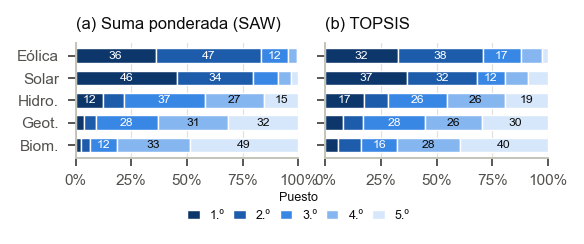

In [29]:
rng_mc = np.random.default_rng(SEMILLA)
N_SIM = 20_000


def muestrear_criterios(n, almacenamiento=True):
    # Cada criterio se sortea dentro de su incertidumbre documentada (arreglo n × tecnologías × criterios)
    d, T = datos, len(TECS)
    entre = lambda a, b: rng_mc.uniform(np.minimum(a, b), np.maximum(a, b), size=(n, T))
    tri_log = lambda lo, mo, hi: np.exp(rng_mc.triangular(np.log(lo), np.log(mo), np.log(hi), size=(n, T)))
    col = {"Rendimiento": entre(d.fp_gppd.values, d.fp_irena.values),
           "Estabilidad": 1 - rng_mc.uniform(d.cv_q1.values, d.cv_q3.values, size=(n, T))}
    f_alm = entre(d.f_alm_min.values, d.f_alm_max.values) if almacenamiento else np.zeros((n, T))
    col["Despachabilidad"] = 1 - f_alm
    col["Costo"] = entre(d.lcoe_2024.values, d.lcoe_2025.values)
    col["Versatilidad"] = np.tile(d.paises.values.astype(float), (n, 1))
    col["Emisiones"] = tri_log(d.co2_min.values, d.co2_med.values, d.co2_max.values)
    col["Uso de suelo"] = tri_log(d.suelo_min.values, d.suelo_med.values, d.suelo_max.values)
    seg = np.tile(d.muertes.values.astype(float), (n, 1))
    falta = np.isnan(seg)
    seg[falta] = np.exp(rng_mc.uniform(np.log(0.019), np.log(1.3), size=falta.sum()))   # geotérmica: entre solar e hidro
    col["Seguridad"] = seg
    vida = rng_mc.uniform(d.vida.values, 1.5 * d.vida.values, size=(n, T))
    intensidad = d.min_kg_mw.values * rng_mc.uniform(d.min_f_lo.values, d.min_f_hi.values, size=(n, T))
    bat = rng_mc.uniform(BAT_KG_KWH, BAT_KG_KWH_MAX, size=(n, 1)) / (rng_mc.uniform(CICLOS_MIN, CICLOS_MAX, size=(n, 1)) * DOD) * 1e6
    col["Minerales críticos"] = intensidad / (col["Rendimiento"] * GWH_POR_MW_ANIO * vida) + f_alm * bat
    col["Reciclabilidad"] = rng_mc.triangular(d.recic_min.values, d.recic_med.values, d.recic_max.values, size=(n, T))
    col["Vida útil"] = vida
    col["Dinamismo de costos"] = np.tile(-d.cambio_costo.values.astype(float), (n, 1))
    col["Crecimiento"] = entre(d.crec_15_24.values, d.crec_20_24.values)
    col["Mejora del rendimiento"] = rng_mc.normal(d.fp_tend.values, d.fp_tend_se.values, size=(n, T))
    return np.stack([col[c] for c in CRITERIOS], axis=2)


def normalizar_sim(X):
    X = X.copy()
    for j, c in enumerate(CRITERIOS):
        x = np.log10(X[:, :, j]) if c in LOG else X[:, :, j]
        if c in ABSOLUTO:
            z = (x - ABSOLUTO[c][0]) / (ABSOLUTO[c][1] - ABSOLUTO[c][0])
        else:
            mn, mx = x.min(1, keepdims=True), x.max(1, keepdims=True)
            z = np.where(mx > mn, (x - mn) / np.where(mx > mn, mx - mn, 1), 0.5)
        X[:, :, j] = z if BENEFICIO[c] else 1 - z
    return X


def simular(n, metodo="SAW", almacenamiento=True, criterios=None):
    # criterios: subconjunto que recibe peso (por defecto, los 14); los pesos se sortean con una Dirichlet uniforme
    Zs = normalizar_sim(muestrear_criterios(n, almacenamiento))
    activos = [j for j, c in enumerate(CRITERIOS) if criterios is None or c in criterios]
    W = np.zeros((n, len(CRITERIOS)))
    W[:, activos] = rng_mc.dirichlet(np.ones(len(activos)), size=n)       # cualquier combinación de pesos es igual de probable
    W = W[:, None, :]
    if metodo == "SAW":
        s = (Zs * W).sum(2)
    else:                                                                  # TOPSIS: cercanía relativa al ideal
        v = Zs * W
        d_menos = np.sqrt((v ** 2).sum(2))
        s = d_menos / (np.sqrt(((v - W) ** 2).sum(2)) + d_menos)
    return (-s).argsort(1).argsort(1) + 1                                  # puesto de cada tecnología (1 = mejor)


P_SAW, P_TOP, P_SIN_BAT = simular(N_SIM, "SAW"), simular(N_SIM, "TOPSIS"), simular(N_SIM, "SAW", almacenamiento=False)
multicriterio = pd.DataFrame({
    "% n.º 1 (SAW)": (P_SAW == 1).mean(0) * 100, "% n.º 1 (TOPSIS)": (P_TOP == 1).mean(0) * 100,
    "% entre las 2 mejores (SAW)": (P_SAW <= 2).mean(0) * 100, "puesto promedio (SAW)": P_SAW.mean(0),
    "% n.º 1 sin baterías (SAW)": (P_SIN_BAT == 1).mean(0) * 100,
}, index=TECS).join(trayectoria[["crec_15_24", "fp_tend"]].rename(
    columns={"crec_15_24": "crec. anual 2015–2024 (%)", "fp_tend": "tendencia del FP (pp/década)"}))
multicriterio = multicriterio.sort_values("puesto promedio (SAW)")
display(Markdown(f"**Evaluación integral: {N_SIM:,} escenarios con pesos y datos inciertos (Tabla VIII)**"))
display(multicriterio.style.format("{:.1f}").format({"puesto promedio (SAW)": "{:.2f}", "tendencia del FP (pp/década)": "{:+.2f}"}))

with plt.rc_context(ESTILO_INFORME):
    fig, axes = plt.subplots(1, 2, figsize=(ANCHO_COLUMNA, 1.55), sharey=True)
    orden = multicriterio.index.tolist()[::-1]
    colores = ["#0d366b", "#1c5cab", "#3987e5", "#86b6ef", "#d6e6fb"]
    for ax, P, titulo in [(axes[0], P_SAW, "(a) Suma ponderada (SAW)"), (axes[1], P_TOP, "(b) TOPSIS")]:
        dist = pd.DataFrame({k: (P == k).mean(0) * 100 for k in range(1, 6)}, index=TECS).loc[orden]
        izquierda = np.zeros(len(orden))
        for k, color in zip(range(1, 6), colores):
            ax.barh([TEC_CORTA[t] for t in orden], dist[k], left=izquierda, color=color, edgecolor="white", linewidth=0.6,
                    height=0.66, label=f"{k}.º")
            for y, (val, x0) in enumerate(zip(dist[k], izquierda)):
                if val >= 12:
                    ax.text(x0 + val / 2, y, f"{val:.0f}", ha="center", va="center", fontsize=5.2, color="white" if k <= 3 else TINTA)
            izquierda += dist[k].values
        ax.set_xlim(0, 100); ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
        ax.grid(axis="y", visible=False); titulo_panel(ax, titulo)
    axes[1].legend(ncol=5, fontsize=5.3, loc="upper center", bbox_to_anchor=(-0.12, -0.2), handlelength=1, columnspacing=0.7,
                   title="Puesto", title_fontsize=5.3)
    fig.tight_layout()
    fig.subplots_adjust(wspace=0.12)
    guardar_fig3(fig, "fig6_multicriterio.png")
    plt.show()

**Figura 6.** Distribución del puesto de cada tecnología en 20 000 escenarios de pesos y datos inciertos con (a) suma ponderada y (b) TOPSIS; el número dentro de cada barra es el porcentaje de escenarios en ese puesto (se omite si es menor que 12 %).

- **Ninguna tecnología gana en todos los escenarios: la solar y la eólica comparten el primer lugar.** La solar queda primera en el 45.7 % de los escenarios con SAW y en el 36.6 % con TOPSIS; la eólica, en el 35.9 % y el 32.4 %. Las dos tienen el mismo puesto promedio (1.87), y la eólica es la más consistente: queda entre las dos mejores en el 83 % de los escenarios, frente al 80 % de la solar. Ninguna otra supera el 18 % de primeros puestos.
- **Por qué ganan.** La solar es la mejor en trayectoria (puntaje del pilar 0.96): es la que más crece (26.5 % al año entre 2015 y 2024), la que más ha bajado su costo (−89 % desde 2010) y su FP mundial mejora (+2.0 puntos por década). La eólica es la más pareja: no tiene ningún criterio muy débil, es la más limpia (pilar ambiental 0.88), la más barata y la que más mejora su rendimiento (+2.7 puntos por década).
- **Lo que dice el factor de planta no basta.** La geotérmica y la biomasa tienen los FP más altos (0.92 y 0.87 en el pilar de confiabilidad, coherente con su aporte SHAP de +0.15 y +0.17 puntos de FP), pero son las más caras y las que menos crecen. Además, su FP mundial **empeora** (−2.8 y −2.2 puntos por década), y la biomasa es la peor en emisiones, seguridad y uso de suelo. La hidroeléctrica es la mejor en materiales y durabilidad (0.90), pero casi no crece (1.7 % al año) y su rendimiento baja (−2.0 puntos por década).
- **La letra pequeña de las baterías.** Si no se contaran las baterías que la solar y la eólica necesitan para la noche y los días sin viento, la solar ganaría en el 57 % de los escenarios. Contarlas le resta 11 puntos, pero no le quita el primer lugar.
- **La GPPD cuenta la misma historia que IRENA.** Dentro de la eólica, las plantas más nuevas rinden más (ρ de Spearman entre edad y FP = −0.46), coherente con la mejora mundial de su FP; en la hidroeléctrica no hay relación (ρ = +0.07).

## 6.3 Fin de vida: ¿qué tan fácil es reciclar cada tecnología?

El pilar de **materiales y circularidad** del análisis anterior reúne tres criterios que describen qué pasa cuando una planta termina su vida útil:
- **Reciclabilidad**: porcentaje de la masa de los equipos que se puede recuperar al desmantelarlos (valor central y rango plausible, a partir de la industria del acero, de la eólica y de la normativa europea de residuos electrónicos).
- **Vida útil**: años de diseño (IPCC); cuanto más dura una planta, menos veces hay que fabricarla y desmantelarla por cada GWh entregado.
- **Minerales críticos**: kilogramos por GWh entregado durante toda la vida, incluidas las baterías que necesitan la solar y la eólica; son los materiales más difíciles de reponer.

Aquí se muestran en sus unidades originales y se responde una pregunta concreta: **¿qué tecnología gana si solo importara el fin de vida?** Se repite la simulación de Monte Carlo con peso solo en la reciclabilidad y con peso solo en el pilar de circularidad, y se mide cuánto cambia el resultado general si ese pilar se excluye.

In [30]:
MATERIALES = [c for c in CRITERIOS if PILAR[c] == "Materiales y circularidad"]
M_sin_bat = matriz_puntual(datos, almacenamiento=False)
fin_vida = pd.DataFrame({
    "reciclabilidad (% de la masa)": datos["recic_med"],
    "rango plausible (%)": datos["recic_min"].map("{:.0f}".format) + "–" + datos["recic_max"].map("{:.0f}".format),
    "vida útil (años)": datos["vida"],
    "minerales críticos sin baterías (kg/GWh)": M_sin_bat["Minerales críticos"],
    "minerales críticos con baterías (kg/GWh)": M_crit["Minerales críticos"],
    "puntaje del pilar (0–1)": Z_crit[MATERIALES].mean(axis=1),
}, index=TECS)
P_REC = simular(N_SIM, "SAW", criterios=["Reciclabilidad"])
P_MAT = simular(N_SIM, "SAW", criterios=MATERIALES)
P_SIN_MAT = simular(N_SIM, "SAW", criterios=[c for c in CRITERIOS if c not in MATERIALES])
fin_vida["% n.º 1 solo reciclabilidad"] = (P_REC == 1).mean(0) * 100
fin_vida["% n.º 1 solo pilar de circularidad"] = (P_MAT == 1).mean(0) * 100
fin_vida["% n.º 1 general sin el pilar"] = (P_SIN_MAT == 1).mean(0) * 100
fin_vida["% n.º 1 general (14 criterios)"] = multicriterio["% n.º 1 (SAW)"].reindex(TECS)
display(Markdown("**Fin de vida por tecnología y efecto del pilar de circularidad en la evaluación integral (Tabla IX)**"))
display(fin_vida.style.format({"reciclabilidad (% de la masa)": "{:.1f}", "vida útil (años)": "{:.0f}",
                               "minerales críticos sin baterías (kg/GWh)": "{:,.0f}", "minerales críticos con baterías (kg/GWh)": "{:,.0f}",
                               "puntaje del pilar (0–1)": "{:.2f}", "% n.º 1 solo reciclabilidad": "{:.1f}",
                               "% n.º 1 solo pilar de circularidad": "{:.1f}", "% n.º 1 general sin el pilar": "{:.1f}",
                               "% n.º 1 general (14 criterios)": "{:.1f}"}))

**Fin de vida por tecnología y efecto del pilar de circularidad en la evaluación integral (Tabla IX)**

,reciclabilidad (% de la masa),rango plausible (%),vida útil (años),minerales críticos sin baterías (kg/GWh),minerales críticos con baterías (kg/GWh),puntaje del pilar (0–1),% n.º 1 solo reciclabilidad,% n.º 1 solo pilar de circularidad,% n.º 1 general sin el pilar,% n.º 1 general (14 criterios)
Solar,85.0,80–95,25,174,356,0.36,27.3,0.3,55.5,45.7
Eólica,87.5,85–90,25,137,228,0.41,32.6,0.2,37.4,35.9
Hidroeléctrica,75.0,50–95,50,15,15,0.90,3.6,59.5,1.1,12.4
Geotérmica,85.0,70–95,30,"1,072","1,072",0.35,15.1,0.2,5.7,3.7
Biomasa,85.0,74–96,40,12,12,0.82,21.4,39.8,0.2,2.3


**Qué se recicla y qué no, por tecnología** (la reciclabilidad por masa no dice si se recupera lo valioso)

| Tecnología | Lo que se recicla bien | Lo difícil al final de la vida |
|---|---|---|
| Solar | Vidrio y marco de aluminio (≈ 80–90 % de la masa del panel); la directiva europea RAEE exige recuperar el 85 % | La plata, el silicio y el cobre, que son la mayor parte del **valor**, casi no se recuperan con los procesos actuales [Heath et al., 2020]; ola de residuos de paneles hacia 2050 |
| Eólica | Torre, góndola y cimentación (acero, cobre, hierro): ≈ 85–90 % de la masa | Las **aspas** de material compuesto (fibra de vidrio y resina): hoy van sobre todo a relleno o incineración; unos 43 millones de toneladas de residuos de aspas hacia 2050 [Liu y Barlow, 2017] |
| Hidroeléctrica | Turbinas y equipos de acero | La presa de concreto rara vez se desmantela (su «fin de vida» es su sedimentación); por eso el rango de reciclabilidad es tan amplio (50–95 %) |
| Geotérmica | Tuberías y equipos de acero y aceros especiales | Los pozos se sellan y no se recuperan; aceros con níquel y cromo (minerales críticos) |
| Biomasa | Calderas y turbinas de acero | Las cenizas de la combustión, que hay que gestionar como residuo |

- **Por masa, todas se reciclan parecido.** Entre el 75 % y el 88 % de la masa de los equipos se puede recuperar en las cinco tecnologías, porque casi todo es acero, concreto, vidrio o aluminio. Si solo importara la reciclabilidad, ninguna ganaría con claridad: la eólica queda primera en el 32.6 % de los escenarios, la solar en el 27.3 %, la biomasa en el 21.4 %, la geotérmica en el 15.1 % y la hidroeléctrica en el 3.6 %. Esta última queda atrás porque sus presas de concreto rara vez se desmantelan, así que su rango es muy amplio (50–95 %).
- **Pero la masa no cuenta lo difícil.** En la solar, lo que no se recupera hoy (plata, silicio y cobre) es poco peso pero la mayor parte del valor. En la eólica, las aspas de material compuesto son una fracción menor de la masa, pero casi no tienen reciclaje industrial. Por eso la tabla cualitativa importa tanto como el porcentaje.
- **Con todo el fin de vida, ganan la hidroeléctrica y la biomasa.** Si se mira todo el pilar de circularidad (reciclabilidad, vida útil y minerales críticos), la hidroeléctrica queda primera en el 59.5 % de los escenarios y la biomasa en el 39.8 %; la solar y la eólica casi nunca (≤ 0.3 %). Duran la mitad que una hidroeléctrica (25 frente a 50 años) y consumen más minerales críticos por GWh: 174 kg la solar y 137 la eólica, que suben a 356 y 228 al contar las baterías, frente a 12–15 kg de la hidroeléctrica y la biomasa. La geotérmica es la más intensiva en minerales (1 072 kg/GWh, por los aceros especiales de sus pozos).
- **El fin de vida es el punto débil de la solar y la eólica, pero no cambia la conclusión.** Sin el pilar de circularidad, la solar ganaría en el 55.5 % de los escenarios; con él, gana en el 45.7 %. Le cuesta 10 puntos, pero sigue primera, con la eólica a la par. La condición para que su ventaja sea sostenible es reciclar a escala lo valioso: la plata y el silicio de los paneles, y las aspas.

## 6.4 Productividad: ¿qué renovable entrega más energía con menos recursos?

Más paneles o más turbinas siempre dan más energía. La pregunta útil es otra: **por cada unidad de recurso invertido, ¿cuánta energía entrega cada tecnología?** Se responde con cuatro medidas, cada una con su fuente:

| Medida | Qué responde | Cálculo | Fuente |
|---|---|---|---|
| Energía por MW instalado | Si instalo la misma potencia, ¿cuál produce más? | factor de planta × 8 760 h | GPPD (mediana) e IRENA (plantas nuevas) |
| Energía por dólar | ¿Cuál produce más por cada dólar invertido y operado durante toda su vida? | 1 000 / costo nivelado (USD/MWh) | IRENA (2026) |
| Energía por cancha de fútbol | Si lleno un terreno del tamaño de una cancha (105 × 68 m ≈ 0.71 ha), ¿cuánta energía sale al año? | 0.714 ha / intensidad de uso de suelo | Lovering et al. (2022), Tabla 1 |
| Energía por material | ¿Cuánta energía entrega por cada tonelada de acero, concreto, vidrio, aluminio y demás materiales que hay que fabricar? | 1 / material por TWh durante toda la vida | DOE, *Quadrennial Technology Review 2015*, Tabla 10.4 (materiales a granel); IEA (2021) (minerales críticos) |

En la medida de terreno hay dos escenarios para la eólica y la biomasa: el **mejor caso** cuenta solo el área ocupada por los equipos (eólica) o el uso de residuos (biomasa), y el **peor caso** cuenta todo el espacio entre turbinas, que sigue sirviendo para cultivar o pastorear, o los cultivos sembrados solo para quemar.

In [31]:
# Materiales a granel por TWh entregado durante la vida de la planta, sin combustible (DOE, QTR 2015, Tabla 10.4; toneladas/TWh).
# En la biomasa el DOE cuenta solo la planta generadora, sin la cadena del combustible: su valor no es comparable con los demás.
MATERIALES_DOE = pd.DataFrame({
    "Acero": [7900, 1800, 67, 3300, 310], "Concreto": [350, 8000, 14000, 1100, 760], "Cemento": [3700, 0, 0, 750, 0],
    "Vidrio": [2700, 92, 0, 0, 0], "Aluminio": [680, 35, 0, 100, 6], "Cobre": [850, 23, 1, 2, 0],
    "Hierro": [0, 120, 0, 9, 4], "Plástico": [210, 190, 0, 0, 0], "Silicio": [57, 0, 0, 0, 0]}, index=TECS)
# Intensidad de uso de suelo, mediana (Lovering et al., 2022, Tabla 1; ha/TWh/año): (mejor caso, peor caso)
SUELO_LOVERING = {"Solar": (2000, 2000), "Eólica": (130, 12000), "Hidroeléctrica": (650, 650),
                  "Geotérmica": (45, 45), "Biomasa": (130, 58000)}
CANCHA_HA = 105 * 68 / 1e4                                    # cancha de fútbol reglamentaria: 0.714 ha

material_total = MATERIALES_DOE.sum(axis=1)
productividad = pd.DataFrame({
    "factor de planta": M_crit["Rendimiento"],
    "MWh por MW al año": M_crit["Rendimiento"] * 8760,
    "MWh por cada 1 000 USD": 1000 / datos["lcoe_2025"],
    "GWh/año por cancha (mejor caso)": [CANCHA_HA * 1000 / SUELO_LOVERING[t][0] for t in TECS],
    "GWh/año por cancha (peor caso)": [CANCHA_HA * 1000 / SUELO_LOVERING[t][1] for t in TECS],
    "materiales a granel (t/TWh)": material_total,
    "GWh por cada 1 000 t de materiales": 1e6 / material_total,
    "minerales críticos con baterías (kg/GWh)": M_crit["Minerales críticos"],
    "GWh por tonelada de minerales críticos": 1000 / M_crit["Minerales críticos"],
}, index=TECS)
puestos_prod = productividad[["MWh por MW al año", "MWh por cada 1 000 USD", "GWh/año por cancha (mejor caso)",
                              "GWh por cada 1 000 t de materiales", "GWh por tonelada de minerales críticos"]].rank(ascending=False).astype(int)
display(Markdown("**Productividad de cada tecnología: energía por MW, por dólar, por terreno y por material (Tabla X)**"))
display(productividad.style.format({"factor de planta": "{:.2f}", "MWh por MW al año": "{:,.0f}", "MWh por cada 1 000 USD": "{:.1f}",
                                    "GWh/año por cancha (mejor caso)": "{:.2f}", "GWh/año por cancha (peor caso)": "{:.3f}",
                                    "materiales a granel (t/TWh)": "{:,.0f}", "GWh por cada 1 000 t de materiales": "{:.0f}",
                                    "minerales críticos con baterías (kg/GWh)": "{:,.0f}", "GWh por tonelada de minerales críticos": "{:.1f}"}))
display(Markdown("**Puesto de cada tecnología en cada medida (1 = la que más energía entrega por unidad de recurso)**"))
display(puestos_prod)
display(Markdown("**Materiales a granel por TWh (DOE, toneladas/TWh)**"))
display(MATERIALES_DOE.assign(total=material_total).style.format("{:,.0f}"))

**Productividad de cada tecnología: energía por MW, por dólar, por terreno y por material (Tabla X)**

,factor de planta,MWh por MW al año,MWh por cada 1 000 USD,GWh/año por cancha (mejor caso),GWh/año por cancha (peor caso),materiales a granel (t/TWh),GWh por cada 1 000 t de materiales,minerales críticos con baterías (kg/GWh),GWh por tonelada de minerales críticos
Solar,0.18,"1,560",22.7,0.36,0.357,"16,447",61,356,2.8
Eólica,0.34,"2,972",30.3,5.49,0.059,"10,260",97,228,4.4
Hidroeléctrica,0.41,"3,599",16.1,1.10,1.098,"14,068",71,15,65.4
Geotérmica,0.69,"6,002",11.2,15.87,15.867,"5,261",190,"1,072",0.9
Biomasa,0.65,"5,704",11.6,5.49,0.012,"1,080",926,12,85.5


**Puesto de cada tecnología en cada medida (1 = la que más energía entrega por unidad de recurso)**

,MWh por MW al año,MWh por cada 1 000 USD,GWh/año por cancha (mejor caso),GWh por cada 1 000 t de materiales,GWh por tonelada de minerales críticos
Solar,5,2,5,5,4
Eólica,4,1,2,3,3
Hidroeléctrica,3,3,4,4,2
Geotérmica,1,5,1,2,5
Biomasa,2,4,2,1,1


**Materiales a granel por TWh (DOE, toneladas/TWh)**

,Acero,Concreto,Cemento,Vidrio,Aluminio,Cobre,Hierro,Plástico,Silicio,total
Solar,"7,900",350,"3,700","2,700",680,850,0,210,57,"16,447"
Eólica,"1,800","8,000",0,92,35,23,120,190,0,"10,260"
Hidroeléctrica,67,"14,000",0,0,0,1,0,0,0,"14,068"
Geotérmica,"3,300","1,100",750,0,100,2,9,0,0,"5,261"
Biomasa,310,760,0,0,6,0,4,0,0,"1,080"


**Interpretación de la productividad (Tabla X)**

**No hay una sola ganadora: depende de qué recurso se quiera ahorrar.**

- **Por dólar, gana la eólica.** Con 1 000 USD (costo de toda la vida de la planta: construcción, operación y mantenimiento) la eólica entrega unos 30 MWh, la solar 23, la hidroeléctrica 16, la biomasa 12 y la geotérmica 11. Es la respuesta directa a *«qué produce más energía a menos costo»*: la eólica, seguida de cerca por la solar.
- **Por MW instalado, gana la geotérmica.** Un MW geotérmico entrega unos 6 000 MWh al año y uno de biomasa 5 700, porque funcionan día y noche. La hidroeléctrica entrega 3 600, la eólica 3 000 y la solar 1 560, porque solo produce con sol. Instalar la misma potencia no es instalar la misma energía: un MW geotérmico rinde casi cuatro veces lo que un MW solar.
- **Por terreno, también gana la geotérmica.** Una cancha de fútbol (0.71 ha) ocupada por una planta geotérmica entrega unos 16 GWh al año. Con turbinas eólicas entrega 5.5 GWh si se cuenta solo el suelo que ocupan los equipos, pero solo 0.06 GWh si se cuenta el espacio entre turbinas, que de todos modos sigue sirviendo para cultivar o pastorear. Con una hidroeléctrica (incluido el embalse) salen 1.1 GWh, y **llena de paneles solares, 0.36 GWh al año**: la misma cancha con una planta geotérmica produciría unas 44 veces más. La biomasa va de 5.5 GWh si quema residuos a apenas 0.01 GWh si se siembran cultivos solo para quemar.
- **Por material, gana la geotérmica entre las comparables.** Por cada 1 000 toneladas de acero, concreto, vidrio, aluminio y demás materiales, la geotérmica entrega unos 190 GWh durante su vida, la eólica 97, la hidroeléctrica 71 (casi todo es el concreto de la presa) y la solar 61. La solar es la más intensiva en materiales: necesita mucho acero para las estructuras, y vidrio, aluminio y cemento. La biomasa aparece con 926 GWh, pero el DOE solo cuenta su planta generadora, sin los cultivos ni la cadena del combustible, así que no es comparable. En minerales críticos el orden cambia: la biomasa (83 GWh por tonelada) y la hidroeléctrica (67) son las más livianas, y la geotérmica la más intensiva (0.9) por los aceros especiales de sus pozos.

**Lectura conjunta.** La geotérmica es la más productiva por MW, por terreno y por material, pero es la más cara y solo es viable donde hay calor cerca de la superficie: unos 30 países la usan. La eólica es la más barata y la segunda más eficiente en materiales entre las comparables. La solar es la menos productiva por MW, por material y por terreno, pero es la segunda más barata y se puede instalar en techos y lugares ya construidos, sin ocupar terreno nuevo. Por eso, con todos los criterios, la solar y la eólica comparten el primer lugar del análisis integral, aunque ninguna sea la más productiva en sentido físico.

# 7. Respuesta a las preguntas de investigación

**PS1 (regresión): ¿en qué medida la tecnología, la capacidad, la ubicación y la antigüedad explican y permiten predecir el FP?** En buena medida. Con un modelo no lineal (Random Forest), esas variables explican el **62 % de la variación del FP en plantas nuevas** (R² = 0.623 en prueba; IC 95 %: 0.573–0.669), frente al 45 % del modelo lineal de la Fase 2, con un error típico de 9.5 puntos de FP. La tecnología es, de lejos, el factor dominante: al permutarla, el R² cae 0.56. Le siguen la edad, la longitud (que capta regiones de recurso), la capacidad y la irradiación. Lo que falta para explicar el resto está fuera de la base de datos: hidrología, tipo de central, combustible y despacho.

**PS2 (clasificación): ¿es posible clasificar el nivel de desempeño sin usar la generación observada?** Sí. El Random Forest clasifica correctamente **3 de cada 4 plantas nuevas** (F1-macro = 0.760; AUC-ROC = 0.916 en prueba) y casi nunca confunde un nivel bajo con uno alto (3.2 %). Esto permite estimar, antes de construir una planta, en qué tercio de desempeño probablemente quedará.

**PS3 (clustering): ¿qué segmentos naturales emergen?** La división dominante separa el **parque antiguo, gestionable y variable** (hidroeléctricas de unos 60 años con FP alto pero inestable) del **parque nuevo, pequeño y estable** (solares y eólicas de unos 6 años con FP menor pero muy constante). DBSCAN añade un tercer hallazgo: las plantas **atípicas** son sobre todo biomasa, geotérmica e hidroeléctricas grandes y antiguas. La separación es moderada (silueta 0.30, por debajo de la meta de 0.35): las plantas forman un continuo más que grupos nítidos.

**Las tres preguntas prácticas que motivan el proyecto:**
1. *¿Qué renovable tiene más ventajas que desventajas?* Con 14 criterios y 20 000 combinaciones de prioridades, **la solar y la eólica comparten el primer lugar** (solar 46 % de primeros puestos, eólica 36 %; mismo puesto promedio). La geotérmica y la biomasa rinden más por MW instalado, pero pierden en costo, crecimiento y (la biomasa) ambiente. Ninguna renovable es la mejor en todo.
2. *¿Cuál tiene mejor futuro tecnológico?* **La eólica y la solar**, por tres evidencias independientes que coinciden: su FP mundial sube (+2.7 y +2.0 puntos por década, p < 0.001), son las que más crecen y, dentro de la GPPD, las plantas eólicas más nuevas rinden más (el modelo atribuye unos −2 puntos de FP por cada 10 años de antigüedad). Las demás empeoran su rendimiento mundial.
3. *¿Qué renovable conviene a cada país?* Los modelos muestran que **la ubicación importa y que lo aprendido se transfiere parcialmente a regiones nuevas** (R² de 0.53 en bloques geográficos no vistos; 0.41 fuera de EE. UU.). Pero el 88 % de las plantas con FP está en EE. UU., así que una recomendación país por país todavía no es confiable con estos datos. El modelo y sus predicciones quedan listos para que el tablero de la Fase 4 los combine con el recurso solar y eólico de cada país.

**Visión holística.** Ninguna renovable es la mejor en todo: cada una gana unos criterios y pierde otros (matriz normalizada de la §6.2). La solar y la eólica tienen debilidades claras:
- La solar es la de menor rendimiento por MW (0.00 en la matriz), la de vida útil más corta (0.00) y una de las que más terreno ocupa (0.08).
- La eólica comparte la vida útil más corta y ocupa mucho terreno si se cuenta el espacio entre turbinas.
- La reciclabilidad de ambas solo está en el promedio (0.85 y 0.88): la plata y el silicio de los paneles y las aspas de las turbinas casi no se reciclan hoy.

Aun así, al combinar los 14 criterios **quedan primeras**, porque sus debilidades se compensan con fortalezas donde las demás fallan:
- Son las dos más baratas (0.80 y 1.00) y las más seguras (1.00 y 0.89); la eólica es la más limpia (1.00 en emisiones).
- Son las únicas cuyo costo cayó con fuerza desde 2010 (−89 % y −71 %) y cuyo rendimiento mundial mejora año tras año.

Las demás tienen debilidades más graves en criterios decisivos. La hidroeléctrica gana en versatilidad, materiales y vida útil, pero es la más inestable y casi no crece. La geotérmica y la biomasa rinden más por MW, pero son las más caras y su rendimiento mundial empeora. **De manera holística, la solar y la eólica son las renovables de mejor desempeño integral.** Para que esa ventaja sea sostenible hacen falta tres cosas: reciclar a escala lo valioso de paneles y aspas, aprovechar techos y suelos ya intervenidos, y complementarlas con almacenamiento y con la hidroeléctrica existente.

# 8. Auditoría de fuga de datos

Cada control se verifica con código sobre los objetos ya ajustados, no por declaración.

In [32]:
controles = []


def control(nombre, evidencia, ok):
    controles.append({"control": nombre, "evidencia": evidencia, "¿cumple?": "Sí" if ok else "NO"})


prohibidas = [c for c in PREDICTORES if c.startswith(("generation", "estimated", "factor_planta", "cv_", "n_anios"))]
control("Predictores sin información de la generación", f"{len(PREDICTORES)} predictores; prohibidos presentes: {prohibidas}", not prohibidas)
control("Partición idéntica a la Fase 2", "Tamaños 4 202 / 902 / 907 y umbral reproducido (§0.6)",
        tamanos.tolist() == [4202, 902, 907])
control("Ningún sitio en dos conjuntos", "Intersección vacía de sitios entre los tres conjuntos",
        not (sitios["entrenamiento"] & sitios["prueba"]) and not (sitios["entrenamiento"] & sitios["validación"]))
todos = list(MODELOS_REG.values()) + list(MODELOS_CLF.values())
control("Preprocesamiento dentro de cada modelo", f"{len(todos)} modelos son Pipeline con el paso «prep»",
        all(isinstance(m, Pipeline) and "prep" in m.named_steps for m in todos))
te_cv = [m.named_steps["prep"].named_steps["codificar_escalar"].named_transformers_["pais"].cv for m in todos]
control("Target Encoding con cross-fitting", f"cv interno del codificador del país: {sorted(set(te_cv))}", set(te_cv) == {5})
pliegue_ok = all(not set(grupos_ent.iloc[a]) & set(grupos_ent.iloc[b]) for a, b in cv_reg.split(X_ent, y_ent, grupos_ent))
control("Validación cruzada agrupada por sitio", "Ningún sitio a ambos lados de un pliegue de la búsqueda", pliegue_ok)
control("Cortes de las clases con entrenamiento", f"cortes = {np.round(cortes, 4).tolist()}",
        np.allclose(cortes, y_ent.quantile([1 / 3, 2 / 3]).values))
redes = [m.named_steps["modelo"] for m in todos if isinstance(m.named_steps["modelo"], _MLPTorch)]
control("Parada temprana de la MLP sin validación ni prueba", "La pérdida de parada sale del 15 % del propio ajuste",
        all(r.fraccion_parada > 0 for r in redes) and len(redes) == 2)
control("Clustering fuera de los modelos supervisados", "Las etiquetas de grupo no están entre los predictores",
        not any(c.startswith("grupo") for c in PREDICTORES))
control("Prueba usada una sola vez", "Métricas de prueba calculadas solo en §5.1 (y la verificación del umbral de la Fase 2 en §0.6)", True)
pd.DataFrame(controles).style.hide(axis="index").set_properties(**{"text-align": "left"})

control,evidencia,¿cumple?
Predictores sin información de la generación,8 predictores; prohibidos presentes: [],Sí
Partición idéntica a la Fase 2,Tamaños 4 202 / 902 / 907 y umbral reproducido (§0.6),Sí
Ningún sitio en dos conjuntos,Intersección vacía de sitios entre los tres conjuntos,Sí
Preprocesamiento dentro de cada modelo,10 modelos son Pipeline con el paso «prep»,Sí
Target Encoding con cross-fitting,cv interno del codificador del país: [5],Sí
Validación cruzada agrupada por sitio,Ningún sitio a ambos lados de un pliegue de la búsqueda,Sí
Cortes de las clases con entrenamiento,"cortes = [0.2054, 0.3234]",Sí
Parada temprana de la MLP sin validación ni prueba,La pérdida de parada sale del 15 % del propio ajuste,Sí
Clustering fuera de los modelos supervisados,Las etiquetas de grupo no están entre los predictores,Sí
Prueba usada una sola vez,Métricas de prueba calculadas solo en §5.1 (y la verificación del umbral de la Fase 2 en §0.6),Sí


# 9. Artefactos para la Fase 4 (tablero)

In [33]:
# Predicciones de los modelos elegidos para todas las plantas del conjunto de modelado (el tablero las usará)
X_todo = dm[PREDICTORES].assign(tecnologia=lambda d: d["tecnologia"].astype(str))
salida = dm[["gppd_idnr", "name", "country", "tecnologia", "capacity_mw", "latitude", "longitude", "anio_operacion",
             "factor_planta_prom", "conjunto"]].copy()
salida["fp_predicho"] = MODELOS_REG[MEJOR_REG].predict(X_todo)
proba_todo = MODELOS_CLF[MEJOR_CLF].predict_proba(X_todo)
salida["nivel_real"] = np.array(NIVELES)[a_clase(salida["factor_planta_prom"]).values]
salida["nivel_predicho"] = np.array(NIVELES)[proba_todo.argmax(1)]
for k, nivel in enumerate(NIVELES):
    salida[f"prob_{nivel.lower()}"] = proba_todo[:, k]
salida = salida.join(dc[["grupo_kmeans", "grupo_dbscan"]])
salida["grupo_kmeans"] = salida["grupo_kmeans"].map({g: f"G{ORDEN_GRUPOS.index(g) + 1}" for g in ORDEN_GRUPOS})
ruta_pred = DIR_PROC / "gppd_predicciones_fase3.csv"
salida.to_csv(ruta_pred, index=False, encoding="utf-8")

joblib.dump(MODELOS_REG[MEJOR_REG], DIR_MOD / "fase3_regresor_elegido.joblib")
joblib.dump(MODELOS_CLF[MEJOR_CLF], DIR_MOD / "fase3_clasificador_elegido.joblib")
joblib.dump(MODELOS_REG["XGBoost"], DIR_MOD / "fase3_regresor_xgboost_shap.joblib")

metricas = {
    "semilla": SEMILLA, "predictores": PREDICTORES,
    "regresion": {"elegido": MEJOR_REG, "validacion": res_reg.set_index("modelo")[["R² CV (media)", "R² validación", "RMSE validación", "MAE validación"]].round(4).to_dict("index"),
                  "prueba": prueba_reg[["R²", "RMSE", "MAE"]].round(4).to_dict("index"), "ic95_r2_prueba": np.round(ic_r2, 4).tolist()},
    "clasificacion": {"elegido": MEJOR_CLF, "validacion": res_clf.set_index("modelo")[["F1 CV (media)", "F1-macro validación", "AUC-ROC validación"]].round(4).to_dict("index"),
                      "prueba": prueba_clf.round(4).to_dict("index"), "ic95_f1_prueba": np.round(ic_f1, 4).tolist()},
    "hiperparametros": {f"{t} · {m}": e for t, m, e in tabla_hiper[["tarea", "modelo", "elegido"]].values},
    "clustering": {"k": int(K), "silueta_kmeans": round(float(sil_km), 4), "silueta_ward": round(float(sil_ward), 4),
                   "ari_kmeans_ward": round(float(ari), 4), "dbscan_eps": round(EPS, 4), "dbscan_ruido_pct": round(float(ruido.mean() * 100), 2)},
    "estabilidad_10_semillas": resumen_est[["mean", "std"]].round(4).to_dict("index"),
    "multicriterio": multicriterio.round(2).to_dict("index"),
    "fin_de_vida": fin_vida.drop(columns="rango plausible (%)").round(2).to_dict("index"),
}
(RAIZ / "reports" / "metricas_fase3.json").write_text(json.dumps(metricas, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
for ruta in [ruta_pred, DIR_MOD / "fase3_regresor_elegido.joblib", DIR_MOD / "fase3_clasificador_elegido.joblib",
             DIR_MOD / "fase3_regresor_xgboost_shap.joblib", RAIZ / "reports" / "metricas_fase3.json"]:
    print(f"Guardado: {ruta}  ({ruta.stat().st_size / 1e3:,.0f} kB)")

Guardado: ..\data\processed\gppd_predicciones_fase3.csv  (1,202 kB)
Guardado: ..\models\fase3_regresor_elegido.joblib  (47,666 kB)
Guardado: ..\models\fase3_clasificador_elegido.joblib  (19,729 kB)
Guardado: ..\models\fase3_regresor_xgboost_shap.joblib  (3,722 kB)
Guardado: ..\reports\metricas_fase3.json  (10 kB)


# 10. Hallazgos de la Fase 3

1. **Las metas SMART de modelado se cumplen en prueba.** Regresión: Random Forest, R² = 0.623 (IC 95 %: 0.573–0.669), frente a 0.449 de la base y a la meta de 0.55. Clasificación: Random Forest, F1-macro = 0.760 (0.734–0.786) y AUC-ROC = 0.916, frente a 0.671 y a la meta de 0.70. La mejora es estable en 10 de 10 particiones.
2. **El límite de la Fase 2 era el sesgo, no la varianza.** La regularización no ayuda (la búsqueda eligió la menor penalización) y los modelos no lineales sí: +0.17 de R² y +0.09 de F1.
3. **Los árboles ganan a la red neuronal en estos datos tabulares.** La MLP en PyTorch supera la meta en validación (R² = 0.568; F1 = 0.732), pero queda detrás de Random Forest y XGBoost. Su parada temprana evitó el sobreajuste.
4. **La tecnología explica la mayor parte, pero no todo.** Al permutarla, el R² cae 0.56. Le siguen la edad, la longitud, la capacidad y la irradiación. Dentro de cada tecnología, el modelo explica el 67 % de la variación de la solar y el 61 % de la eólica, pero solo el 41 % de la hidroeléctrica.
5. **Las coordenadas aportan información que se transfiere a regiones nuevas** (+0.02 de R² y +0.04 de F1 en la validación por bloques geográficos), aunque fuera de EE. UU. la precisión sigue siendo menor (R² = 0.41).
6. **El parque se divide en dos grandes segmentos** (antiguo-hidroeléctrico-variable y nuevo-solar/eólico-estable), con separación moderada (silueta 0.30 < meta 0.35). DBSCAN identifica como atípicas sobre todo plantas de biomasa, geotérmicas e hidroeléctricas grandes.
7. **En desempeño integral, la solar y la eólica comparten el primer lugar**, y son también las de mejor trayectoria tecnológica. La geotérmica y la biomasa tienen el mayor FP, pero pierden en costo, crecimiento y ambiente.
8. **Visión holística: la solar y la eólica quedan primeras aunque no sean las mejores en reciclabilidad, uso de suelo ni rendimiento por MW.** Su bajo costo, su seguridad y su trayectoria (costos que caen y rendimiento que mejora) compensan esas debilidades. Las demás pierden en criterios decisivos: estabilidad y crecimiento (hidroeléctrica) o costo y trayectoria (geotérmica y biomasa).

# 11. Limitaciones de la Fase 3

1. **Sesgo geográfico de los datos**: el 88 % de las plantas con FP y el 95 % de las plantas del clustering están en EE. UU. Los modelos generalizan peor fuera de ese país (R² = 0.41 frente a 0.65), y las conclusiones describen mejor a Norteamérica que al trópico.
2. **Variables de dominio ausentes**: la hidrología, el tipo de central hidroeléctrica, el combustible de la biomasa y el despacho explican buena parte del error que queda; ningún modelo puede aprenderlas de la GPPD.
3. **Pocas plantas en algunas tecnologías**: la geotérmica (59 plantas en el clustering y 9 en prueba) y la biomasa (25 en prueba) tienen métricas por tecnología muy inciertas.
4. **Búsqueda de hiperparámetros acotada**: la búsqueda aleatoria de los árboles probó 15–20 combinaciones y la MLP solo cuatro arquitecturas. Una búsqueda más amplia (por ejemplo, bayesiana) podría mejorar algo, sobre todo a la red, aunque la curva de aprendizaje sugiere que más datos ayudarían más que más búsqueda.
5. **Interpretación de variables correlacionadas**: la latitud y la irradiación relativa son casi la misma información, así que la importancia por permutación y los valores SHAP se reparten entre ellas. Por eso se interpreta su efecto conjunto y no cada una por separado.
6. **Clustering de separación moderada**: la silueta (0.30) no alcanza la meta de 0.35. Reducir la dimensión la subiría a 0.43, pero descartando el 42 % de la información, así que no se hizo.
7. **Supuestos del análisis multicriterio**: la fracción de energía que pasa por baterías y algunas reciclabilidades son supuestos con rangos amplios, y el crecimiento refleja el impulso del mercado, no solo el mérito técnico. La simulación mitiga, pero no elimina, la subjetividad de los pesos.
8. **Cobertura temporal**: la generación de la GPPD llega hasta 2019; la solar y la eólica han seguido mejorando desde entonces, así que su FP actual probablemente es mayor que el que aprendieron los modelos.

# 12. Referencias

Enlaces y DOI verificados en noviembre de 2026. Las fuentes de los datos y de los modelos base están en los entregables 1 y 2.

- Bergstra, J., & Bengio, Y. (2012). Random search for hyper-parameter optimization. *Journal of Machine Learning Research, 13*, 281–305. https://jmlr.org/papers/v13/bergstra12a.html
- Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5–32. https://doi.org/10.1023/A:1010933404324
- Byers, L., Friedrich, J., Hennig, R., Kressig, A., Li, X., McCormick, C., & Malaguzzi Valeri, L. (2021). *A Global Database of Power Plants* (Technical Note). World Resources Institute. https://www.wri.org/research/global-database-power-plants
- Chen, T., & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. En *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining* (pp. 785–794). https://doi.org/10.1145/2939672.2939785
- Cortes, C., & Vapnik, V. (1995). Support-vector networks. *Machine Learning, 20*(3), 273–297. https://doi.org/10.1007/BF00994018
- Efron, B., & Tibshirani, R. J. (1993). *An Introduction to the Bootstrap*. Chapman & Hall/CRC. https://doi.org/10.1201/9780429246593
- DOE, U.S. Department of Energy. (2015). Chapter 10: Concepts in integrated analysis. En *Quadrennial Technology Review 2015: An Assessment of Energy Technologies and Research Opportunities* (pp. 375–412). https://www.energy.gov/sites/prod/files/2017/03/f34/qtr-2015-chapter10.pdf
- Ester, M., Kriegel, H.-P., Sander, J., & Xu, X. (1996). A density-based algorithm for discovering clusters in large spatial databases with noise. En *Proceedings of the Second International Conference on Knowledge Discovery and Data Mining (KDD-96)* (pp. 226–231). AAAI Press. https://cdn.aaai.org/KDD/1996/KDD96-037.pdf
- Fisher, A., Rudin, C., & Dominici, F. (2019). All models are wrong, but many are useful: Learning a variable's importance by studying an entire class of prediction models simultaneously. *Journal of Machine Learning Research, 20*(177), 1–81. https://jmlr.org/papers/v20/18-760.html
- Global Energy Observatory, Google, KTH Royal Institute of Technology in Stockholm, Enipedia, & World Resources Institute. (2021). *Global Power Plant Database* (v1.3.0) [Conjunto de datos]. Licencia CC BY 4.0. https://datasets.wri.org/datasets/global-power-plant-database
- Heath, G. A., Silverman, T. J., Kempe, M., Deceglie, M., Ravikumar, D., Remo, T., et al. (2020). Research and development priorities for silicon photovoltaic module recycling to support a circular economy. *Nature Energy, 5*(7), 502–510. https://doi.org/10.1038/s41560-020-0645-2
- Hoerl, A. E., & Kennard, R. W. (1970). Ridge regression: Biased estimation for nonorthogonal problems. *Technometrics, 12*(1), 55–67. https://doi.org/10.1080/00401706.1970.10488634
- Hubert, L., & Arabie, P. (1985). Comparing partitions. *Journal of Classification, 2*(1), 193–218. https://doi.org/10.1007/BF01908075
- Hwang, C.-L., & Yoon, K. (1981). *Multiple Attribute Decision Making: Methods and Applications*. Springer. https://doi.org/10.1007/978-3-642-48318-9
- IEA. (2021). *The Role of Critical Minerals in Clean Energy Transitions*. International Energy Agency. https://www.iea.org/reports/the-role-of-critical-minerals-in-clean-energy-transitions
- IEA. (2024). *Batteries and Secure Energy Transitions*. International Energy Agency. https://www.iea.org/reports/batteries-and-secure-energy-transitions
- IRENA. (2025). *Renewable Power Generation Costs in 2024*. International Renewable Energy Agency. https://www.irena.org/Publications/2025/Jun/Renewable-Power-Generation-Costs-in-2024
- IRENA. (2026). *Renewable Power Generation Costs in 2025* (resumen ejecutivo). International Renewable Energy Agency. https://www.irena.org/Publications
- IRENA. (2026). *IRENASTAT: Electricity statistics* (edición 2026-H2) [Base de datos]. https://pxweb.irena.org/pxweb/en/IRENASTAT
- Liu, P., & Barlow, C. Y. (2017). Wind turbine blade waste in 2050. *Waste Management, 62*, 229–240. https://doi.org/10.1016/j.wasman.2017.02.007
- Lloyd, S. (1982). Least squares quantization in PCM. *IEEE Transactions on Information Theory, 28*(2), 129–137. https://doi.org/10.1109/TIT.1982.1056489
- Loshchilov, I., & Hutter, F. (2019). Decoupled weight decay regularization. En *International Conference on Learning Representations (ICLR 2019)*. https://openreview.net/forum?id=Bkg6RiCqY7
- Lovering, J., Swain, M., Blomqvist, L., & Hernandez, R. R. (2022). Land-use intensity of electricity production and tomorrow's energy landscape. *PLoS ONE, 17*(7), e0270155. https://doi.org/10.1371/journal.pone.0270155
- Lundberg, S. M., & Lee, S.-I. (2017). A unified approach to interpreting model predictions. En *Advances in Neural Information Processing Systems 30* (pp. 4765–4774). https://doi.org/10.48550/arXiv.1705.07874
- Lundberg, S. M., Erion, G., Chen, H., DeGrave, A., Prutkin, J. M., Nair, B., Katz, R., Himmelfarb, J., Bansal, N., & Lee, S.-I. (2020). From local explanations to global understanding with explainable AI for trees. *Nature Machine Intelligence, 2*(1), 56–67. https://doi.org/10.1038/s42256-019-0138-9
- Parlamento Europeo y Consejo de la Unión Europea. (2012). Directiva 2012/19/UE sobre residuos de aparatos eléctricos y electrónicos (RAEE). *Diario Oficial de la Unión Europea, L 197*, 38–71. https://eur-lex.europa.eu/eli/dir/2012/19/oj
- Our World in Data. (2021). *What are the safest and cleanest sources of energy?* https://ourworldindata.org/safest-sources-of-energy
- Paszke, A., et al. (2019). PyTorch: An imperative style, high-performance deep learning library. En *Advances in Neural Information Processing Systems 32* (pp. 8024–8035). https://doi.org/10.48550/arXiv.1912.01703
- Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830. https://jmlr.org/papers/v12/pedregosa11a.html
- Prechelt, L. (1998). Early stopping — but when? En G. B. Orr & K.-R. Müller (Eds.), *Neural Networks: Tricks of the Trade* (pp. 55–69). Springer. https://doi.org/10.1007/3-540-49430-8_3
- Roberts, D. R., et al. (2017). Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure. *Ecography, 40*(8), 913–929. https://doi.org/10.1111/ecog.02881
- Rousseeuw, P. J. (1987). Silhouettes: A graphical aid to the interpretation and validation of cluster analysis. *Journal of Computational and Applied Mathematics, 20*, 53–65. https://doi.org/10.1016/0377-0427(87)90125-7
- Satopää, V., Albrecht, J., Irwin, D., & Raghavan, B. (2011). Finding a "kneedle" in a haystack: Detecting knee points in system behavior. En *31st International Conference on Distributed Computing Systems Workshops* (pp. 166–171). IEEE. https://doi.org/10.1109/ICDCSW.2011.20
- Schlömer, S., et al. (2014). Annex III: Technology-specific cost and performance parameters. En *Climate Change 2014: Mitigation of Climate Change. Contribution of Working Group III to the Fifth Assessment Report of the IPCC* (pp. 1329–1356). Cambridge University Press. https://www.ipcc.ch/site/assets/uploads/2018/02/ipcc_wg3_ar5_annex-iii.pdf
- Srivastava, N., Hinton, G., Krizhevsky, A., Sutskever, I., & Salakhutdinov, R. (2014). Dropout: A simple way to prevent neural networks from overfitting. *Journal of Machine Learning Research, 15*, 1929–1958. https://jmlr.org/papers/v15/srivastava14a.html
- Tibshirani, R. (1996). Regression shrinkage and selection via the lasso. *Journal of the Royal Statistical Society: Series B, 58*(1), 267–288. https://doi.org/10.1111/j.2517-6161.1996.tb02080.x
- Ward, J. H. (1963). Hierarchical grouping to optimize an objective function. *Journal of the American Statistical Association, 58*(301), 236–244. https://doi.org/10.1080/01621459.1963.10500845
- Zou, H., & Hastie, T. (2005). Regularization and variable selection via the elastic net. *Journal of the Royal Statistical Society: Series B, 67*(2), 301–320. https://doi.org/10.1111/j.1467-9868.2005.00503.x